In [ ]:
!pip -q install pandas numpy matplotlib seaborn scikit-learn openpyxl xlrd

In [ ]:
from google.colab import files
from pathlib import Path
import os, shutil, zipfile, warnings, re, json, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 180)

BASE_DIR = Path("/content/istanbul_universite_istihdam")
DATA_DIR = BASE_DIR / "data"
OUTPUT_DIR = BASE_DIR / "output"
FIGURE_DIR = OUTPUT_DIR / "grafikler"
TABLE_DIR = OUTPUT_DIR / "tablolar"
CLEAN_DIR = OUTPUT_DIR / "temiz_veriler"

for klasor in [DATA_DIR, OUTPUT_DIR, FIGURE_DIR, TABLE_DIR, CLEAN_DIR]:
    klasor.mkdir(parents=True, exist_ok=True)

print("Klasörler hazır.")

Klasörler hazır.


In [ ]:
print("Lütfen 12 veri setinin tamamını seçin.")
yuklenenler = files.upload()

for dosya_adi in yuklenenler.keys():
    kaynak = Path("/content") / dosya_adi
    hedef = DATA_DIR / dosya_adi

    if kaynak.exists():
        shutil.move(str(kaynak), str(hedef))

print("\nYükleme tamamlandı.")
print("\nData klasöründeki dosyalar:")

dosya_listesi = []

for p in sorted(DATA_DIR.iterdir()):
    if p.is_file():
        dosya_listesi.append(p.name)
        print(p.name, "-", round(p.stat().st_size / 1024, 1), "KB")

print("\nToplam dosya sayısı:", len(dosya_listesi))

Lütfen 12 veri setinin tamamını seçin.


Saving Bitirilen eğitim durumuna ve cinsiyete göre nüfus (TR,DF_ULUSAL_EGITIM_ISTATISTIK_BED_NUFUS,1.0).csv to Bitirilen eğitim durumuna ve cinsiyete göre nüfus (TR,DF_ULUSAL_EGITIM_ISTATISTIK_BED_NUFUS,1.0) (1).csv
Saving Bitirilen eğitim düzeyine göre nüfusun dağılımı (TR,DF_BED_NUFUS_DAGILIM,1.0).csv to Bitirilen eğitim düzeyine göre nüfusun dağılımı (TR,DF_BED_NUFUS_DAGILIM,1.0) (1).csv
Saving Cinsiyet ve yaş grubuna göre yükseköğretim mezun dağılımı (25+ yaş) (TR,DF_E_YOYAS,1.0).csv to Cinsiyet ve yaş grubuna göre yükseköğretim mezun dağılımı (25+ yaş) (TR,DF_E_YOYAS,1.0) (1).csv
Saving egitim_durumuna_gore_isgucu.csv.csv to egitim_durumuna_gore_isgucu.csv (1).csv
Saving İl düzeyinde istihdam oranı.xls to İl düzeyinde istihdam oranı (1).xls
Saving İl düzeyinde işgücüne katılma oranı.xls to İl düzeyinde işgücüne katılma oranı (1).xls
Saving İl düzeyinde işsizlik oranı.xls to İl düzeyinde işsizlik oranı (1).xls
Saving iskur-acik-is-2026-11-09-21-07.xlsx to iskur-acik-is-2026-11-09-2

In [ ]:
def metin_norm(metin):
    metin = unicodedata.normalize("NFKD", str(metin))
    metin = "".join(ch for ch in metin if not unicodedata.combining(ch))
    return re.sub(r"[^a-z0-9]+", "", metin.lower())

def csv_oku(yol):
    denemeler = [
        {"sep": None, "engine": "python", "encoding": "utf-8-sig"},
        {"sep": ";", "encoding": "utf-8-sig"},
        {"sep": ",", "encoding": "utf-8-sig"},
        {"sep": ";", "encoding": "cp1254"},
        {"sep": ",", "encoding": "cp1254"}
    ]
    son_hata = None
    for ayarlar in denemeler:
        try:
            df = pd.read_csv(yol, **ayarlar)
            if df.shape[1] > 1:
                return df
        except Exception as e:
            son_hata = e
    raise ValueError(f"CSV okunamadı: {yol.name}. Son hata: {son_hata}")

veri_setleri = {}
dosya_katalogu = []

for yol in sorted(DATA_DIR.rglob("*")):
    if not yol.is_file():
        continue
    uzanti = yol.suffix.lower()
    if uzanti == ".csv":
        anahtar = yol.stem
        veri_setleri[anahtar] = csv_oku(yol)
        dosya_katalogu.append([yol.name, "CSV", veri_setleri[anahtar].shape[0], veri_setleri[anahtar].shape[1]])
    elif uzanti in [".xlsx", ".xls"]:
        try:
            xls = pd.ExcelFile(yol)
            for sayfa in xls.sheet_names:
                anahtar = f"{yol.stem}__{sayfa}"
                veri_setleri[anahtar] = pd.read_excel(yol, sheet_name=sayfa, header=None if "il_duzeyinde" in yol.stem else 0)
                dosya_katalogu.append([f"{yol.name} | {sayfa}", "Excel", veri_setleri[anahtar].shape[0], veri_setleri[anahtar].shape[1]])
        except Exception as e:
            print("Okunamayan Excel:", yol.name, e)

dosya_katalogu = pd.DataFrame(dosya_katalogu, columns=["Dosya / Sayfa", "Tür", "Satır", "Sütun"])
display(dosya_katalogu)
print("Okunan tablo sayısı:", len(veri_setleri))

,Dosya / Sayfa,Tür,Satır,Sütun
0,Bitirilen eğitim durumuna ve cinsiyete göre nü...,CSV,48114,28
1,Bitirilen eğitim düzeyine göre nüfusun dağılım...,CSV,180,26
2,Cinsiyet ve yaş grubuna göre yükseköğretim mez...,CSV,24,28
3,egitim_durumuna_gore_isgucu.csv (1).csv,CSV,1980,6
4,iskur-acik-is-2026-11-09-21-07 (1).xlsx | Mesl...,Excel,2131,5
5,yuksekogretim_alan_uyum_orani.xlsx (1).xls | t11,Excel,18,16
6,yuksekogretim_bolum_istihdam.xlsx (1).xls | t1,Excel,16,16
7,yuksekogretim_ilk_is_suresi.xlsx (1).xls | t5,Excel,16,16
8,yuksekogretim_istihdam_oranlari.xlsx (1).xls | t2,Excel,236,8
9,İl düzeyinde istihdam oranı (1).xls | Tablo,Excel,92,21


Okunan tablo sayısı: 12


## 2. Veri setlerini tanıma ve kalite kontrolü

In [ ]:
for ad, df in veri_setleri.items():
    print("\n" + "=" * 100)
    print("VERİ SETİ:", ad)
    print("Boyut:", df.shape)
    print("Sütunlar:", list(df.columns))
    display(df.head(5))


VERİ SETİ: Bitirilen eğitim durumuna ve cinsiyete göre nüfus (TR,DF_ULUSAL_EGITIM_ISTATISTIK_BED_NUFUS,1.0) (1)
Boyut: (48114, 28)
Sütunlar: ['REF_AREA', 'Coğrafi Kapsam', 'FREQ', 'Gözlem Sıklığı', 'EGITIM_SEVIYESI', 'Eğitim Seviyesi', 'CINSIYET', 'Cinsiyet (DESC)', 'INDICATOR', 'İstatistiksel Gösterge', 'DUZEY_SEVIYE', 'Düzey Seviye', 'YAS_GRUP', 'Yaş Grubu', 'Zaman (TIME_PERIOD)', 'Gözlem Değeri', 'CONF_STATUS', 'Gizlilik Durumu', 'OBS_STATUS', 'Gözlem Durumu', 'DECIMALS', 'Ondalık Basamak Sayısı', 'OLCU_BIRIMI', 'OLCU_BIRIMI (DESC)', 'UNIT_MULT', 'Birim Çarpanı', 'TIME_FORMAT', 'Zaman Formatı']


,REF_AREA,Coğrafi Kapsam,FREQ,Gözlem Sıklığı,EGITIM_SEVIYESI,Eğitim Seviyesi,CINSIYET,Cinsiyet (DESC),INDICATOR,İstatistiksel Gösterge,DUZEY_SEVIYE,Düzey Seviye,YAS_GRUP,Yaş Grubu,Zaman (TIME_PERIOD),Gözlem Değeri,CONF_STATUS,Gizlilik Durumu,OBS_STATUS,Gözlem Durumu,DECIMALS,Ondalık Basamak Sayısı,OLCU_BIRIMI,OLCU_BIRIMI (DESC),UNIT_MULT,Birim Çarpanı,TIME_FORMAT,Zaman Formatı
0,TR100,İstanbul,A,Yıllık,_T,Toplam,_T,Toplam,E_BED,Bitirilen Eğitim Düzeyi,3,İBBS-3 (81 İl),Y_GE6,6+,2025,14192490,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,TR100,İstanbul,A,Yıllık,_T,Toplam,_T,Toplam,E_BED,Bitirilen Eğitim Düzeyi,3,İBBS-3 (81 İl),Y_GE6,6+,2024,14118360,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,TR100,İstanbul,A,Yıllık,_T,Toplam,_T,Toplam,E_BED,Bitirilen Eğitim Düzeyi,3,İBBS-3 (81 İl),Y_GE6,6+,2023,13968646,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,TR100,İstanbul,A,Yıllık,_T,Toplam,_T,Toplam,E_BED,Bitirilen Eğitim Düzeyi,3,İBBS-3 (81 İl),Y_GE6,6+,2022,13995728,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,TR100,İstanbul,A,Yıllık,_T,Toplam,_T,Toplam,E_BED,Bitirilen Eğitim Düzeyi,3,İBBS-3 (81 İl),Y_GE6,6+,2021,13859004,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



VERİ SETİ: Bitirilen eğitim düzeyine göre nüfusun dağılımı (TR,DF_BED_NUFUS_DAGILIM,1.0) (1)
Boyut: (180, 26)
Sütunlar: ['REF_AREA', 'Coğrafi Kapsam', 'FREQ', 'Gözlem Sıklığı', 'EGITIM_SEVIYESI', 'Eğitim Seviyesi', 'CINSIYET', 'Cinsiyet (DESC) (_T)', 'INDICATOR', 'İstatistiksel Gösterge (E_BEDND)', 'YAS_GRUP', 'Yaş Grubu (Y_GE25)', 'Zaman (TIME_PERIOD)', 'Gözlem Değeri', 'CONF_STATUS', 'Gizlilik Durumu', 'OBS_STATUS', 'Gözlem Durumu', 'DECIMALS', 'Ondalık Basamak Sayısı', 'OLCU_BIRIMI', 'OLCU_BIRIMI (DESC)', 'UNIT_MULT', 'Birim Çarpanı', 'TIME_FORMAT', 'Zaman Formatı']


,REF_AREA,Coğrafi Kapsam,FREQ,Gözlem Sıklığı,EGITIM_SEVIYESI,Eğitim Seviyesi,CINSIYET,Cinsiyet (DESC) (_T),INDICATOR,İstatistiksel Gösterge (E_BEDND),YAS_GRUP,Yaş Grubu (Y_GE25),Zaman (TIME_PERIOD),Gözlem Değeri,CONF_STATUS,Gizlilik Durumu,OBS_STATUS,Gözlem Durumu,DECIMALS,Ondalık Basamak Sayısı,OLCU_BIRIMI,OLCU_BIRIMI (DESC),UNIT_MULT,Birim Çarpanı,TIME_FORMAT,Zaman Formatı
0,TR,Türkiye,A,Yıllık,11,Okuma yazma bilmeyen,_T,Toplam,E_BEDND,Bitirilen eğitim düzeyine göre nüfusun dağılım...,Y_GE25,25+,2025,"2,76632673875185",F,Yayıma serbest,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,TR,Türkiye,A,Yıllık,11,Okuma yazma bilmeyen,_T,Toplam,E_BEDND,Bitirilen eğitim düzeyine göre nüfusun dağılım...,Y_GE25,25+,2024,"2,94052475050319",F,Yayıma serbest,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,TR,Türkiye,A,Yıllık,11,Okuma yazma bilmeyen,_T,Toplam,E_BEDND,Bitirilen eğitim düzeyine göre nüfusun dağılım...,Y_GE25,25+,2023,"3,13048748360331",F,Yayıma serbest,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,TR,Türkiye,A,Yıllık,11,Okuma yazma bilmeyen,_T,Toplam,E_BEDND,Bitirilen eğitim düzeyine göre nüfusun dağılım...,Y_GE25,25+,2022,"3,2873446432635",F,Yayıma serbest,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,TR,Türkiye,A,Yıllık,11,Okuma yazma bilmeyen,_T,Toplam,E_BEDND,Bitirilen eğitim düzeyine göre nüfusun dağılım...,Y_GE25,25+,2021,"3,50580367855296",F,Yayıma serbest,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



VERİ SETİ: Cinsiyet ve yaş grubuna göre yükseköğretim mezun dağılımı (25+ yaş) (TR,DF_E_YOYAS,1.0) (1)
Boyut: (24, 28)
Sütunlar: ['REF_AREA', 'Coğrafi Kapsam', 'FREQ', 'Gözlem Sıklığı', 'EGITIM_SEVIYESI', 'Eğitim Seviyesi', 'CINSIYET', 'Cinsiyet (DESC)', 'INDICATOR', 'İstatistiksel Gösterge', 'DUZEY_SEVIYE', 'Düzey Seviye', 'YAS_GRUP', 'Yaş Grubu', 'Zaman (TIME_PERIOD)', 'Gözlem Değeri', 'CONF_STATUS', 'Gizlilik Durumu', 'OBS_STATUS', 'Gözlem Durumu', 'DECIMALS', 'Ondalık Basamak Sayısı', 'OLCU_BIRIMI', 'OLCU_BIRIMI (DESC)', 'UNIT_MULT', 'Birim Çarpanı', 'TIME_FORMAT', 'Zaman Formatı']


,REF_AREA,Coğrafi Kapsam,FREQ,Gözlem Sıklığı,EGITIM_SEVIYESI,Eğitim Seviyesi,CINSIYET,Cinsiyet (DESC),INDICATOR,İstatistiksel Gösterge,DUZEY_SEVIYE,Düzey Seviye,YAS_GRUP,Yaş Grubu,Zaman (TIME_PERIOD),Gözlem Değeri,CONF_STATUS,Gizlilik Durumu,OBS_STATUS,Gözlem Durumu,DECIMALS,Ondalık Basamak Sayısı,OLCU_BIRIMI,OLCU_BIRIMI (DESC),UNIT_MULT,Birim Çarpanı,TIME_FORMAT,Zaman Formatı
0,TR,Türkiye,A,Yıllık,5,Yükseköğretim,1,Erkek,E_YOYAS,Cinsiyet ve yaş grubuna göre yükseköğretim mez...,0,TR,Y25T29,25-29,2025,"9,18514817001647",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,TR,Türkiye,A,Yıllık,5,Yükseköğretim,1,Erkek,E_YOYAS,Cinsiyet ve yaş grubuna göre yükseköğretim mez...,0,TR,Y30T34,30-34,2025,"9,24817221793846",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,TR,Türkiye,A,Yıllık,5,Yükseköğretim,1,Erkek,E_YOYAS,Cinsiyet ve yaş grubuna göre yükseköğretim mez...,0,TR,Y35T39,35-39,2025,"8,1695380757824",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,TR,Türkiye,A,Yıllık,5,Yükseköğretim,1,Erkek,E_YOYAS,Cinsiyet ve yaş grubuna göre yükseköğretim mez...,0,TR,Y40T44,40-44,2025,"6,66772130105569",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,TR,Türkiye,A,Yıllık,5,Yükseköğretim,1,Erkek,E_YOYAS,Cinsiyet ve yaş grubuna göre yükseköğretim mez...,0,TR,Y45T49,45-49,2025,"5,35765794396533",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


... (14 outputs left out)


VERİ SETİ: İl düzeyinde işgücüne katılma oranı (1)__Tablo
Boyut: (92, 21)
Sütunlar: ['İl düzeyinde işgücüne katılma oranı', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12', 'Unnamed: 13', 'Unnamed: 14', 'Unnamed: 15', 'Unnamed: 16', 'Unnamed: 17', 'Unnamed: 18', 'Unnamed: 19', 'Unnamed: 20']


,İl düzeyinde işgücüne katılma oranı,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19,Unnamed: 20
0,Labour force participation rate by province,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,(%)
2,NaN,NaN,2022,NaN,NaN,NaN,NaN,2023,NaN,NaN,NaN,NaN,2024,NaN,NaN,NaN,NaN,2025,NaN,NaN,NaN
3,İstatistiki bölge birimleri sınıflaması (3. Dü...,NaN,Oran\nRate,NaN,%95 Güven aralığı\n95% Confidence intervals,NaN,NaN,Oran\nRate,NaN,%95 Güven aralığı\n95% Confidence intervals,NaN,NaN,Oran\nRate,NaN,%95 Güven aralığı\n95% Confidence intervals,NaN,NaN,Oran\nRate,NaN,%95 Güven aralığı\n95% Confidence intervals,NaN
4,NaN,NaN,NaN,NaN,Alt sınır\nLower limit,Üst sınır\nUpper limit,NaN,NaN,NaN,Alt sınır\nLower limit,Üst sınır\nUpper limit,NaN,NaN,NaN,Alt sınır\nLower limit,Üst sınır\nUpper limit,NaN,NaN,NaN,Alt sınır\nLower limit,Üst sınır\nUpper limit



VERİ SETİ: İl düzeyinde işsizlik oranı (1)__Tablo
Boyut: (92, 21)
Sütunlar: ['İl düzeyinde işsizlik oranı', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12', 'Unnamed: 13', 'Unnamed: 14', 'Unnamed: 15', 'Unnamed: 16', 'Unnamed: 17', 'Unnamed: 18', 'Unnamed: 19', 'Unnamed: 20']


,İl düzeyinde işsizlik oranı,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19,Unnamed: 20
0,Unemployment rate by province,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,(%)
2,NaN,NaN,2022,NaN,NaN,NaN,NaN,2023,NaN,NaN,NaN,NaN,2024,NaN,NaN,NaN,NaN,2025,NaN,NaN,NaN
3,İstatistiki bölge birimleri sınıflaması (3. Dü...,NaN,Oran\nRate,NaN,%95 Güven aralığı\n95% Confidence intervals,NaN,NaN,Oran\nRate,NaN,%95 Güven aralığı\n95% Confidence intervals,NaN,NaN,Oran\nRate,NaN,%95 Güven aralığı\n95% Confidence intervals,NaN,NaN,Oran\nRate,NaN,%95 Güven aralığı\n95% Confidence intervals,NaN
4,NaN,NaN,NaN,NaN,Alt sınır\nLower limit,Üst sınır\nUpper limit,NaN,NaN,NaN,Alt sınır\nLower limit,Üst sınır\nUpper limit,NaN,NaN,NaN,Alt sınır\nLower limit,Üst sınır\nUpper limit,NaN,NaN,NaN,Alt sınır\nLower limit,Üst sınır\nUpper limit


## 2.1. Veri Setlerinin Genel Kalite Kontrolü

Bu aşamada tüm veri setlerinin satır ve sütun sayıları, eksik hücre sayıları, eksik veri oranları ve tekrarlanan satırları incelenmiştir. Elde edilen sonuçlar karşılaştırılmak üzere eksik hücre oranına göre sıralanmış ve Excel dosyasına aktarılmıştır. Bu işlem, veri setlerinin analiz öncesindeki genel kalitesini değerlendirmek amacıyla gerçekleştirilmiştir.

In [ ]:
kalite_raporu = []

for ad, df in veri_setleri.items():
    kalite_raporu.append({
        "Veri Seti": ad,
        "Satır Sayısı": len(df),
        "Sütun Sayısı": df.shape[1],
        "Eksik Hücre": int(df.isna().sum().sum()),
        "Eksik Hücre (%)": round(df.isna().sum().sum() / max(df.size, 1) * 100, 2),
        "Tam Tekrar Satır": int(df.duplicated().sum())
    })

kalite_raporu = pd.DataFrame(kalite_raporu).sort_values("Eksik Hücre (%)", ascending=False)
display(kalite_raporu)
kalite_raporu.to_excel(TABLE_DIR / "veri_kalite_raporu.xlsx", index=False)

,Veri Seti,Satır Sayısı,Sütun Sayısı,Eksik Hücre,Eksik Hücre (%),Tam Tekrar Satır
5,yuksekogretim_alan_uyum_orani.xlsx (1)__t11,18,16,135,46.88,0
0,Bitirilen eğitim durumuna ve cinsiyete göre nü...,48114,28,577368,42.86,0
2,Cinsiyet ve yaş grubuna göre yükseköğretim mez...,24,28,288,42.86,0
6,yuksekogretim_bolum_istihdam.xlsx (1)__t1,16,16,105,41.02,0
7,yuksekogretim_ilk_is_suresi.xlsx (1)__t5,16,16,105,41.02,0
8,yuksekogretim_istihdam_oranlari.xlsx (1)__t2,236,8,732,38.77,0
10,İl düzeyinde işgücüne katılma oranı (1)__Tablo,92,21,747,38.66,0
9,İl düzeyinde istihdam oranı (1)__Tablo,92,21,747,38.66,0
1,Bitirilen eğitim düzeyine göre nüfusun dağılım...,180,26,1800,38.46,0
11,İl düzeyinde işsizlik oranı (1)__Tablo,92,21,725,37.53,0


##3. Genel temizleme ve veri sözlüğü
Bu aşamada veri setlerindeki tamamen boş satır ve sütunlar kaldırılmış, tekrarlanan kayıtlar temizlenmiş ve sütun adları düzenlenmiştir. Ardından her veri setinin sütunları; veri tipi, eksik değer sayısı, benzersiz değer sayısı ve örnek değerler açısından incelenerek veri sözlüğü oluşturulmuştur.

In [ ]:
temiz_veri_setleri = {}

for ad, df in veri_setleri.items():
    temiz = df.copy()
    temiz.columns = [str(c).strip() for c in temiz.columns]
    temiz = temiz.dropna(axis=0, how="all").dropna(axis=1, how="all")
    temiz = temiz.drop_duplicates().reset_index(drop=True)
    temiz_veri_setleri[ad] = temiz

sutun_sozlugu = []
for ad, df in temiz_veri_setleri.items():
    for sutun in df.columns:
        sutun_sozlugu.append({
            "Veri Seti": ad,
            "Sütun": str(sutun),
            "Veri Tipi": str(df[sutun].dtype),
            "Eksik Sayısı": int(df[sutun].isna().sum()),
            "Benzersiz Değer": int(df[sutun].nunique(dropna=True)),
            "Örnek Değerler": " | ".join(df[sutun].dropna().astype(str).head(3).tolist())
        })

sutun_sozlugu = pd.DataFrame(sutun_sozlugu)
display(sutun_sozlugu.head(50))
sutun_sozlugu.to_excel(TABLE_DIR / "sutun_veri_sozlugu.xlsx", index=False)

,Veri Seti,Sütun,Veri Tipi,Eksik Sayısı,Benzersiz Değer,Örnek Değerler
0,Bitirilen eğitim durumuna ve cinsiyete göre nü...,REF_AREA,object,0,81,TR100 | TR100 | TR100
1,Bitirilen eğitim durumuna ve cinsiyete göre nü...,Coğrafi Kapsam,object,0,81,İstanbul | İstanbul | İstanbul
2,Bitirilen eğitim durumuna ve cinsiyete göre nü...,FREQ,object,0,1,A | A | A
3,Bitirilen eğitim durumuna ve cinsiyete göre nü...,Gözlem Sıklığı,object,0,1,Yıllık | Yıllık | Yıllık
4,Bitirilen eğitim durumuna ve cinsiyete göre nü...,EGITIM_SEVIYESI,object,0,11,_T | _T | _T
5,Bitirilen eğitim durumuna ve cinsiyete göre nü...,Eğitim Seviyesi,object,0,11,Toplam | Toplam | Toplam
6,Bitirilen eğitim durumuna ve cinsiyete göre nü...,CINSIYET,object,0,3,_T | _T | _T
7,Bitirilen eğitim durumuna ve cinsiyete göre nü...,Cinsiyet (DESC),object,0,3,Toplam | Toplam | Toplam
8,Bitirilen eğitim durumuna ve cinsiyete göre nü...,INDICATOR,object,0,1,E_BED | E_BED | E_BED
9,Bitirilen eğitim durumuna ve cinsiyete göre nü...,İstatistiksel Gösterge,object,0,1,Bitirilen Eğitim Düzeyi | Bitirilen Eğitim Düz...


##4. Beklenen dosyaları bulma

In [ ]:
def tablo_bul(*anahtarlar):
    adaylar = []
    for ad, df in temiz_veri_setleri.items():
        norm_ad = metin_norm(ad)
        if all(metin_norm(k) in norm_ad for k in anahtarlar):
            adaylar.append((ad, df))
    if not adaylar:
        print("Bulunamadı:", anahtarlar)
        return None
    if len(adaylar) > 1:
        print("Birden fazla eşleşme:", [a[0] for a in adaylar])
    return adaylar[0][1]

iskur_adaylari = [(ad, df) for ad, df in temiz_veri_setleri.items() if "iskur" in metin_norm(ad)]
iskur = iskur_adaylari[0][1] if iskur_adaylari else None

egitim_cinsiyet = tablo_bul("egitimdurumu", "cinsiyete")
yuksekogretim_yas = tablo_bul("yuksekogretim", "mezun", "cinsiyet")
egitim_duzeyi_nufus = tablo_bul("egitimduzeyine", "nufus")

print("İŞKUR bulundu:", iskur is not None)
print("Eğitim-cinsiyet bulundu:", egitim_cinsiyet is not None)
print("Yükseköğretim yaş-cinsiyet bulundu:", yuksekogretim_yas is not None)
print("Eğitim düzeyi nüfus bulundu:", egitim_duzeyi_nufus is not None)

İŞKUR bulundu: True
Eğitim-cinsiyet bulundu: True
Yükseköğretim yaş-cinsiyet bulundu: True
Eğitim düzeyi nüfus bulundu: True


##5. TÜİK eğitim verisi: İstanbul filtresi

In [ ]:
if egitim_cinsiyet is not None:
    gerekli = ["REF_AREA", "Zaman (TIME_PERIOD)", "Gözlem Değeri"]
    eksik = [c for c in gerekli if c not in egitim_cinsiyet.columns]
    print("Eksik beklenen sütunlar:", eksik)
    if not eksik:
        istanbul_egitim = egitim_cinsiyet[egitim_cinsiyet["REF_AREA"].astype(str).str.strip().eq("TR100")].copy()
        istanbul_egitim["Yıl"] = pd.to_numeric(istanbul_egitim["Zaman (TIME_PERIOD)"], errors="coerce")
        istanbul_egitim["Gözlem Değeri"] = pd.to_numeric(istanbul_egitim["Gözlem Değeri"], errors="coerce")
        print("İstanbul eğitim tablosu:", istanbul_egitim.shape)
        display(istanbul_egitim.head())
    else:
        istanbul_egitim = None
else:
    istanbul_egitim = None

Eksik beklenen sütunlar: []
İstanbul eğitim tablosu: (594, 17)


,REF_AREA,Coğrafi Kapsam,FREQ,Gözlem Sıklığı,EGITIM_SEVIYESI,Eğitim Seviyesi,CINSIYET,Cinsiyet (DESC),INDICATOR,İstatistiksel Gösterge,DUZEY_SEVIYE,Düzey Seviye,YAS_GRUP,Yaş Grubu,Zaman (TIME_PERIOD),Gözlem Değeri,Yıl
0,TR100,İstanbul,A,Yıllık,_T,Toplam,_T,Toplam,E_BED,Bitirilen Eğitim Düzeyi,3,İBBS-3 (81 İl),Y_GE6,6+,2025,14192490,2025
1,TR100,İstanbul,A,Yıllık,_T,Toplam,_T,Toplam,E_BED,Bitirilen Eğitim Düzeyi,3,İBBS-3 (81 İl),Y_GE6,6+,2024,14118360,2024
2,TR100,İstanbul,A,Yıllık,_T,Toplam,_T,Toplam,E_BED,Bitirilen Eğitim Düzeyi,3,İBBS-3 (81 İl),Y_GE6,6+,2023,13968646,2023
3,TR100,İstanbul,A,Yıllık,_T,Toplam,_T,Toplam,E_BED,Bitirilen Eğitim Düzeyi,3,İBBS-3 (81 İl),Y_GE6,6+,2022,13995728,2022
4,TR100,İstanbul,A,Yıllık,_T,Toplam,_T,Toplam,E_BED,Bitirilen Eğitim Düzeyi,3,İBBS-3 (81 İl),Y_GE6,6+,2021,13859004,2021


## 6. İstanbul yükseköğretim mezunu nüfusunun yıllara göre değişimi

## 6.1. Veri kontrolü – Tekrarlı kayıtların incelenmesi
İstanbul'a ait eğitim verileri; yıl, eğitim seviyesi, cinsiyet ve yaş grubu değişkenleri açısından incelenmiştir. Değişkenlerin değer dağılımları kontrol edilmiş ve aynı özelliklere sahip tekrarlı kayıtlar belirlenmiştir. Bu kontroller, analiz öncesinde veri yapısını değerlendirmek amacıyla gerçekleştirilmiştir.

In [ ]:

if istanbul_egitim is not None:

    kontrol_kolonlari = [
        c for c in [
            "Yıl",
            "Eğitim Seviyesi",
            "Cinsiyet (DESC)",
            "Yaş Grubu"
        ]
        if c in istanbul_egitim.columns
    ]

    for kolon in kontrol_kolonlari:
        print("\n", kolon)
        display(
            istanbul_egitim[kolon]
            .value_counts(dropna=False)
            .to_frame("Kayıt Sayısı")
        )

    if kontrol_kolonlari:
        print("\nTekrarlı kayıtlar:")

        tekrarlar = (
            istanbul_egitim.groupby(
                kontrol_kolonlari,
                dropna=False
            )
            .size()
            .reset_index(name="Kayıt Sayısı")
            .query("`Kayıt Sayısı` > 1")
        )

        display(tekrarlar)
    else:
        print("Kontrol edilecek ortak sütun bulunamadı.")



 Yıl


,Kayıt Sayısı
Yıl,
2025,33
2024,33
2023,33
2022,33
2021,33
2020,33
2019,33
2018,33
2017,33



 Eğitim Seviyesi


,Kayıt Sayısı
Eğitim Seviyesi,
Toplam,54
Okuma yazma bilmeyen,54
Okuma yazma bilen fakat bir okul bitirmeyen,54
İlkokul,54
İlköğretim,54
Ortaokul veya dengi meslek ortaokul,54
Lise veya dengi meslek okulu,54
Yüksekokul veya fakülte,54
Yüksek lisans (5 veya 6 yıllık fakülteler dahil),54



 Cinsiyet (DESC)


,Kayıt Sayısı
Cinsiyet (DESC),
Toplam,198
Erkek,198
Kadın,198



 Yaş Grubu


,Kayıt Sayısı
Yaş Grubu,
6+,594



Tekrarlı kayıtlar:


,Yıl,Eğitim Seviyesi,Cinsiyet (DESC),Yaş Grubu,Kayıt Sayısı


## 6.2. İstanbul yükseköğretim mezunu nüfusunun yıllara göre değişimi
İstanbul'da yüksekokul veya fakülte, yüksek lisans ve doktora mezunu nüfusları yıllara göre incelenmiştir. Eğitim seviyelerine ait değerler birleştirilerek toplam yükseköğretim mezunu nüfusunun yıllık değişimi hesaplanmış, sonuçlar tablo ve çizgi grafik ile görselleştirilmiştir.

Eğitim Seviyesi,Yıl,Doktora,Yüksek lisans (5 veya 6 yıllık fakülteler dahil),Yüksekokul veya fakülte,Toplam Yükseköğretim Mezunu
0,2008,22462,89226,808981,920669
1,2009,26872,99140,960971,1086983
2,2010,30343,120323,1034132,1184798
3,2011,32290,133118,1236690,1402098
4,2012,33001,139001,1332877,1504879
5,2013,40676,171292,1518682,1730650
6,2014,42173,184119,1683590,1909882
7,2015,43982,206463,1921392,2171837
8,2016,44803,215932,2038763,2299498
9,2017,52362,265551,2095849,2413762


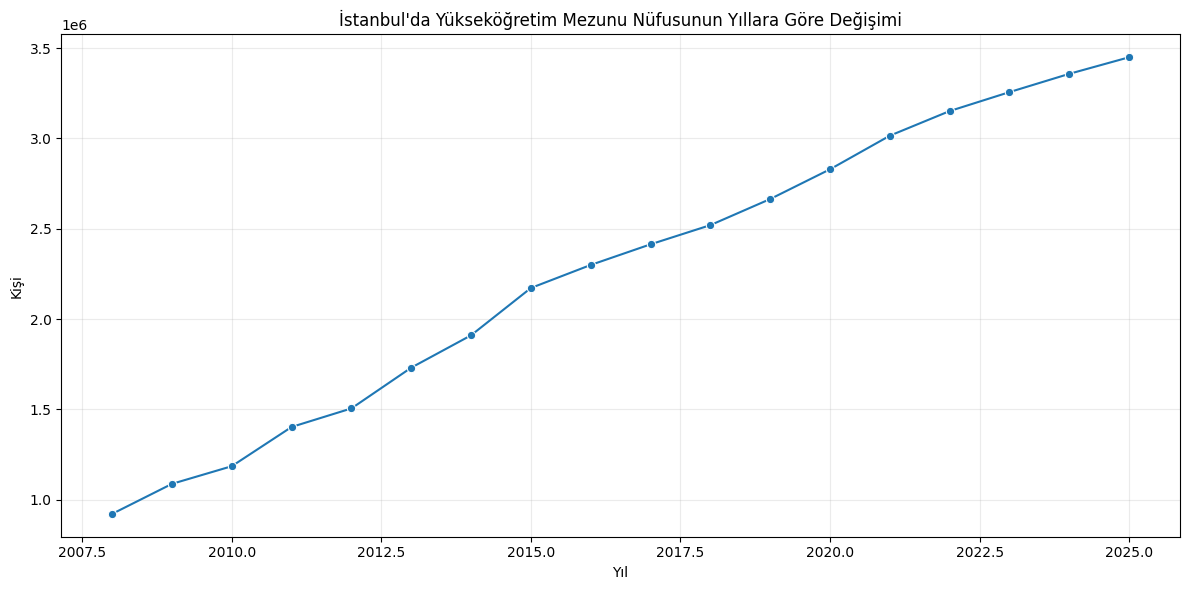

In [ ]:
yuksekogretim_kategorileri = [
    "Yüksekokul veya fakülte",
    "Yüksek lisans (5 veya 6 yıllık fakülteler dahil)",
    "Doktora"
]

if istanbul_egitim is not None and "Eğitim Seviyesi" in istanbul_egitim.columns:
    yuksekogretim = istanbul_egitim[
        istanbul_egitim["Eğitim Seviyesi"].astype(str).isin(yuksekogretim_kategorileri)
    ].copy()

    if "Cinsiyet (DESC)" in yuksekogretim.columns:
        yuksekogretim = yuksekogretim[yuksekogretim["Cinsiyet (DESC)"].astype(str).eq("Toplam")]

    istanbul_yuksekogretim_yillik = (
        yuksekogretim.pivot_table(
            index="Yıl",
            columns="Eğitim Seviyesi",
            values="Gözlem Değeri",
            aggfunc="sum"
        ).reset_index()
    )
    kategori_sutunlari = [c for c in yuksekogretim_kategorileri if c in istanbul_yuksekogretim_yillik.columns]
    istanbul_yuksekogretim_yillik["Toplam Yükseköğretim Mezunu"] = istanbul_yuksekogretim_yillik[kategori_sutunlari].sum(axis=1)
    istanbul_yuksekogretim_yillik = istanbul_yuksekogretim_yillik.sort_values("Yıl")
    display(istanbul_yuksekogretim_yillik)
    istanbul_yuksekogretim_yillik.to_csv(TABLE_DIR / "istanbul_yuksekogretim_yillik.csv", index=False, encoding="utf-8-sig")

    plt.figure(figsize=(12, 6))
    sns.lineplot(data=istanbul_yuksekogretim_yillik, x="Yıl", y="Toplam Yükseköğretim Mezunu", marker="o")
    plt.title("İstanbul'da Yükseköğretim Mezunu Nüfusunun Yıllara Göre Değişimi")
    plt.xlabel("Yıl")
    plt.ylabel("Kişi")
    plt.grid(alpha=.25)
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / "istanbul_yuksekogretim_trendi.png", dpi=200)
    plt.show()

## 7. İstanbul işgücü göstergeleri: istihdam, işsizlik ve katılım

## 7.1. İstanbul İşgücü Piyasası Verilerinin Belirlenmesi

Bu aşamada işgücüne katılma, istihdam ve işsizlik oranlarına ilişkin veri setleri belirlenmiştir. İlgili dosyalar temizlenen veri setleri içerisinden aranmış, bulunan tabloların boyutları ve ilk kayıtları incelenerek sonraki analizler için hazırlanmıştır.

In [ ]:
lab_dosya_eslesmeleri = {
    "İşgücüne Katılma": "il_duzeyinde_isgucune_katilma_orani",
    "İstihdam": "il_duzeyinde_istihdam_orani",
    "İşsizlik": "il_duzeyinde_issizlik_orani"
}

lab_ham = {}
for baslik, anahtar in lab_dosya_eslesmeleri.items():
    eslesen = [(ad, df) for ad, df in temiz_veri_setleri.items() if metin_norm(anahtar) in metin_norm(ad)]
    if eslesen:
        lab_ham[baslik] = eslesen[0][1]
        print("\n", baslik, eslesen[0][0], eslesen[0][1].shape)
        display(eslesen[0][1].head(9))
    else:
        print("Dosya bulunamadı:", anahtar)

Dosya bulunamadı: il_duzeyinde_isgucune_katilma_orani
Dosya bulunamadı: il_duzeyinde_istihdam_orani
Dosya bulunamadı: il_duzeyinde_issizlik_orani


## 7.2. İstanbul İşgücü Göstergelerinin Birleştirilmesi

İstanbul'a ait işgücüne katılma, istihdam ve işsizlik oranları 2022–2025 yılları için ilgili veri setlerinden çıkarılmıştır. Göstergeler yıl değişkeni üzerinden birleştirilerek tek bir tabloda toplanmış ve CSV formatında kaydedilmiştir.

In [ ]:
def istanbul_oranini_cikar(df, oran_adi):
    metin_df = df.astype(str)
    maske = metin_df.apply(lambda s: s.str.contains("TR100", case=False, na=False)).any(axis=1)
    satirlar = df[maske]
    if satirlar.empty:
        raise ValueError(f"{oran_adi}: TR100 satırı bulunamadı. Ham Excel sayfasının üst satırlarını kontrol et.")
    satir = satirlar.iloc[0]
    indeksler = [2, 7, 12, 17]
    yillar = [2022, 2023, 2024, 2025]
    sonuc = []
    for yil, idx in zip(yillar, indeksler):
        deger = pd.to_numeric(pd.Series([satir.iloc[idx]]), errors="coerce").iloc[0]
        sonuc.append({"Yıl": yil, oran_adi: deger})
    return pd.DataFrame(sonuc)

istanbul_isgucu = None
if len(lab_ham) == 3:
    parcalar = []
    for baslik, df in lab_ham.items():
        if baslik == "İşgücüne Katılma":
            ad = "İşgücüne Katılma Oranı (%)"
        elif baslik == "İstihdam":
            ad = "İstihdam Oranı (%)"
        else:
            ad = "İşsizlik Oranı (%)"
        parcalar.append(istanbul_oranini_cikar(df, ad))
    istanbul_isgucu = parcalar[0]
    for parca in parcalar[1:]:
        istanbul_isgucu = istanbul_isgucu.merge(parca, on="Yıl", how="inner")
    istanbul_isgucu = istanbul_isgucu.sort_values("Yıl").reset_index(drop=True)
    display(istanbul_isgucu)
    istanbul_isgucu.to_csv(TABLE_DIR / "istanbul_isgucu_gostergeleri.csv", index=False, encoding="utf-8-sig")

## 8. İstihdam göstergelerinde yıllık değişim
İstanbul'un işgücüne katılma, istihdam ve işsizlik oranlarının 2022–2025 dönemindeki yıllık değişimleri hesaplanmıştır. Oranlar arasındaki farklar yüzde puan cinsinden gösterilmiş ve her gösterge ayrı çizgi grafiklerle görselleştirilmiştir. Tablolar ve grafikler çıktı klasörüne kaydedilmiştir.

In [ ]:
if istanbul_isgucu is not None:
    istihdam_kolonlari = ["İstihdam Oranı (%)", "İşgücüne Katılma Oranı (%)", "İşsizlik Oranı (%)"]
    isgucu_degisim = istanbul_isgucu.sort_values("Yıl").copy()
    for kolon in istihdam_kolonlari:
        isgucu_degisim[kolon + " Değişim (yüzde puan)"] = isgucu_degisim[kolon].diff()
    display(isgucu_degisim.round(2))
    isgucu_degisim.to_excel(TABLE_DIR / "istanbul_isgucu_yillik_degisim.xlsx", index=False)

    for kolon in istihdam_kolonlari:
        plt.figure(figsize=(9, 4.5))
        sns.lineplot(data=istanbul_isgucu, x="Yıl", y=kolon, marker="o")
        plt.title("İstanbul – " + kolon)
        plt.ylabel("Oran (%)")
        plt.grid(alpha=.25)
        plt.tight_layout()
        plt.savefig(FIGURE_DIR / (metin_norm(kolon) + ".png"), dpi=200)
        plt.show()

## 9. İŞKUR açık iş verisinin temizlenmesi

In [ ]:
if iskur is not None:
    print("İŞKUR sütunları:", list(iskur.columns))
    display(iskur.head())

İŞKUR sütunları: ['Meslek', 'İl', 'İlçe', 'Açık İş', 'İlan Linki']


,Meslek,İl,İlçe,Açık İş,İlan Linki
0,Pazarlamacı (telefonla),İstanbul,Avcılar,500,Tıklayınız
1,Beden İşçisi (genel),İstanbul,Tuzla,496,Tıklayınız
2,Beden İşçisi (genel),İstanbul,Arnavutköy,446,Tıklayınız
3,Kasiyer,İstanbul,Üsküdar,258,Tıklayınız
4,Beden İşçisi (genel),İstanbul,Esenyurt,199,Tıklayınız


## 9.2. İŞKUR Verilerinin Temizlenmesi ve İstanbul Kayıtlarının Filtrelenmesi

İŞKUR veri setindeki meslek, il, ilçe ve açık iş bilgileri incelenmiştir. Metinsel alanlar düzenlenmiş, açık iş değerleri sayısal formata dönüştürülmüş ve eksik kayıtlar temizlenmiştir. Ardından yalnızca İstanbul'a ait kayıtlar filtrelenerek ilçe ve açık iş sayıları kontrol edilmiş, temizlenen veriler CSV formatında kaydedilmiştir.

In [ ]:
if iskur is not None:
    beklenen = ["Meslek", "İl", "İlçe", "Açık İş"]
    eksikler = [c for c in beklenen if c not in iskur.columns]
    if eksikler:
        raise ValueError(f"İŞKUR dosyasında beklenen sütunlar eksik: {eksikler}. Sütun adlarını kontrol et.")

    iskur_temiz = iskur.copy()
    for kolon in ["Meslek", "İl", "İlçe"]:
        iskur_temiz[kolon] = iskur_temiz[kolon].astype("string").str.strip()
    iskur_temiz["Açık İş"] = (
        iskur_temiz["Açık İş"].astype(str)
        .str.replace(".", "", regex=False)
        .str.replace(",", ".", regex=False)
    )
    iskur_temiz["Açık İş"] = pd.to_numeric(iskur_temiz["Açık İş"], errors="coerce")
    iskur_temiz = iskur_temiz.dropna(subset=["Meslek", "İl", "İlçe", "Açık İş"])

    iskur_temiz["İl_norm"] = iskur_temiz["İl"].map(lambda x: metin_norm(x))
    iskur_istanbul = iskur_temiz[iskur_temiz["İl_norm"].eq("istanbul")].copy()
    iskur_istanbul["İlçe"] = iskur_istanbul["İlçe"].astype(str).str.strip()
    iskur_istanbul["Meslek"] = iskur_istanbul["Meslek"].astype(str).str.strip()

    print("İstanbul kayıt sayısı:", len(iskur_istanbul))
    print("İlçe sayısı:", iskur_istanbul["İlçe"].nunique())
    print("Toplam açık iş:", int(iskur_istanbul["Açık İş"].sum()))
    display(iskur_istanbul.head())
    iskur_istanbul.to_csv(CLEAN_DIR / "iskur_istanbul_temiz.csv", index=False, encoding="utf-8-sig")

İstanbul kayıt sayısı: 2131
İlçe sayısı: 40
Toplam açık iş: 13292


,Meslek,İl,İlçe,Açık İş,İlan Linki,İl_norm
0,Pazarlamacı (telefonla),İstanbul,Avcılar,500,Tıklayınız,istanbul
1,Beden İşçisi (genel),İstanbul,Tuzla,496,Tıklayınız,istanbul
2,Beden İşçisi (genel),İstanbul,Arnavutköy,446,Tıklayınız,istanbul
3,Kasiyer,İstanbul,Üsküdar,258,Tıklayınız,istanbul
4,Beden İşçisi (genel),İstanbul,Esenyurt,199,Tıklayınız,istanbul


## 10. İstanbul'da açık işlerin ilçe ve mesleklere göre analizi
İŞKUR verileri kullanılarak İstanbul'daki açık iş sayıları ilçe ve meslek bazında gruplandırılmıştır. Açık iş sayısı en yüksek ilçeler ve meslekler belirlenerek ilk 15 kategori grafiklerle görselleştirilmiştir. Elde edilen tablolar ve grafikler çıktı klasörüne kaydedilmiştir.

,İlçe,Açık İş
32,Tuzla,1601
26,Pendik,1220
1,Arnavutköy,1190
21,Kartal,641
15,Esenyurt,619
3,Avcılar,611
37,Üsküdar,598
8,Başakşehir,578
31,Sultangazi,538
27,Sancaktepe,530


,Meslek,Açık İş
50,Beden İşçisi (genel),2300
567,Temizlik Görevlisi,841
298,Kasiyer,516
460,Pazarlamacı (telefonla),500
88,Büro Memuru (genel),318
503,Satış Elemanı / Danışmanı,298
522,Servis Elemanı (garson),290
360,Market Elemanı,289
20,Ambar/Depo Görevlisi,214
315,Konfeksiyon İşçisi,204


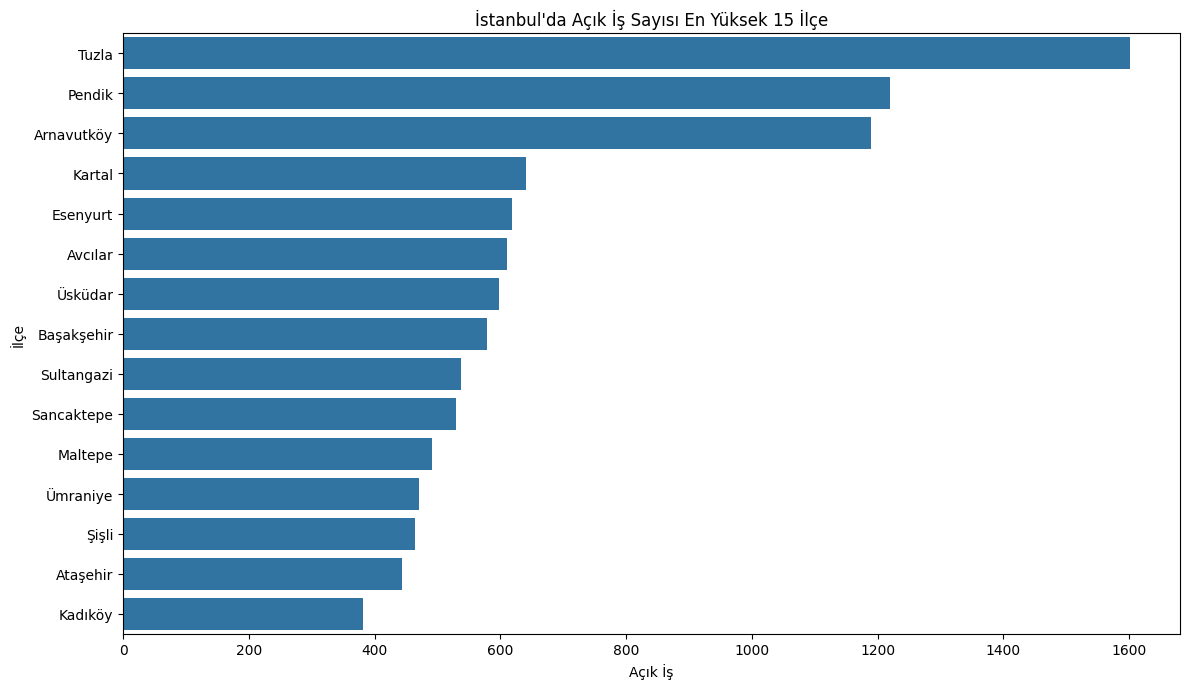

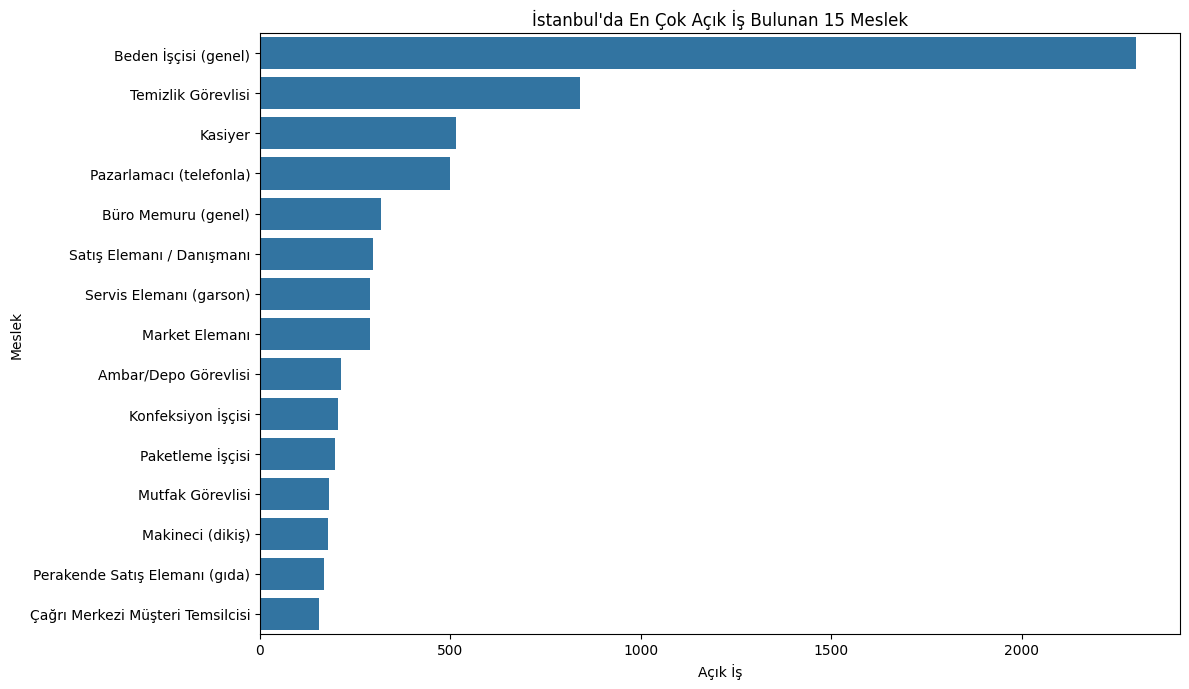

In [ ]:
if iskur is not None:
    ilce_acik_is = (
        iskur_istanbul.groupby("İlçe", as_index=False)["Açık İş"]
        .sum().sort_values("Açık İş", ascending=False)
    )
    meslek_acik_is = (
        iskur_istanbul.groupby("Meslek", as_index=False)["Açık İş"]
        .sum().sort_values("Açık İş", ascending=False)
    )
    display(ilce_acik_is.head(20))
    display(meslek_acik_is.head(20))
    ilce_acik_is.to_csv(TABLE_DIR / "istanbul_ilcelere_gore_acik_is.csv", index=False, encoding="utf-8-sig")
    meslek_acik_is.to_csv(TABLE_DIR / "istanbul_mesleklere_gore_acik_is.csv", index=False, encoding="utf-8-sig")

    plt.figure(figsize=(12, 7))
    sns.barplot(data=ilce_acik_is.head(15), y="İlçe", x="Açık İş")
    plt.title("İstanbul'da Açık İş Sayısı En Yüksek 15 İlçe")
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / "ilcelere_gore_acik_is.png", dpi=200)
    plt.show()

    plt.figure(figsize=(12, 7))
    sns.barplot(data=meslek_acik_is.head(15), y="Meslek", x="Açık İş")
    plt.title("İstanbul'da En Çok Açık İş Bulunan 15 Meslek")
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / "mesleklere_gore_acik_is.png", dpi=200)
    plt.show()

## 11. İlçe–meslek matrisi ve yoğunlaşma analizi
İstanbul'daki ilçelerin meslek bazında açık iş dağılımları incelenmiştir. İlçe ve meslek bilgileri kullanılarak bir açık iş matrisi oluşturulmuş, en fazla talep gören 10 mesleğin ilçelere göre dağılımı ısı haritası (heatmap) ile görselleştirilmiştir.

İlçe-meslek matrisi: (40, 698)


Meslek,Acil Tıp Teknisyeni,Adayhavuzbolumsec,Ahırcı (hayvan Bakan Ve Ahırları Temizleyen),Ahşap Boyama Ve Vernikleme Elemanı,Ahşap Doğrama Cnc Makinesi Operatörü,Ahşap Doğrama Montaj Elemanı,Ahşap Kenar Bantlama Makinesi Operatörü,Ahşap Mobilya İmalat Ustası,Ahşap Mobilya İmalatçısı,Ahşap Montaj Elemanı,Ahşap İşleme Cnc Makinesi Operatörü,Akaryakıt Satış Elemanı (pompacı),Alçı Levha Uygulayıcısı,Alüminyum Doğramacı,Alüminyum Kaynakçısı,Alüminyum Kompozit Cephe Kaplamacısı,Alüminyum İmalat İşçisi,Ambalaj Tasarımı Teknikeri,Ambalajcı (makine İle),Ambalajlama İşçisi (elle),Ambar/Depo Görevlisi,Ameliyathane Hizmetleri Sağlık Teknikeri,Anestezi Sağlık Teknikeri,Anestezi Teknisyeni,Antrenör (spor Eğitmeni),Ara Ütücü,Araç Filo Sorumlusu,Araç Kabul Görevlisi,Arge Elemanı,Argon Kaynakçısı (tig Kaynakçısı),Arşiv Destek Elemanı,Asansör Bakım Ve Onarım Ustası,Asansör Bakım Ve Onarım İşçisi,Asansör Montaj İşçisi,Asfalt İşçisi,Avukat,Ayakkabı Yapımcısı/Ayakkabı İmalatçısı,Ayakçı (tekstil),Aşçı,Aşçı (özel Hizmet),Aşçı Yamağı (çırağı),Aşçı Yardımcısı,Aşçıbaşı Yardımcısı,Bagaj Taşıyıcısı (bellboy),Bahçıvan,Balık Temizleme İşçisi,Banka Gişe Yetkilisi,Bant Elemanı,Bant Şefi (tekstil),Baskı Operatörü - Tekstil,...,Özlük İşleri Personeli,Özlük İşleri Uzmanı,Üniversal Freze Tezgâhı Ayarcı-Operatörü (metal İşçiliği),Üniversal Torna Tezgahı Operatörü,Üretim Planlama Memuru,Üretim Ve Planlama Mühendisi,Üretim Ve Planlama Uzman Yardımcısı,Üretim Şefi,Üretimde Kalite Kontrol Teknikeri,Ürün Dolum Makinesi Operatörü (kozmetik),Ütücü,Üç Boyutlu Ölçüm (cmm) Operatörü,İdari Büro Görevlisi,İdari Destek Görevlisi,İdari İşler Uzmanı,İklimlendirme Sistemleri Elemanı,İklimlendirme Ve Soğutma Teknolojisi Teknikeri,İkram Hizmetleri (yiyecek İçecek İşletmeciliği) Meslek Elemanı,İlaç Üretim Operatörü,İletişim Uzmanı,İlik Düğmeci/İlik Düğme Otomatçı,İmalat İşçisi,İngilizce Öğretmeni,İnsan Kaynakları Uzmanı (yöneticisi),İnsan Kaynakları Uzmanı/Personel Uzmanı,İnsan Kaynakları Yönetimi Meslek Elemanı,İnşaat Mühendisi,İnşaat Teknolojisi Teknikeri,İnşaat İşçisi,İnşaat/İşyeri Bekçisi,İplik Temizleme İşçisi,İskele Kurulum Elemanı,İthalat-İhracat Meslek Elemanı,İthalat-İhracat Müdürü,İzabeci (metal Ergitme) (kupola Hariç),İç Giyim Modelisti,İç Mimar,İş Güvenliği Uzmanı,İş Güvenliği Uzmanı (az Tehlikeli Sınıf-C),İş Makineleri Motor Ve Aktarma Organları Bakım-Onarımcısı,İş Makineleri Operatörü,İş Sağlığı Ve Güvenliği Elemanı (inşaat),İş Sağlığı Ve Güvenliği Teknikeri,İşe Alım Personeli,İşletme Elektrik Bakım Ustası,İşletme Mühendisi,İşletme Yönetimi Meslek Elemanı,Şerit Testere Tezgahı Operatörü-Bıçkı Fabrikası,Şoför (yolcu Taşıma),Şoför-Yük Taşıma
İlçe,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
Adalar,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Arnavutköy,0,0,0,1,0,10,0,3,0,0,0,7,0,0,0,0,1,0,4,0,43,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,1,0,0,2,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,10,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,5,12
Ataşehir,1,0,0,0,0,0,0,0,0,0,0,3,0,0,0,0,0,0,0,0,10,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,3,0,0,3,0,0,0,2,3,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,1
Avcılar,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,10,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Bahçelievler,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


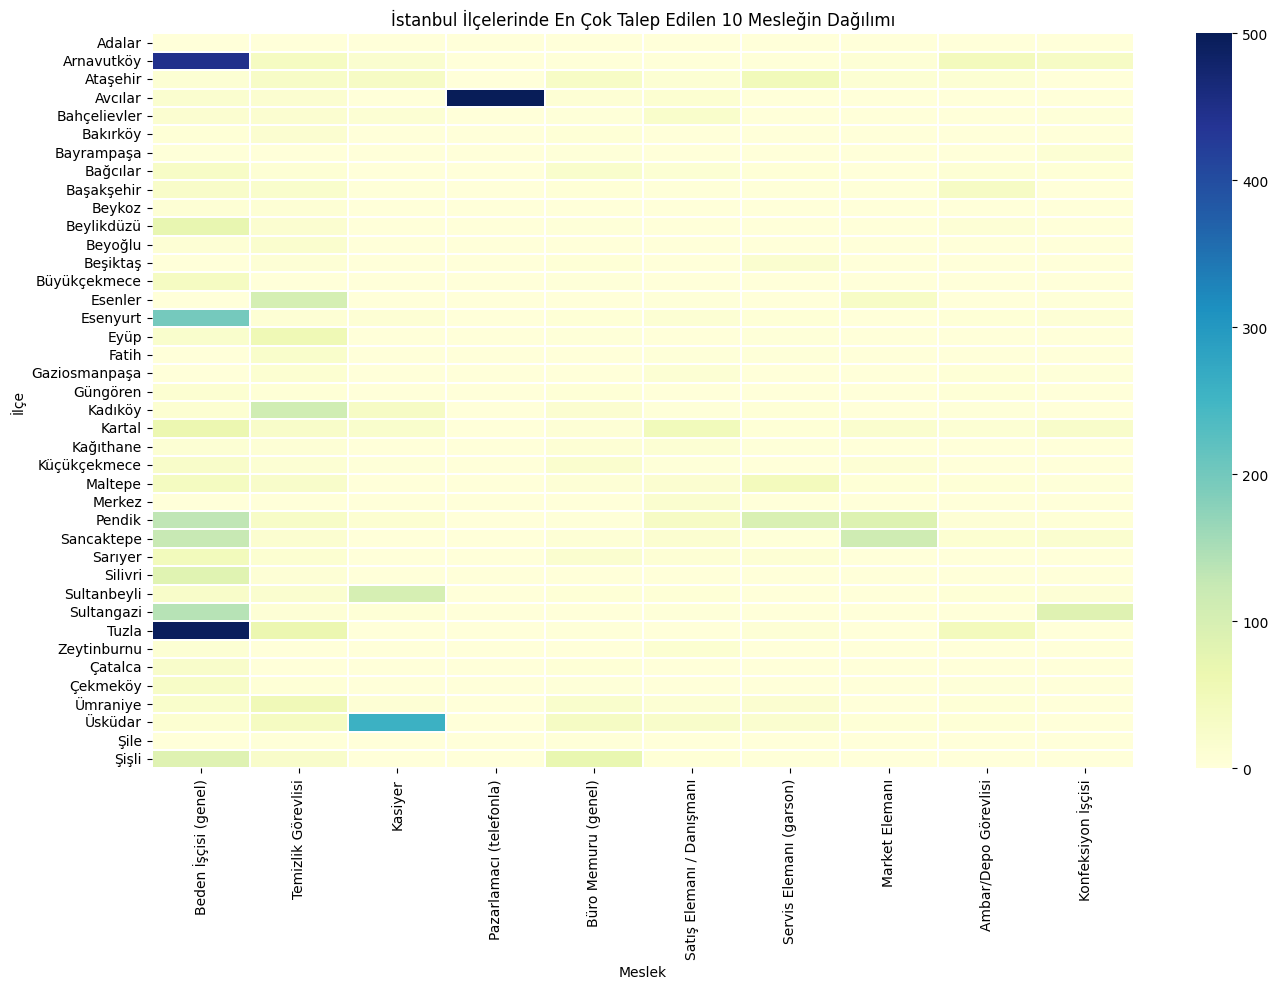

In [ ]:
if iskur is not None:
    ilce_meslek = pd.pivot_table(
        iskur_istanbul,
        index="İlçe",
        columns="Meslek",
        values="Açık İş",
        aggfunc="sum",
        fill_value=0
    )
    ilce_meslek.to_csv(TABLE_DIR / "istanbul_ilce_meslek_matrisi.csv", encoding="utf-8-sig")
    print("İlçe-meslek matrisi:", ilce_meslek.shape)
    display(ilce_meslek.head())

    top_meslekler = meslek_acik_is.head(10)["Meslek"].tolist()
    ilce_meslek_top10 = ilce_meslek.reindex(columns=top_meslekler, fill_value=0)

    plt.figure(figsize=(14, 10))
    sns.heatmap(ilce_meslek_top10, cmap="YlGnBu", linewidths=.2)
    plt.title("İstanbul İlçelerinde En Çok Talep Edilen 10 Mesleğin Dağılımı")
    plt.xlabel("Meslek")
    plt.ylabel("İlçe")
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / "ilce_meslek_isiharitasi.png", dpi=200)
    plt.show()

## 12. Makine öğrenmesi öncesi özellik mühendisliği
İstanbul ilçelerindeki en çok talep gören 10 mesleğin açık iş sayıları kullanılarak makine öğrenmesi veri seti oluşturulmuştur. İlçelerin meslek dağılımları oranlara dönüştürülerek farklı büyüklükteki ilçelerin karşılaştırılabilir olması sağlanmıştır. Açık iş bulunmayan ilçeler ve merkez kayıtları çıkarılarak K-Means kümeleme algoritmasında kullanılacak özellik matrisi hazırlanmıştır.

In [ ]:
if iskur is not None:
    ilce_toplam = ilce_meslek_top10.sum(axis=1)
    meslek_oranlari = ilce_meslek_top10.div(ilce_toplam.replace(0, np.nan), axis=0).fillna(0)
    model_verisi = meslek_oranlari.copy()
    model_verisi["Toplam Açık İş"] = ilce_toplam
    model_verisi = model_verisi[model_verisi["Toplam Açık İş"] > 0].copy()
    model_verisi = model_verisi[~model_verisi.index.astype(str).str.contains("merkez", case=False)].copy()

    X = model_verisi.drop(columns=["Toplam Açık İş"])
    print("Model veri boyutu:", X.shape)
    display(model_verisi.head())

Model veri boyutu: (39, 10)


Meslek,Beden İşçisi (genel),Temizlik Görevlisi,Kasiyer,Pazarlamacı (telefonla),Büro Memuru (genel),Satış Elemanı / Danışmanı,Servis Elemanı (garson),Market Elemanı,Ambar/Depo Görevlisi,Konfeksiyon İşçisi,Toplam Açık İş
İlçe,,,,,,,,,,,
Adalar,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1
Arnavutköy,0.755932,0.062712,0.028814,0.000000,0.005085,0.003390,0.005085,0.010169,0.072881,0.055932,590
Ataşehir,0.060773,0.154696,0.182320,0.000000,0.165746,0.055249,0.265193,0.060773,0.055249,0.000000,181
Avcılar,0.030686,0.025271,0.000000,0.902527,0.016245,0.021661,0.000000,0.000000,0.001805,0.001805,554
Bahçelievler,0.223881,0.223881,0.164179,0.000000,0.029851,0.328358,0.000000,0.000000,0.000000,0.029851,67


## 13. K-Means kümeleme ve küme sayısının seçimi
İlçelerin meslek dağılımlarına göre benzerliklerini belirlemek amacıyla K-Means algoritması uygulanmıştır. Farklı küme sayıları (K=2–8) denenerek her modelin Silhouette Score değeri hesaplanmıştır. Ayrıca kümelerdeki en küçük ve en büyük gözlem sayıları incelenerek uygun küme sayısının belirlenmesi amaçlanmıştır.

,Küme Sayısı,Silhouette Score,En Küçük Küme,En Büyük Küme
0,2,0.289807,15,24
1,3,0.320516,10,19
2,4,0.332364,1,18
3,5,0.376787,1,16
4,6,0.369034,1,13
5,7,0.377053,1,13
6,8,0.370648,1,9


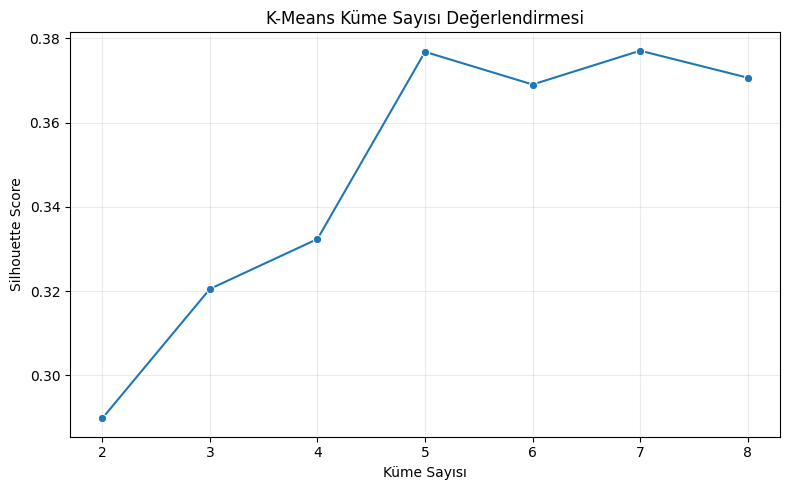

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

if iskur is not None and len(X) >= 3:
    k_sonuclari = []
    max_k = min(8, len(X) - 1)
    for k in range(2, max_k + 1):
        model = KMeans(n_clusters=k, random_state=42, n_init=20)
        etiket = model.fit_predict(X)
        skor = silhouette_score(X, etiket)
        k_sonuclari.append({
            "Küme Sayısı": k,
            "Silhouette Score": skor,
            "En Küçük Küme": int(pd.Series(etiket).value_counts().min()),
            "En Büyük Küme": int(pd.Series(etiket).value_counts().max())
        })
    k_degerlendirme = pd.DataFrame(k_sonuclari)
    display(k_degerlendirme)
    k_degerlendirme.to_csv(TABLE_DIR / "kume_sayisi_degerlendirme.csv", index=False, encoding="utf-8-sig")

    plt.figure(figsize=(8, 5))
    sns.lineplot(data=k_degerlendirme, x="Küme Sayısı", y="Silhouette Score", marker="o")
    plt.title("K-Means Küme Sayısı Değerlendirmesi")
    plt.grid(alpha=.25)
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / "silhouette_karsilastirma.png", dpi=200)
    plt.show()

## 13.1. Nihai K-Means Modelinin Oluşturulması ve İlçelerin Kümelenmesi

Değerlendirme sonuçları doğrultusunda 3 kümeli K-Means modeli oluşturulmuştur. Model kullanılarak İstanbul ilçeleri meslek dağılımlarındaki benzerliklere göre gruplandırılmıştır. Her kümedeki ilçe sayıları ve ilçelerin küme dağılımları incelenerek sonuçlar CSV formatında kaydedilmiştir.

In [ ]:
if iskur is not None and len(X) >= 3:
    SECILEN_K = 3
    kmeans_final = KMeans(n_clusters=SECILEN_K, random_state=42, n_init=20)
    model_verisi["Küme"] = kmeans_final.fit_predict(X)

    kume_buyuklukleri = model_verisi["Küme"].value_counts().sort_index().rename("İlçe Sayısı").to_frame()
    display(kume_buyuklukleri)
    display(model_verisi.sort_values(["Küme", "Toplam Açık İş"], ascending=[True, False]))

    model_verisi.reset_index(names="İlçe").to_csv(TABLE_DIR / "istanbul_ilce_kumeleri.csv", index=False, encoding="utf-8-sig")

,İlçe Sayısı
Küme,
0,19
1,10
2,10


Meslek,Beden İşçisi (genel),Temizlik Görevlisi,Kasiyer,Pazarlamacı (telefonla),Büro Memuru (genel),Satış Elemanı / Danışmanı,Servis Elemanı (garson),Market Elemanı,Ambar/Depo Görevlisi,Konfeksiyon İşçisi,Toplam Açık İş,Küme
İlçe,,,,,,,,,,,,
Avcılar,0.030686,0.025271,0.000000,0.902527,0.016245,0.021661,0.000000,0.000000,0.001805,0.001805,554,0
Pendik,0.325926,0.071605,0.032099,0.000000,0.007407,0.081481,0.237037,0.217284,0.014815,0.012346,405,0
Üsküdar,0.033248,0.092072,0.659847,0.000000,0.086957,0.061381,0.043478,0.012788,0.010230,0.000000,391,0
Sancaktepe,0.411960,0.046512,0.000000,0.000000,0.019934,0.046512,0.006645,0.375415,0.039867,0.053156,301,0
Kartal,0.290179,0.120536,0.089286,0.000000,0.031250,0.209821,0.017857,0.080357,0.049107,0.111607,224,0
Şişli,0.467742,0.129032,0.000000,0.000000,0.370968,0.021505,0.010753,0.000000,0.000000,0.000000,186,0
Ataşehir,0.060773,0.154696,0.182320,0.000000,0.165746,0.055249,0.265193,0.060773,0.055249,0.000000,181,0
Sultanbeyli,0.161491,0.105590,0.621118,0.000000,0.024845,0.024845,0.000000,0.000000,0.024845,0.037267,161,0
Maltepe,0.280576,0.172662,0.000000,0.000000,0.043165,0.107914,0.316547,0.028777,0.035971,0.014388,139,0


### 13.2. K-Means Modelinin Ölçeklendirme ile Sağlamlık Analizi

K-Means algoritması, değişkenlerin ölçeklerinden etkilenebildiği için modelin ölçeklendirilmiş ve ölçeklendirilmemiş veriler üzerindeki performansı karşılaştırılmıştır. Bu karşılaştırmada Silhouette Score, Davies-Bouldin Index ve Calinski-Harabasz Index metriklerinden yararlanılmıştır. Böylece seçilen küme sayısının ve model sonuçlarının farklı veri hazırlama koşullarındaki tutarlılığı değerlendirilmiştir.

In [ ]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

SECILEN_K = 3

X_kontrol = X.copy()

X_kontrol = X_kontrol.replace([np.inf, -np.inf], np.nan)
X_kontrol = X_kontrol.fillna(0)

olcekleyici = StandardScaler()
X_olcekli = olcekleyici.fit_transform(X_kontrol)

kmeans_olceksiz = KMeans(
    n_clusters=SECILEN_K,
    random_state=42,
    n_init=20
)

kmeans_olcekli = KMeans(
    n_clusters=SECILEN_K,
    random_state=42,
    n_init=20
)

etiket_olceksiz = kmeans_olceksiz.fit_predict(X_kontrol)
etiket_olcekli = kmeans_olcekli.fit_predict(X_olcekli)

saglamlik_sonuclari = []

for ad, veri, etiket in [
    ("Ölçeklendirilmemiş", X_kontrol, etiket_olceksiz),
    ("StandardScaler uygulanmış", X_olcekli, etiket_olcekli)
]:
    saglamlik_sonuclari.append({
        "Model": ad,
        "Küme Sayısı": SECILEN_K,
        "Silhouette Score": silhouette_score(veri, etiket),
        "Davies-Bouldin Index": davies_bouldin_score(veri, etiket),
        "Calinski-Harabasz Index": calinski_harabasz_score(veri, etiket)
    })

saglamlik_sonuclari = pd.DataFrame(saglamlik_sonuclari)

display(
    saglamlik_sonuclari.round(4)
)

saglamlik_sonuclari.to_csv(
    TABLE_DIR / "kmeans_olceklendirme_karsilastirmasi.csv",
    index=False,
    encoding="utf-8-sig"
)

,Model,Küme Sayısı,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,Ölçeklendirilmemiş,3,0.3205,1.1752,18.4245
1,StandardScaler uygulanmış,3,0.1619,1.5533,5.9274


## 13.3.Elbow (Dirsek) Yöntemi

Elbow yöntemi, K-Means algoritmasında uygun küme sayısını belirlemek amacıyla kullanılır. Her küme sayısı için küme içi hata kareleri toplamı (Inertia / WCSS) hesaplanır.

Küme sayısı arttıkça Inertia değeri azalır. Ancak belirli bir noktadan sonra azalış hızı yavaşlar. Grafikte bu kırılma noktasına dirsek noktası adı verilir.

,Küme Sayısı,Inertia
0,2,6.077648
1,3,4.536550
2,4,3.649864
3,5,2.878626
4,6,2.410581
5,7,2.093194
6,8,1.723011


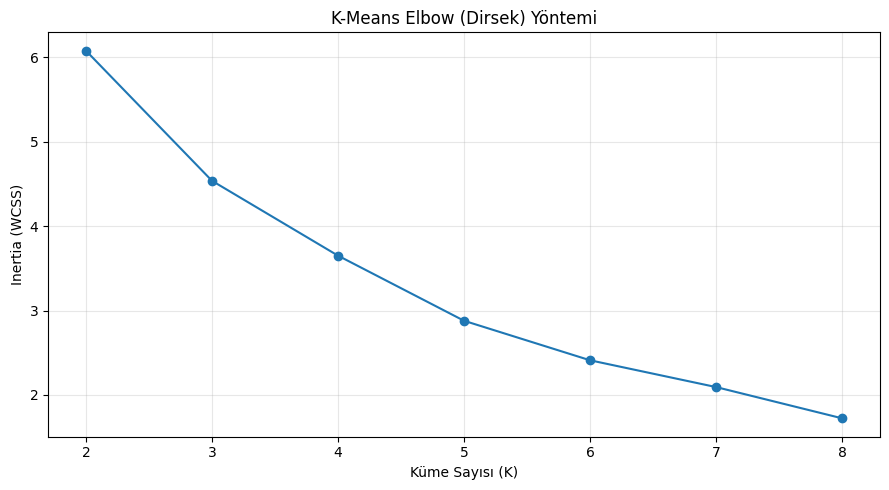

In [ ]:
from sklearn.cluster import KMeans
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

X_ml = np.asarray(X, dtype=float)

if iskur is not None and len(X_ml) >= 3:
    k_degerleri = range(2, min(8, len(X_ml) - 1) + 1)

    inertia_sonuclari = []

    for k in k_degerleri:
        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=20
        )

        model.fit(X_ml)

        inertia_sonuclari.append({
            "Küme Sayısı": k,
            "Inertia": model.inertia_
        })

    elbow_df = pd.DataFrame(inertia_sonuclari)

    display(elbow_df)

    plt.figure(figsize=(9, 5))
    plt.plot(
        elbow_df["Küme Sayısı"],
        elbow_df["Inertia"],
        marker="o"
    )

    plt.title("K-Means Elbow (Dirsek) Yöntemi")
    plt.xlabel("Küme Sayısı (K)")
    plt.ylabel("Inertia (WCSS)")
    plt.xticks(list(k_degerleri))
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(
        FIGURE_DIR / "elbow_dirsek_yontemi.png",
        dpi=200
    )
    plt.show()

## 13.4. Davies-Bouldin Index ile Kümeleme Değerlendirmesi

Davies-Bouldin Index, oluşturulan kümelerin kendi içlerinde ne kadar benzer ve birbirlerinden ne kadar farklı olduğunu değerlendirmek için kullanılır.

Bu ölçütte düşük değerler daha iyi kümeleme performansına işaret eder. Değerin düşük olması, kümelerin kendi içlerinde daha tutarlı ve birbirlerinden daha ayrışmış olduğunu gösterir.

,Küme Sayısı,Davies-Bouldin Index
0,2,1.1666
1,3,1.1752
2,4,0.9309
3,5,0.8188
4,6,0.8510
5,7,0.7176
6,8,0.8837


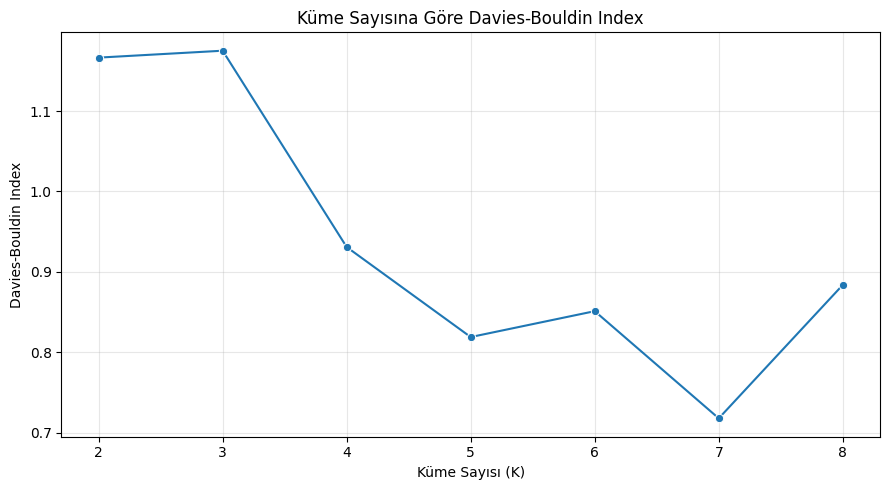

In [ ]:
from sklearn.metrics import davies_bouldin_score

if iskur is not None and len(X_ml) >= 3:
    db_sonuclari = []

    for k in k_degerleri:
        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=20
        )

        etiket = model.fit_predict(X_ml)

        db_skoru = davies_bouldin_score(X_ml, etiket)

        db_sonuclari.append({
            "Küme Sayısı": k,
            "Davies-Bouldin Index": db_skoru
        })

    db_df = pd.DataFrame(db_sonuclari)

    display(db_df.round(4))

    plt.figure(figsize=(9, 5))
    sns.lineplot(
        data=db_df,
        x="Küme Sayısı",
        y="Davies-Bouldin Index",
        marker="o"
    )

    plt.title("Küme Sayısına Göre Davies-Bouldin Index")
    plt.xlabel("Küme Sayısı (K)")
    plt.ylabel("Davies-Bouldin Index")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(
        FIGURE_DIR / "davies_bouldin_karsilastirma.png",
        dpi=200
    )
    plt.show()

## 13.5. Calinski-Harabasz Index ile Kümeleme Değerlendirmesi

Calinski-Harabasz Index, kümeler arası ayrışmayı ve kümelerin kendi içindeki dağılımını karşılaştırarak kümeleme kalitesini değerlendirir.

Bu ölçütte yüksek değerler genellikle daha iyi kümeleme performansına işaret eder. Küme sayısı belirlenirken diğer değerlendirme ölçütleriyle birlikte yorumlanır.

,Küme Sayısı,Calinski-Harabasz Index
0,2,18.8872
1,3,18.4245
2,4,17.6772
3,5,18.6069
4,6,18.5344
5,7,18.0570
6,8,19.1665


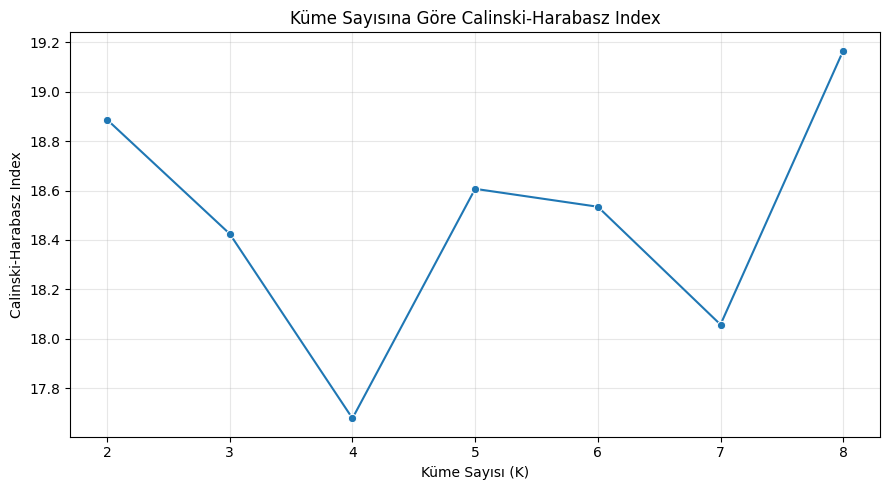

In [ ]:
from sklearn.metrics import calinski_harabasz_score

if iskur is not None and len(X_ml) >= 3:
    ch_sonuclari = []

    for k in k_degerleri:
        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=20
        )

        etiket = model.fit_predict(X_ml)

        ch_skoru = calinski_harabasz_score(X_ml, etiket)

        ch_sonuclari.append({
            "Küme Sayısı": k,
            "Calinski-Harabasz Index": ch_skoru
        })

    ch_df = pd.DataFrame(ch_sonuclari)

    display(ch_df.round(4))

    plt.figure(figsize=(9, 5))
    sns.lineplot(
        data=ch_df,
        x="Küme Sayısı",
        y="Calinski-Harabasz Index",
        marker="o"
    )

    plt.title("Küme Sayısına Göre Calinski-Harabasz Index")
    plt.xlabel("Küme Sayısı (K)")
    plt.ylabel("Calinski-Harabasz Index")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(
        FIGURE_DIR / "calinski_harabasz_karsilastirma.png",
        dpi=200
    )
    plt.show()

## 13.6. K-Means Kümeleme Performans Ölçütlerinin Karşılaştırılması

Elbow yöntemi, Silhouette Score, Davies-Bouldin Index ve Calinski-Harabasz Index birlikte değerlendirilerek farklı küme sayılarının performansı karşılaştırılır.

- Inertia: Daha düşük değer tercih edilir; ancak küme sayısı arttıkça doğal olarak azalır.
- Silhouette Score: Yüksek değer tercih edilir.
- Davies-Bouldin Index: Düşük değer tercih edilir.
- Calinski-Harabasz Index: Yüksek değer tercih edilir.

Küme sayısı yalnızca tek bir metriğe göre belirlenmez. Küme büyüklükleri, dağılım dengesi ve kümelerin yorumlanabilirliği de dikkate alınır.

In [ ]:
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

if iskur is not None and len(X_ml) >= 3:
    karsilastirma_sonuclari = []

    for k in k_degerleri:
        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=20
        )

        etiket = model.fit_predict(X_ml)

        karsilastirma_sonuclari.append({
            "Küme Sayısı": k,
            "Inertia": model.inertia_,
            "Silhouette Score": silhouette_score(X_ml, etiket),
            "Davies-Bouldin Index": davies_bouldin_score(X_ml, etiket),
            "Calinski-Harabasz Index": calinski_harabasz_score(X_ml, etiket),
            "En Küçük Küme": int(pd.Series(etiket).value_counts().min()),
            "En Büyük Küme": int(pd.Series(etiket).value_counts().max())
        })

    ml_karsilastirma = pd.DataFrame(karsilastirma_sonuclari)

    display(ml_karsilastirma.round(4))

    ml_karsilastirma.to_csv(
        TABLE_DIR / "makine_ogrenmesi_metrik_karsilastirmasi.csv",
        index=False,
        encoding="utf-8-sig"
    )

    print("Metrik karşılaştırma tablosu kaydedildi.")

,Küme Sayısı,Inertia,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index,En Küçük Küme,En Büyük Küme
0,2,6.0776,0.2898,1.1666,18.8872,15,24
1,3,4.5366,0.3205,1.1752,18.4245,10,19
2,4,3.6499,0.3324,0.9309,17.6772,1,18
3,5,2.8786,0.3768,0.8188,18.6069,1,16
4,6,2.4106,0.3690,0.8510,18.5344,1,13
5,7,2.0932,0.3771,0.7176,18.0570,1,13
6,8,1.7230,0.3706,0.8837,19.1665,1,9


Metrik karşılaştırma tablosu kaydedildi.



## 13.7. K-Means Kümeleme Kararlılığının Analizi

Bu bölümde K-Means algoritmasının farklı rastgele başlangıç değerleri altında oluşturduğu kümelerin tutarlılığı incelenmiştir. Farklı random_state değerleriyle modeller yeniden eğitilmiş ve elde edilen küme etiketleri Adjusted Rand Index (ARI) metriği kullanılarak karşılaştırılmıştır.

ARI değerinin 1'e yaklaşması, iki kümeleme sonucunun yüksek düzeyde benzer olduğunu göstermektedir.


In [ ]:

from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from itertools import combinations

rastgele_durumlar = [0, 10, 21, 42, 50, 75, 100, 123, 2026]

kararlilik_etiketleri = {}

for durum in rastgele_durumlar:
    model = KMeans(
        n_clusters=3,
        random_state=durum,
        n_init=1
    )
    kararlilik_etiketleri[durum] = model.fit_predict(X_kontrol)

ari_sonuclari = []

for durum1, durum2 in combinations(rastgele_durumlar, 2):
    ari = adjusted_rand_score(
        kararlilik_etiketleri[durum1],
        kararlilik_etiketleri[durum2]
    )

    ari_sonuclari.append({
        "İlk Başlangıç": durum1,
        "İkinci Başlangıç": durum2,
        "Adjusted Rand Index": ari
    })

ari_karsilastirma = pd.DataFrame(ari_sonuclari)

print("Farklı başlangıç değerlerine göre kümeleme benzerlikleri:")
display(ari_karsilastirma.round(4))

print("\nKararlılık özeti:")
display(
    ari_karsilastirma["Adjusted Rand Index"]
    .describe()
    .to_frame("ARI İstatistikleri")
    .round(4)
)

print(
    "\nOrtalama ARI:",
    round(ari_karsilastirma["Adjusted Rand Index"].mean(), 4)
)

print(
    "Minimum ARI:",
    round(ari_karsilastirma["Adjusted Rand Index"].min(), 4)
)

print(
    "Maksimum ARI:",
    round(ari_karsilastirma["Adjusted Rand Index"].max(), 4)
)

ari_karsilastirma.to_csv(
    TABLE_DIR / "kmeans_kararlilik_analizi.csv",
    index=False,
    encoding="utf-8-sig"
)


Farklı başlangıç değerlerine göre kümeleme benzerlikleri:


,İlk Başlangıç,İkinci Başlangıç,Adjusted Rand Index
0,0,10,0.7656
1,0,21,0.7656
2,0,42,0.5687
3,0,50,0.7656
4,0,75,1.0000
5,0,100,0.6267
6,0,123,0.7656
7,0,2026,0.7656
8,10,21,1.0000
9,10,42,0.7946



Kararlılık özeti:


,ARI İstatistikleri
count,36.0000
mean,0.7721
std,0.1598
min,0.4374
25%,0.6267
50%,0.7656
75%,0.8555
max,1.0000



Ortalama ARI: 0.7721
Minimum ARI: 0.4374
Maksimum ARI: 1.0



## 13.8. Alternatif Kümeleme Algoritması ile Model Karşılaştırması

Bu bölümde K-Means algoritmasının sonuçlarını karşılaştırmak amacıyla Agglomerative Clustering yöntemi uygulanmıştır.

Hiyerarşik kümeleme algoritması kullanılarak İstanbul ilçeleri meslek gruplarına göre yeniden kümelendirilmiştir. Her iki algoritma aynı veri matrisi ve aynı küme sayısı üzerinden değerlendirilmiş; Silhouette Score, Davies-Bouldin Index ve Calinski-Harabasz Index ölçütleri karşılaştırılmıştır.

Böylece ilçelerin açık iş dağılımlarına göre gruplandırılmasında farklı kümeleme yaklaşımlarının performansları incelenmiştir.


In [ ]:

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score
)

hiyerarsik_model = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward"
)

hiyerarsik_etiketler = hiyerarsik_model.fit_predict(X_kontrol)

kmeans_son_etiketler = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=20
).fit_predict(X_kontrol)

algoritma_karsilastirma = pd.DataFrame([
    {
        "Algoritma": "K-Means",
        "Küme Sayısı": 3,
        "Silhouette Score": silhouette_score(
            X_kontrol, kmeans_son_etiketler
        ),
        "Davies-Bouldin Index": davies_bouldin_score(
            X_kontrol, kmeans_son_etiketler
        ),
        "Calinski-Harabasz Index": calinski_harabasz_score(
            X_kontrol, kmeans_son_etiketler
        )
    },
    {
        "Algoritma": "Agglomerative Clustering",
        "Küme Sayısı": 3,
        "Silhouette Score": silhouette_score(
            X_kontrol, hiyerarsik_etiketler
        ),
        "Davies-Bouldin Index": davies_bouldin_score(
            X_kontrol, hiyerarsik_etiketler
        ),
        "Calinski-Harabasz Index": calinski_harabasz_score(
            X_kontrol, hiyerarsik_etiketler
        )
    }
])

print("Kümeleme algoritmalarının performans karşılaştırması:")
display(algoritma_karsilastirma.round(4))

print("\nİki algoritmanın küme üyelikleri arasındaki benzerlik:")
print(
    round(
        adjusted_rand_score(
            kmeans_son_etiketler,
            hiyerarsik_etiketler
        ),
        4
    )
)

print("\nAgglomerative Clustering küme dağılımı:")
display(
    pd.Series(hiyerarsik_etiketler)
    .value_counts()
    .sort_index()
    .rename("İlçe Sayısı")
    .to_frame()
)

algoritma_karsilastirma.to_csv(
    TABLE_DIR / "kumeleme_algoritmalari_karsilastirmasi.csv",
    index=False,
    encoding="utf-8-sig"
)


Kümeleme algoritmalarının performans karşılaştırması:


,Algoritma,Küme Sayısı,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means,3,0.3205,1.1752,18.4245
1,Agglomerative Clustering,3,0.3073,1.1142,17.3588



İki algoritmanın küme üyelikleri arasındaki benzerlik:
0.8345

Agglomerative Clustering küme dağılımı:


,İlçe Sayısı
0,21
1,9
2,9


## 14. K-Means Küme Profillerinin İncelenmesi

Oluşturulan kümelerin meslek dağılımları karşılaştırılarak her kümenin karakteristik özellikleri belirlenmiştir. Kümelerdeki meslek oranlarının ortalamaları hesaplanmış ve sonuçlar ısı haritası ile görselleştirilmiştir. Böylece ilçelerin hangi meslek gruplarında yoğunlaştığı incelenmiştir.

Meslek,Beden İşçisi (genel),Temizlik Görevlisi,Kasiyer,Pazarlamacı (telefonla),Büro Memuru (genel),Satış Elemanı / Danışmanı,Servis Elemanı (garson),Market Elemanı,Ambar/Depo Görevlisi,Konfeksiyon İşçisi
Küme,,,,,,,,,,
0,0.269,0.121,0.098,0.048,0.117,0.109,0.094,0.052,0.046,0.045
1,0.150,0.582,0.029,0.000,0.083,0.066,0.027,0.022,0.024,0.016
2,0.808,0.058,0.011,0.000,0.033,0.006,0.006,0.001,0.030,0.046


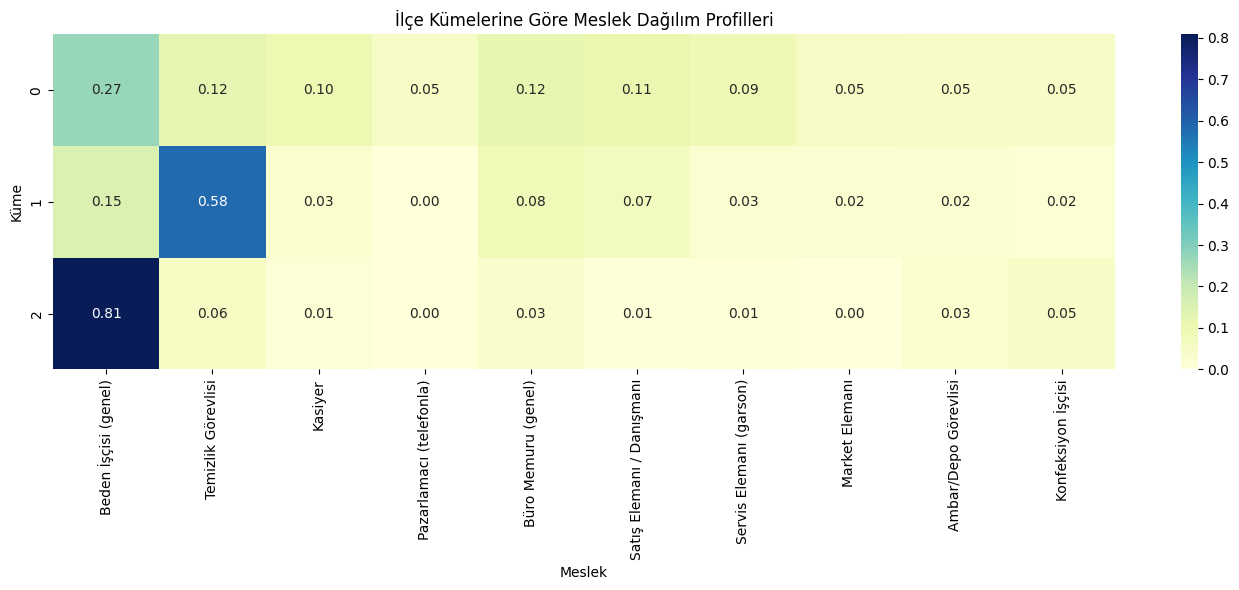

In [ ]:
if iskur is not None and "Küme" in model_verisi.columns:
    kume_profilleri = model_verisi.groupby("Küme")[X.columns].mean()
    display(kume_profilleri.round(3))
    kume_profilleri.to_csv(TABLE_DIR / "istanbul_kume_profilleri.csv", encoding="utf-8-sig")

    plt.figure(figsize=(14, 6))
    sns.heatmap(kume_profilleri, annot=True, fmt=".2f", cmap="YlGnBu")
    plt.title("İlçe Kümelerine Göre Meslek Dağılım Profilleri")
    plt.xlabel("Meslek")
    plt.ylabel("Küme")
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / "kume_profilleri.png", dpi=200)
    plt.show()

### 14.1. Kümelere Göre Öne Çıkan Mesleklerin Analizi

K-Means algoritması sonucunda elde edilen ilçe kümelerinin mesleki talep yapıları ayrıca incelenmiştir. Her kümede yer alan ilçelerin İŞKUR açık iş kayıtları bir araya getirilerek en fazla açık iş sayısına sahip ilk üç meslek belirlenmiştir. Böylece kümeler yalnızca sayısal profilleriyle değil, öne çıkan meslek talepleriyle de yorumlanmıştır.

In [ ]:
# Küme ve ilçe sütunlarını kontrol et
print("Model verisi sütunları:")
print(model_verisi.columns.tolist())

print("\nİŞKUR veri seti sütunları:")
print(iskur_istanbul.columns.tolist())

# Küme bilgilerini hazırla
ilce_kume = model_verisi.reset_index()

if "İlçe" not in ilce_kume.columns:
    olasi_ilce = [
        sutun for sutun in ilce_kume.columns
        if "ilçe" in sutun.lower() or "ilce" in sutun.lower()
    ]

    if olasi_ilce:
        ilce_kume = ilce_kume.rename(
            columns={olasi_ilce[0]: "İlçe"}
        )

if "Küme" not in ilce_kume.columns:
    olasi_kume = [
        sutun for sutun in ilce_kume.columns
        if "küme" in sutun.lower() or "kume" in sutun.lower()
    ]

    if olasi_kume:
        ilce_kume = ilce_kume.rename(
            columns={olasi_kume[0]: "Küme"}
        )

if not {"İlçe", "Küme"}.issubset(ilce_kume.columns):
    raise ValueError(
        "Model verisinde İlçe ve Küme sütunları bulunamadı. "
        "Sütun adlarını kontrol et."
    )

# İŞKUR verisini ilçe ve meslek bazında özetle
meslek_ilce_ozet = (
    iskur_istanbul
    .groupby(["İlçe", "Meslek"], as_index=False)["Açık İş"]
    .sum()
)

# İlçeleri küme bilgileriyle eşleştir
meslek_kume = meslek_ilce_ozet.merge(
    ilce_kume[["İlçe", "Küme"]],
    on="İlçe",
    how="inner"
)

# Her kümede en çok açık işi bulunan ilk üç meslek
kume_top_meslekler = (
    meslek_kume
    .groupby(["Küme", "Meslek"], as_index=False)["Açık İş"]
    .sum()
    .sort_values(
        ["Küme", "Açık İş"],
        ascending=[True, False]
    )
    .groupby("Küme")
    .head(3)
)

display(kume_top_meslekler)

kume_top_meslekler.to_csv(
    TABLE_DIR / "kume_bazinda_ilk_uc_meslek.csv",
    index=False,
    encoding="utf-8-sig"
)

Model verisi sütunları:
['Beden İşçisi (genel)', 'Temizlik Görevlisi', 'Kasiyer', 'Pazarlamacı (telefonla)', 'Büro Memuru (genel)', 'Satış Elemanı / Danışmanı', 'Servis Elemanı (garson)', 'Market Elemanı', 'Ambar/Depo Görevlisi', 'Konfeksiyon İşçisi', 'Toplam Açık İş', 'Küme']

İŞKUR veri seti sütunları:
['Meslek', 'İl', 'İlçe', 'Açık İş', 'İlan Linki', 'İl_norm']


,Küme,Meslek,Açık İş
29,0,Beden İşçisi (genel),693
317,0,Pazarlamacı (telefonla),500
204,0,Kasiyer,442
656,1,Temizlik Görevlisi,400
509,1,Beden İşçisi (genel),79
677,1,Özel Güvenlik Görevlisi (silahlı),50
725,2,Beden İşçisi (genel),1528
1006,2,Temizlik Görevlisi,144
861,2,Konfeksiyon İşçisi,127


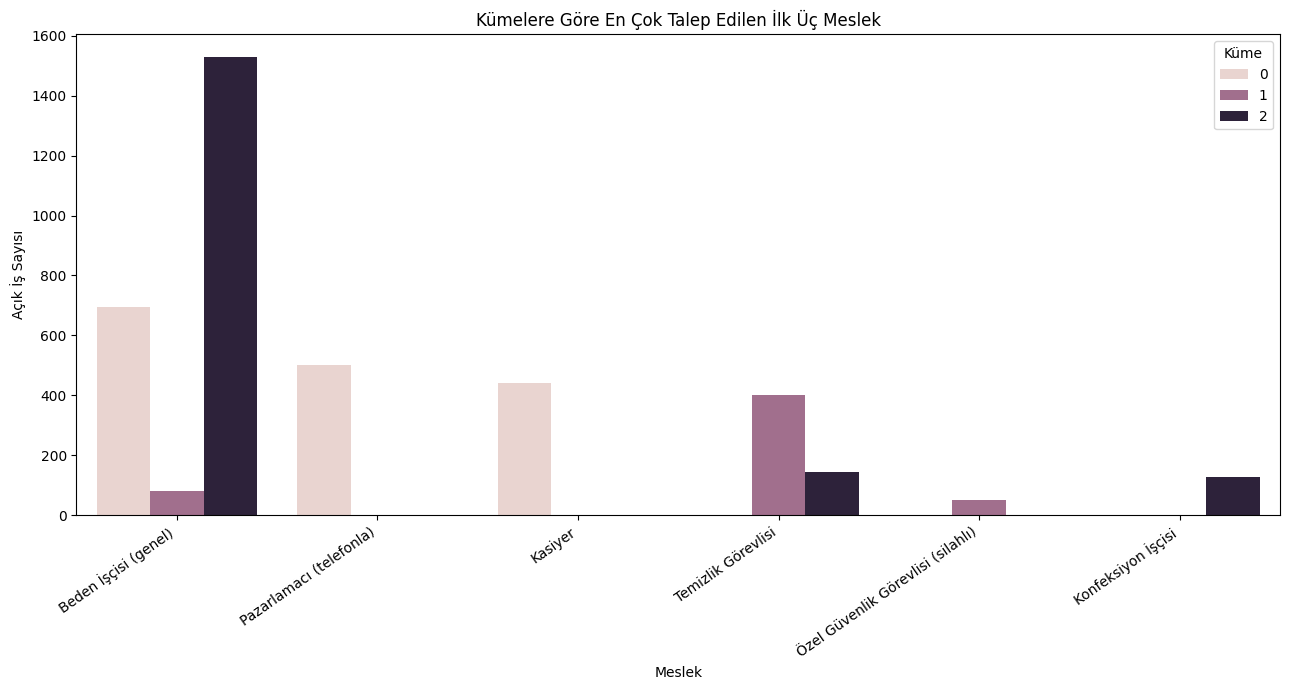

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(13, 7))

sns.barplot(
    data=kume_top_meslekler,
    x="Meslek",
    y="Açık İş",
    hue="Küme"
)

plt.title("Kümelere Göre En Çok Talep Edilen İlk Üç Meslek")
plt.xlabel("Meslek")
plt.ylabel("Açık İş Sayısı")
plt.xticks(rotation=35, ha="right")
plt.legend(title="Küme")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "kume_bazinda_ilk_uc_meslek.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 14.2. Kümeleme Sonuçlarının İlçe Bazında Karşılaştırılması

Bu bölümde K-Means ve Agglomerative Clustering algoritmalarının İstanbul ilçeleri için oluşturduğu küme atamaları karşılaştırılmıştır. Her ilçenin iki algoritmadaki küme üyeliği incelenerek algoritmalar arasındaki benzerlik ve farklılıklar değerlendirilmiştir.


In [ ]:

ilce_kume_karsilastirma = pd.DataFrame({
    "İlçe": X_kontrol.index,
    "K-Means Kümesi": kmeans_son_etiketler,
    "Agglomerative Kümesi": hiyerarsik_etiketler
})

ilce_kume_karsilastirma["Aynı Kümede mi?"] = (
    ilce_kume_karsilastirma["K-Means Kümesi"]
    == ilce_kume_karsilastirma["Agglomerative Kümesi"]
)

print("İlçelerin iki algoritmadaki küme üyelikleri:")
display(
    ilce_kume_karsilastirma.sort_values(
        ["K-Means Kümesi", "İlçe"]
    ).reset_index(drop=True)
)

print("\nAlgoritmaların aynı küme etiketi verdiği ilçe sayısı:")
print(
    ilce_kume_karsilastirma["Aynı Kümede mi?"].sum()
)

print("\nKüme üyelikleri farklı olan ilçeler:")
display(
    ilce_kume_karsilastirma[
        ~ilce_kume_karsilastirma["Aynı Kümede mi?"]
    ].reset_index(drop=True)
)

print("\nK-Means ve Agglomerative küme çapraz tablosu:")
display(
    pd.crosstab(
        ilce_kume_karsilastirma["K-Means Kümesi"],
        ilce_kume_karsilastirma["Agglomerative Kümesi"],
        margins=True
    )
)

ilce_kume_karsilastirma.to_csv(
    TABLE_DIR / "ilce_kumeleme_algoritmalari_karsilastirmasi.csv",
    index=False,
    encoding="utf-8-sig"
)


İlçelerin iki algoritmadaki küme üyelikleri:


,İlçe,K-Means Kümesi,Agglomerative Kümesi,Aynı Kümede mi?
0,Ataşehir,0,0,True
1,Avcılar,0,0,True
2,Bahçelievler,0,0,True
3,Bayrampaşa,0,0,True
4,Bağcılar,0,0,True
5,Başakşehir,0,0,True
6,Beşiktaş,0,0,True
7,Güngören,0,0,True
8,Kartal,0,0,True
9,Kağıthane,0,0,True



Algoritmaların aynı küme etiketi verdiği ilçe sayısı:
19

Küme üyelikleri farklı olan ilçeler:


,İlçe,K-Means Kümesi,Agglomerative Kümesi,Aynı Kümede mi?
0,Adalar,2,1,False
1,Arnavutköy,2,1,False
2,Bakırköy,1,2,False
3,Beykoz,1,2,False
4,Beylikdüzü,2,1,False
5,Beyoğlu,1,2,False
6,Büyükçekmece,2,1,False
7,Esenler,1,2,False
8,Esenyurt,2,1,False
9,Eyüp,1,2,False



K-Means ve Agglomerative küme çapraz tablosu:


Agglomerative Kümesi,0,1,2,All
K-Means Kümesi,,,,
0,19,0,0,19
1,1,0,9,10
2,1,9,0,10
All,21,9,9,39



## 14.3. PCA ile Kümeleme Sonuçlarının Görselleştirilmesi

Bu bölümde, K-Means ve Agglomerative Clustering algoritmalarıyla elde edilen kümeleme sonuçları Temel Bileşen Analizi (PCA) kullanılarak iki boyutlu düzlemde görselleştirilmiştir.

PCA yöntemi, meslek gruplarına ait değişkenlerden oluşan çok boyutlu veri yapısını daha az sayıda bileşenle ifade ederek ilçelerin görsel olarak karşılaştırılmasını sağlamaktadır.

Her iki algoritmanın küme etiketleri aynı PCA dönüşümü üzerinde gösterilerek ilçelerin gruplandırılma biçimleri incelenmiştir. İlk iki temel bileşenin açıkladığı toplam varyans dikkate alınarak görselleştirmenin veri yapısını temsil etme düzeyi de değerlendirilmiştir.


PCA ile açıklanan varyans oranları:
Birinci bileşen (PC1): %17.42
İkinci bileşen (PC2): %12.18
İlk iki bileşenin toplamı: %29.60


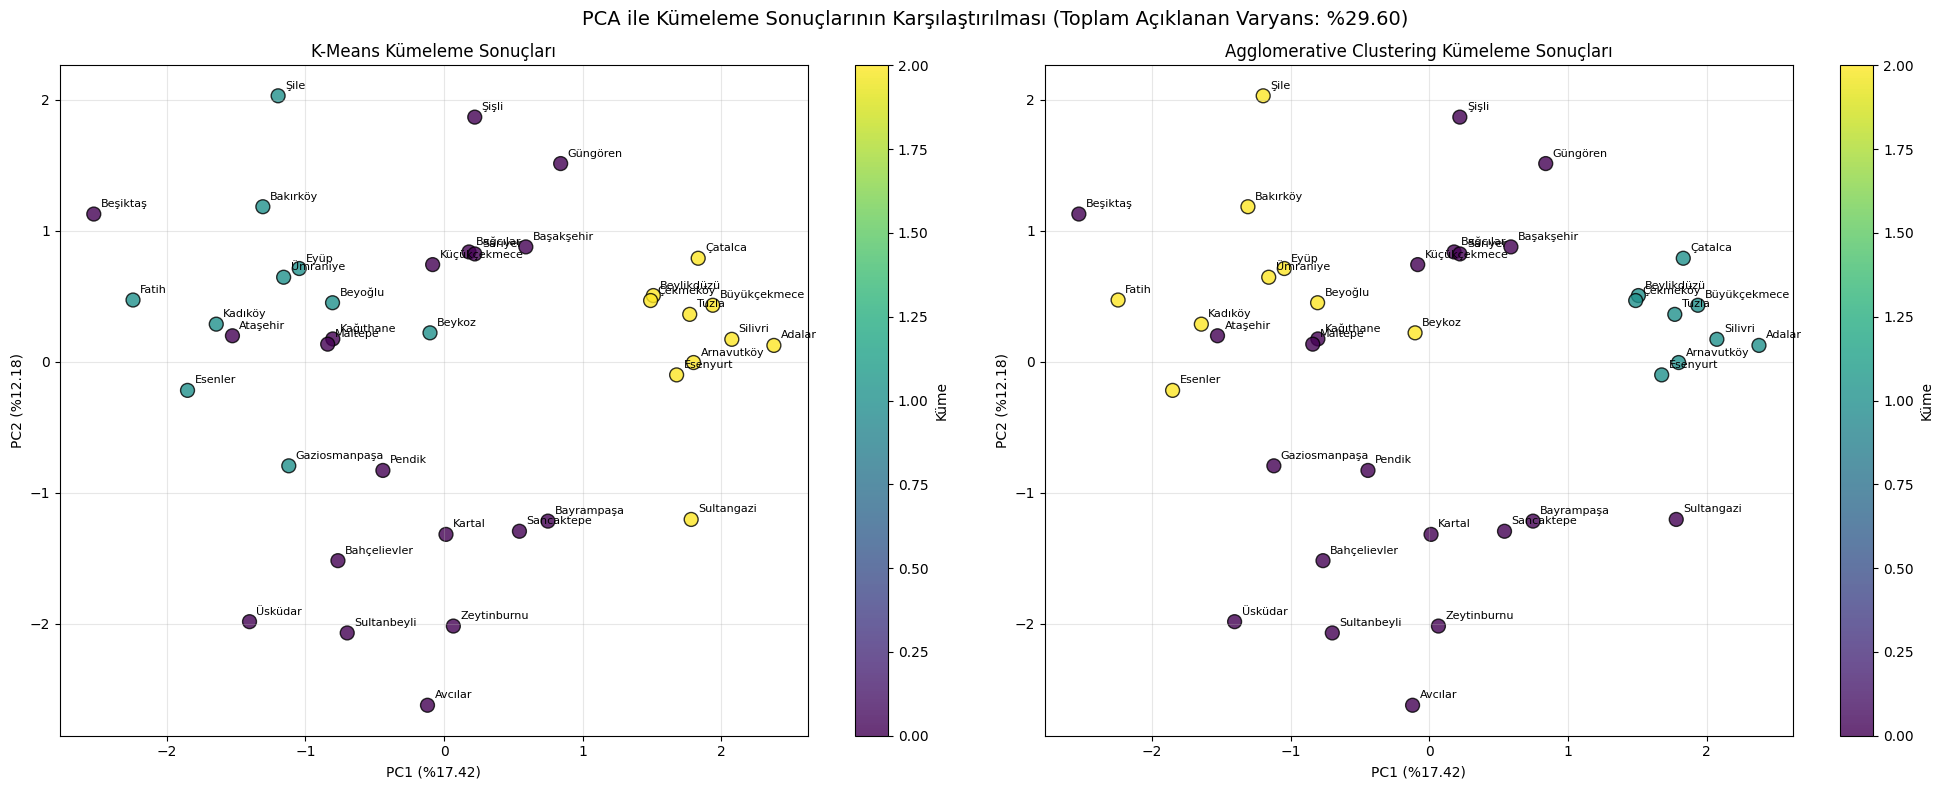


PCA veri tablosu:


,PC1,PC2,İlçe,K-Means Kümesi,Agglomerative Kümesi
0,2.3783,0.1260,Adalar,2,1
1,1.7989,-0.0048,Arnavutköy,2,1
2,-1.5264,0.1996,Ataşehir,0,0
3,-0.1197,-2.6216,Avcılar,0,0
4,-0.7656,-1.5176,Bahçelievler,0,0
5,-1.3070,1.1850,Bakırköy,1,2
6,0.7489,-1.2157,Bayrampaşa,0,0
7,0.1797,0.8397,Bağcılar,0,0
8,0.5894,0.8783,Başakşehir,0,0
9,-0.1016,0.2220,Beykoz,1,2


In [ ]:

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

pca_model = PCA(n_components=2)

pca_sonuclari = pca_model.fit_transform(X_olcekli)

pca_df = pd.DataFrame({
    "PC1": pca_sonuclari[:, 0],
    "PC2": pca_sonuclari[:, 1],
    "İlçe": X_kontrol.index,
    "K-Means Kümesi": kmeans_son_etiketler,
    "Agglomerative Kümesi": hiyerarsik_etiketler
})

aciklanan_varyans = pca_model.explained_variance_ratio_ * 100
toplam_varyans = aciklanan_varyans.sum()

print("PCA ile açıklanan varyans oranları:")
print(f"Birinci bileşen (PC1): %{aciklanan_varyans[0]:.2f}")
print(f"İkinci bileşen (PC2): %{aciklanan_varyans[1]:.2f}")
print(f"İlk iki bileşenin toplamı: %{toplam_varyans:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(20, 8))

algoritmalar = [
    ("K-Means", "K-Means Kümesi"),
    ("Agglomerative Clustering", "Agglomerative Kümesi")
]

for ax, (baslik, kume_sutunu) in zip(axes, algoritmalar):
    noktalar = ax.scatter(
        pca_df["PC1"],
        pca_df["PC2"],
        c=pca_df[kume_sutunu],
        cmap="viridis",
        s=100,
        alpha=0.8,
        edgecolors="black"
    )

    for _, satir in pca_df.iterrows():
        ax.annotate(
            satir["İlçe"],
            (satir["PC1"], satir["PC2"]),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=8
        )

    ax.set_title(f"{baslik} Kümeleme Sonuçları")
    ax.set_xlabel(
        f"PC1 (%{aciklanan_varyans[0]:.2f})"
    )
    ax.set_ylabel(
        f"PC2 (%{aciklanan_varyans[1]:.2f})"
    )
    ax.grid(alpha=0.3)

    renk_cubugu = fig.colorbar(noktalar, ax=ax)
    renk_cubugu.set_label("Küme")

plt.suptitle(
    f"PCA ile Kümeleme Sonuçlarının Karşılaştırılması "
    f"(Toplam Açıklanan Varyans: %{toplam_varyans:.2f})",
    fontsize=14
)

plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "pca_kumeleme_algoritmalari_karsilastirmasi.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("\nPCA veri tablosu:")
display(pca_df.round(4))

pca_df.to_csv(
    TABLE_DIR / "pca_kumeleme_sonuclari.csv",
    index=False,
    encoding="utf-8-sig"
)


PCA bileşenlerinin açıklanan varyans tablosu:


,Temel Bileşen,Açıklanan Varyans (%),Kümülatif Varyans (%)
0,PC1,17.42,17.42
1,PC2,12.18,29.60
2,PC3,11.89,41.49
3,PC4,11.06,52.55
4,PC5,10.97,63.52
5,PC6,9.80,73.32
6,PC7,9.57,82.89
7,PC8,9.42,92.31
8,PC9,7.69,100.00
9,PC10,0.00,100.00


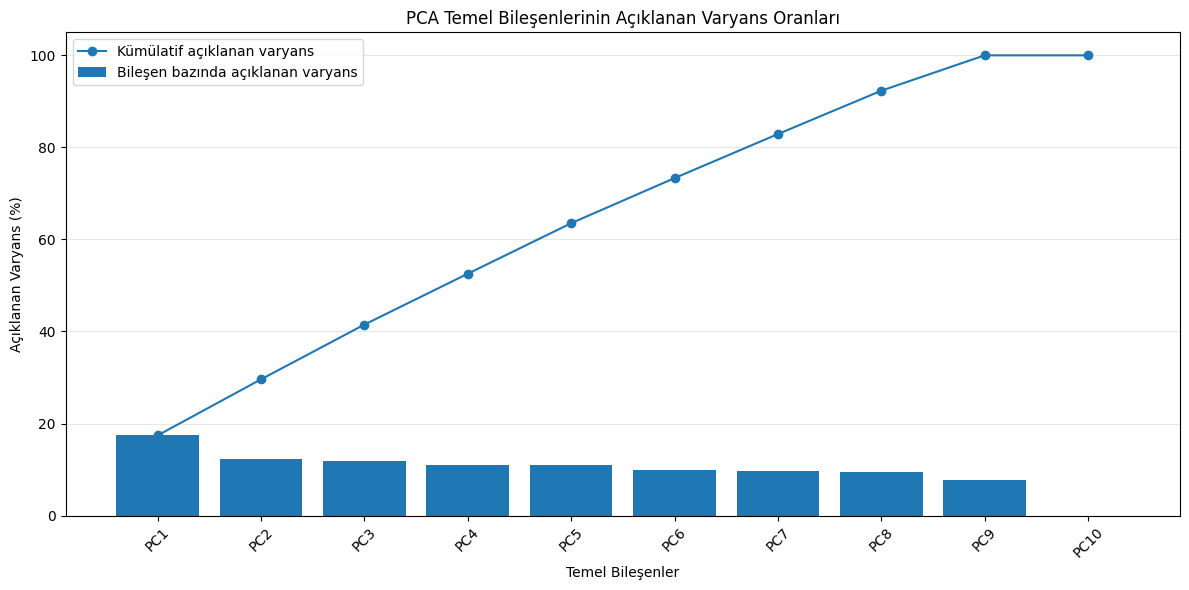

In [ ]:

pca_tum_model = PCA()
pca_tum_sonuclar = pca_tum_model.fit_transform(X_olcekli)

pca_varyans_tablosu = pd.DataFrame({
    "Temel Bileşen": [
        f"PC{i+1}" for i in range(len(pca_tum_model.explained_variance_ratio_))
    ],
    "Açıklanan Varyans (%)":
        pca_tum_model.explained_variance_ratio_ * 100,
    "Kümülatif Varyans (%)":
        np.cumsum(pca_tum_model.explained_variance_ratio_) * 100
})

print("PCA bileşenlerinin açıklanan varyans tablosu:")
display(pca_varyans_tablosu.round(2))

plt.figure(figsize=(12, 6))

plt.bar(
    pca_varyans_tablosu["Temel Bileşen"],
    pca_varyans_tablosu["Açıklanan Varyans (%)"],
    label="Bileşen bazında açıklanan varyans"
)

plt.plot(
    pca_varyans_tablosu["Temel Bileşen"],
    pca_varyans_tablosu["Kümülatif Varyans (%)"],
    marker="o",
    label="Kümülatif açıklanan varyans"
)

plt.xlabel("Temel Bileşenler")
plt.ylabel("Açıklanan Varyans (%)")
plt.title("PCA Temel Bileşenlerinin Açıklanan Varyans Oranları")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "pca_aciklanan_varyans_analizi.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

pca_varyans_tablosu.to_csv(
    TABLE_DIR / "pca_aciklanan_varyans.csv",
    index=False,
    encoding="utf-8-sig"
)



## 14.4. K-Means Modelinin Farklı Başlangıçlarda Kararlılık Analizi

K-Means algoritması başlangıç merkezlerinin seçimine bağlı olarak farklı kümeleme sonuçları üretebilmektedir. Bu nedenle modelin farklı rastgele başlangıç değerlerinde benzer sonuçlar üretip üretmediğini değerlendirmek amacıyla kararlılık analizi gerçekleştirilmiştir.

Bu analizde nihai modelde kullanılan 20 başlangıç denemesi (n_init=20) korunmuş ve farklı random_state değerleriyle modeller yeniden eğitilmiştir.

Modellerin küme üyelikleri arasındaki benzerlik Adjusted Rand Index (ARI) metriği kullanılarak ölçülmüştür. ARI değeri 1'e yaklaştıkça iki kümeleme sonucunun benzerliği artmaktadır. Sıfıra yakın değerler ise rastlantısal benzerliğe işaret etmektedir.


In [ ]:

from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from itertools import combinations

kararlilik_random_state = [0, 10, 21, 42, 50, 75, 100, 123, 2026]

kararlilik_modelleri = {}
kararlilik_sonuclari = []

for random_state in kararlilik_random_state:
    model = KMeans(
        n_clusters=SECILEN_K,
        random_state=random_state,
        n_init=20
    )

    etiketler = model.fit_predict(X_kontrol)
    kararlilik_modelleri[random_state] = etiketler

for seed1, seed2 in combinations(kararlilik_random_state, 2):
    ari = adjusted_rand_score(
        kararlilik_modelleri[seed1],
        kararlilik_modelleri[seed2]
    )

    kararlilik_sonuclari.append({
        "Başlangıç 1": seed1,
        "Başlangıç 2": seed2,
        "ARI": ari
    })

kararlilik_df = pd.DataFrame(kararlilik_sonuclari)

print("Farklı başlangıçlar arasındaki ARI sonuçları:")
display(kararlilik_df.round(4))

print("\nKararlılık analizi özeti:")
print("Karşılaştırma sayısı:", len(kararlilik_df))
print("Ortalama ARI:", round(kararlilik_df["ARI"].mean(), 4))
print("Medyan ARI:", round(kararlilik_df["ARI"].median(), 4))
print("Standart sapma:", round(kararlilik_df["ARI"].std(), 4))
print("Minimum ARI:", round(kararlilik_df["ARI"].min(), 4))
print("Maksimum ARI:", round(kararlilik_df["ARI"].max(), 4))

kararlilik_df.to_csv(
    TABLE_DIR / "kmeans_n_init20_kararlilik.csv",
    index=False,
    encoding="utf-8-sig"
)


Farklı başlangıçlar arasındaki ARI sonuçları:


,Başlangıç 1,Başlangıç 2,ARI
0,0,10,1.0
1,0,21,1.0
2,0,42,1.0
3,0,50,1.0
4,0,75,1.0
5,0,100,1.0
6,0,123,1.0
7,0,2026,1.0
8,10,21,1.0
9,10,42,1.0



Kararlılık analizi özeti:
Karşılaştırma sayısı: 36
Ortalama ARI: 1.0
Medyan ARI: 1.0
Standart sapma: 0.0
Minimum ARI: 1.0
Maksimum ARI: 1.0



## 14.5. Düşük Açık İş Sayısına Sahip İlçelerin Kümeleme Sonuçlarına Etkisinin İncelenmesi

İlçelerdeki açık iş ilanı sayılarının farklı olması, meslek dağılımı oranlarının güvenilirliğini etkileyebilmektedir. Özellikle düşük sayıda açık iş ilanına sahip ilçelerde birkaç ilanın dağılımı önemli ölçüde değiştirmesi mümkündür.

Bu nedenle düşük açık iş sayısına sahip ilçelerin kümeleme sonuçları üzerindeki etkisini incelemek amacıyla duyarlılık analizi gerçekleştirilmiştir.

Analizde farklı minimum açık iş sayısı eşikleri kullanılarak ilçeler filtrelenmiş, her alt veri kümesinde K-Means modeli yeniden eğitilmiş ve sonuçlar başlangıçtaki kümeleme üyelikleriyle Adjusted Rand Index (ARI) metriği üzerinden karşılaştırılmıştır.

Bu çalışma, düşük hacimli ilçelerin çıkarılmasının küme yapısını ne ölçüde değiştirdiğini değerlendirmeyi amaçlamaktadır.


In [ ]:

from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

ilce_acik_is = model_verisi.loc[
    X_kontrol.index, "Toplam Açık İş"
].copy()

ilce_acik_is = pd.to_numeric(ilce_acik_is, errors="coerce")

print("İlçelerin toplam açık iş sayıları:")
display(
    ilce_acik_is.sort_values().to_frame("Toplam Açık İş")
)

print("\nAçık iş sayılarının özeti:")
display(ilce_acik_is.describe().to_frame().round(2))

minimum_is_esikleri = [5, 10, 20, 50]

duyarlilik_sonuclari = []

for esik in minimum_is_esikleri:
    uygun_ilceler = ilce_acik_is[ilce_acik_is >= esik].index

    X_filtreli = X_kontrol.loc[uygun_ilceler].copy()

    if len(X_filtreli) <= SECILEN_K:
        continue

    model = KMeans(
        n_clusters=SECILEN_K,
        random_state=42,
        n_init=20
    )

    yeni_etiketler = model.fit_predict(X_filtreli)

    temel_etiketler = pd.Series(
        kmeans_son_etiketler,
        index=X_kontrol.index
    ).loc[uygun_ilceler]

    ari = adjusted_rand_score(
        temel_etiketler,
        yeni_etiketler
    )

    siluet = silhouette_score(
        X_filtreli,
        yeni_etiketler
    )

    duyarlilik_sonuclari.append({
        "Minimum Açık İş Eşiği": esik,
        "Kalan İlçe Sayısı": len(X_filtreli),
        "Çıkarılan İlçe Sayısı": len(X_kontrol) - len(X_filtreli),
        "ARI": ari,
        "Silhouette Score": siluet
    })

duyarlilik_df = pd.DataFrame(duyarlilik_sonuclari)

print("\nDüşük açık iş sayısı duyarlılık analizi:")
display(duyarlilik_df.round(4))

duyarlilik_df.to_csv(
    TABLE_DIR / "dusuk_acik_is_duyarlilik_analizi.csv",
    index=False,
    encoding="utf-8-sig"
)


İlçelerin toplam açık iş sayıları:


,Toplam Açık İş
İlçe,
Adalar,1
Şile,6
Bayrampaşa,18
Beykoz,22
Zeytinburnu,23
Bakırköy,24
Güngören,26
Fatih,26
Çatalca,28



Açık iş sayılarının özeti:


,Toplam Açık İş
count,39.00
mean,147.54
std,163.48
min,1.00
25%,29.00
50%,91.00
75%,183.50
max,615.00



Düşük açık iş sayısı duyarlılık analizi:


,Minimum Açık İş Eşiği,Kalan İlçe Sayısı,Çıkarılan İlçe Sayısı,ARI,Silhouette Score
0,5,38,1,1.000,0.3060
1,10,37,2,1.000,0.3050
2,20,36,3,1.000,0.3145
3,50,24,15,0.257,0.2617



## 14.6. K-Means ve Agglomerative Clustering Küme Profillerinin Karşılaştırılması

Bu bölümde K-Means ve Agglomerative Clustering algoritmalarının oluşturduğu kümeler, yalnızca ilçe üyelikleri açısından değil, meslek gruplarına göre açık iş dağılımları açısından da karşılaştırılmıştır.

Karşılaştırmada İŞKUR açık iş verilerindeki gerçek ilan sayıları kullanılmıştır. Her algoritmanın kümelerinde yer alan ilçelerin meslek gruplarına göre açık iş sayıları toplanmış ve bu değerler üzerinden meslek dağılım oranları hesaplanmıştır.

Algoritmaların küme numaraları birbirinden bağımsız olduğundan, karşılaştırma öncesinde kümeler ilçe üyelikleri arasındaki en yüksek eşleşmeyi sağlayacak şekilde hizalanmıştır.

Bu analiz ile iki algoritmanın benzer ilçe grupları oluşturmasının yanı sıra benzer iş gücü piyasası profilleri ortaya çıkarıp çıkarmadığı değerlendirilmiştir.


In [ ]:
agg_ilce_sayilari_hizali = (
    agg_hizalanmis
    .value_counts()
    .reindex([0, 1, 2], fill_value=0)
)

agg_toplam_is_hizali = (
    kume_ham_veri
    .groupby("Agglomerative Kümesi")["Açık İş"]
    .sum()
)

agg_toplam_is_hizali.index = (
    agg_toplam_is_hizali.index.map(
        {agg: kmeans for kmeans, agg in en_iyi_eslesme.items()}
    )
)

agg_toplam_is_hizali = (
    agg_toplam_is_hizali
    .reindex([0, 1, 2], fill_value=0)
)

agg_kume_ozeti_hizali = pd.DataFrame({
    "İlçe Sayısı": agg_ilce_sayilari_hizali,
    "Toplam Açık İş": agg_toplam_is_hizali
})

agg_kume_ozeti_hizali.index.name = (
    "K-Means ile Hizalanmış Agglomerative Kümesi"
)

print("HİZALANMIŞ AGGLOMERATIVE KÜME ÖZETİ")
display(agg_kume_ozeti_hizali)

HİZALANMIŞ AGGLOMERATIVE KÜME ÖZETİ


,İlçe Sayısı,Toplam Açık İş
K-Means ile Hizalanmış Agglomerative Kümesi,,
0,21,3359
1,9,1752
2,9,643


###Küme etiketlerinin eşleştirilmesi ve verilerin hazırlanması

In [ ]:

from itertools import permutations

kmeans_etiket_serisi = pd.Series(
    kmeans_son_etiketler,
    index=X_kontrol.index,
    name="K-Means Kümesi"
)

agg_etiket_serisi = pd.Series(
    hiyerarsik_etiketler,
    index=X_kontrol.index,
    name="Agglomerative Kümesi"
)

kume_sayilari = sorted(kmeans_etiket_serisi.unique())
agg_kume_sayilari = sorted(agg_etiket_serisi.unique())

en_iyi_eslesme = None
en_yuksek_eslesme = -1

for permutasyon in permutations(agg_kume_sayilari):

    eslesme = dict(zip(kume_sayilari, permutasyon))

    eslesen_sayisi = sum(
        int(
            (
                (kmeans_etiket_serisi == kume) &
                (agg_etiket_serisi == eslesme[kume])
            ).sum()
        )
        for kume in kume_sayilari
    )

    if eslesen_sayisi > en_yuksek_eslesme:
        en_yuksek_eslesme = eslesen_sayisi
        en_iyi_eslesme = eslesme

agg_hizalanmis = agg_etiket_serisi.map(
    {agg: kmeans for kmeans, agg in en_iyi_eslesme.items()}
)

print("En iyi küme eşleşmesi:")
print(en_iyi_eslesme)

print("\nEşleşen ilçe sayısı:", en_yuksek_eslesme)
print("Toplam ilçe sayısı:", len(X_kontrol))

print(
    "Eşleşme oranı (%):",
    round(en_yuksek_eslesme / len(X_kontrol) * 100, 2)
)

kume_ham_veri = iskur_istanbul.copy()

kume_ham_veri["İlçe"] = (
    kume_ham_veri["İlçe"].astype(str).str.strip()
)

kume_ham_veri["Meslek"] = (
    kume_ham_veri["Meslek"].astype(str).str.strip()
)

kume_ham_veri["Açık İş"] = pd.to_numeric(
    kume_ham_veri["Açık İş"],
    errors="coerce"
).fillna(0)

kume_ham_veri = kume_ham_veri[
    kume_ham_veri["Meslek"].isin(X_kontrol.columns)
].copy()

kume_ham_veri["K-Means Kümesi"] = (
    kume_ham_veri["İlçe"].map(kmeans_etiket_serisi)
)

kume_ham_veri["Agglomerative Kümesi"] = (
    kume_ham_veri["İlçe"].map(agg_hizalanmis)
)

kume_ham_veri = kume_ham_veri.dropna(
    subset=["K-Means Kümesi", "Agglomerative Kümesi"]
)

kume_ham_veri["K-Means Kümesi"] = (
    kume_ham_veri["K-Means Kümesi"].astype(int)
)

kume_ham_veri["Agglomerative Kümesi"] = (
    kume_ham_veri["Agglomerative Kümesi"].astype(int)
)

print("\nKarşılaştırma için kullanılan ham veri boyutu:")
print(kume_ham_veri.shape)

print("\nKullanılan meslek sayısı:")
print(kume_ham_veri["Meslek"].nunique())


En iyi küme eşleşmesi:
{np.int32(0): np.int64(0), np.int32(1): np.int64(2), np.int32(2): np.int64(1)}

Eşleşen ilçe sayısı: 37
Toplam ilçe sayısı: 39
Eşleşme oranı (%): 94.87

Karşılaştırma için kullanılan ham veri boyutu:
(226, 8)

Kullanılan meslek sayısı:
10


###Her algoritmanın meslek profillerini hesaplama

In [ ]:
kmeans_meslek_sayilari = (
    kume_ham_veri
    .groupby(["K-Means Kümesi", "Meslek"])["Açık İş"]
    .sum()
    .unstack(fill_value=0)
    .reindex(columns=X_kontrol.columns, fill_value=0)
)

agg_meslek_sayilari = (
    kume_ham_veri
    .groupby(["Agglomerative Kümesi", "Meslek"])["Açık İş"]
    .sum()
    .unstack(fill_value=0)
    .reindex(columns=X_kontrol.columns, fill_value=0)
)

kmeans_toplam_is = kmeans_meslek_sayilari.sum(axis=1)
agg_toplam_is = agg_meslek_sayilari.sum(axis=1)

kmeans_meslek_oranlari = (
    kmeans_meslek_sayilari
    .div(kmeans_toplam_is.replace(0, np.nan), axis=0)
    .fillna(0) * 100
)

agg_meslek_oranlari = (
    agg_meslek_sayilari
    .div(agg_toplam_is.replace(0, np.nan), axis=0)
    .fillna(0) * 100
)

kmeans_ilce_sayilari = kmeans_etiket_serisi.value_counts().sort_index()
agg_ilce_sayilari = agg_hizalanmis.value_counts().sort_index()

print("K-MEANS KÜME PROFİLLERİ")
display(kmeans_meslek_oranlari.round(2))

print("\nAGGLOMERATIVE KÜME PROFİLLERİ")
display(agg_meslek_oranlari.round(2))

print("\nK-MEANS KÜME ÖZETİ")
kmeans_kume_ozeti = pd.DataFrame({
    "İlçe Sayısı": kmeans_ilce_sayilari,
    "Toplam Açık İş": kmeans_toplam_is
})
display(kmeans_kume_ozeti)

print("\nAGGLOMERATIVE KÜME ÖZETİ")
agg_kume_ozeti = pd.DataFrame({
    "İlçe Sayısı": agg_ilce_sayilari,
    "Toplam Açık İş": agg_toplam_is
})
display(agg_kume_ozeti)


K-MEANS KÜME PROFİLLERİ


Meslek,Beden İşçisi (genel),Temizlik Görevlisi,Kasiyer,Pazarlamacı (telefonla),Büro Memuru (genel),Satış Elemanı / Danışmanı,Servis Elemanı (garson),Market Elemanı,Ambar/Depo Görevlisi,Konfeksiyon İşçisi
K-Means Kümesi,,,,,,,,,,
0,22.45,9.62,14.32,16.2,8.10,7.55,8.07,8.16,3.24,2.30
1,11.74,59.44,6.24,0.0,6.69,4.90,3.57,4.61,1.93,0.89
2,76.63,7.22,1.60,0.0,1.15,0.80,0.85,0.30,5.07,6.37



AGGLOMERATIVE KÜME PROFİLLERİ


Meslek,Beden İşçisi (genel),Temizlik Görevlisi,Kasiyer,Pazarlamacı (telefonla),Büro Memuru (genel),Satış Elemanı / Danışmanı,Servis Elemanı (garson),Market Elemanı,Ambar/Depo Görevlisi,Konfeksiyon İşçisi
Agglomerative Kümesi,,,,,,,,,,
0,24.80,9.41,13.31,14.89,7.47,7.29,7.44,7.50,3.13,4.76
1,12.29,60.34,6.53,0.00,6.84,3.58,3.73,4.82,1.40,0.47
2,79.22,7.82,1.54,0.00,1.31,0.80,0.91,0.34,5.71,2.34



K-MEANS KÜME ÖZETİ


,İlçe Sayısı,Toplam Açık İş
K-Means Kümesi,,
0,19,3087
1,10,673
2,10,1994



AGGLOMERATIVE KÜME ÖZETİ


,İlçe Sayısı,Toplam Açık İş
Agglomerative Kümesi,,
0,21,3359
1,9,643
2,9,1752


###Meslek profillerinin görsel karşılaştırılması

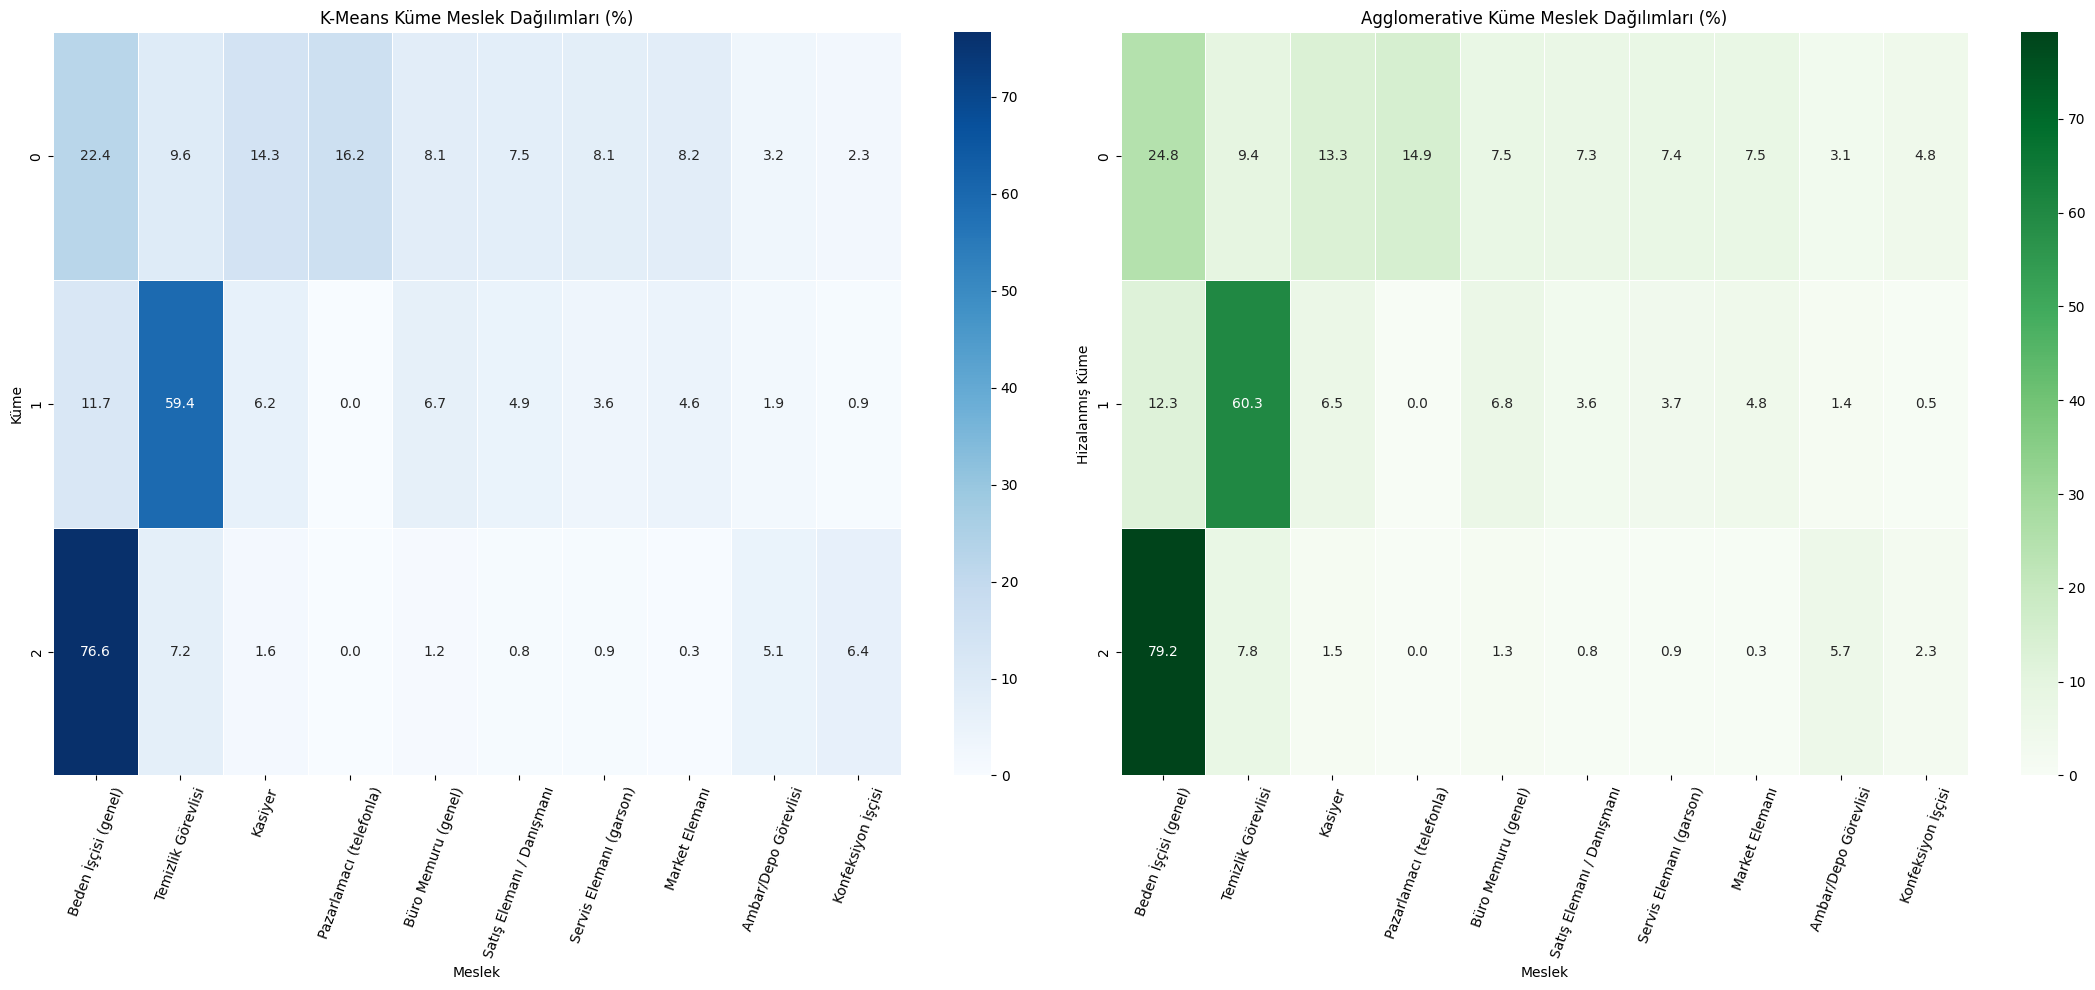

Algoritmalar arasındaki mutlak meslek profili farkları (% puan):


Meslek,Beden İşçisi (genel),Temizlik Görevlisi,Kasiyer,Pazarlamacı (telefonla),Büro Memuru (genel),Satış Elemanı / Danışmanı,Servis Elemanı (garson),Market Elemanı,Ambar/Depo Görevlisi,Konfeksiyon İşçisi
K-Means Kümesi,,,,,,,,,,
0,2.35,0.21,1.01,1.31,0.63,0.25,0.62,0.66,0.11,2.46
1,0.55,0.91,0.29,0.00,0.16,1.33,0.17,0.21,0.53,0.42
2,2.59,0.60,0.06,0.00,0.16,0.00,0.06,0.04,0.64,4.03



Ortalama mutlak profil farkı:
0.7462


In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(22, 10))

sns.heatmap(
    kmeans_meslek_oranlari,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    linewidths=0.5,
    ax=axes[0]
)

axes[0].set_title("K-Means Küme Meslek Dağılımları (%)")
axes[0].set_xlabel("Meslek")
axes[0].set_ylabel("Küme")
axes[0].tick_params(axis="x", rotation=70)

sns.heatmap(
    agg_meslek_oranlari,
    annot=True,
    fmt=".1f",
    cmap="Greens",
    linewidths=0.5,
    ax=axes[1]
)

axes[1].set_title("Agglomerative Küme Meslek Dağılımları (%)")
axes[1].set_xlabel("Meslek")
axes[1].set_ylabel("Hizalanmış Küme")
axes[1].tick_params(axis="x", rotation=70)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "kumeleme_meslek_profilleri_karsilastirmasi.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# İki algoritmanın meslek payları arasındaki mutlak fark
meslek_profil_farki = (
    kmeans_meslek_oranlari - agg_meslek_oranlari
).abs()

print("Algoritmalar arasındaki mutlak meslek profili farkları (% puan):")
display(meslek_profil_farki.round(2))

print("\nOrtalama mutlak profil farkı:")
print(round(meslek_profil_farki.to_numpy().mean(), 4))


###Her kümenin en yoğun üç mesleğini karşılaştırma

In [ ]:

def en_yogun_meslekleri_bul(meslek_sayilari, meslek_oranlari, algoritma):
    sonuclar = []

    for kume in meslek_sayilari.index:
        en_yuksek = meslek_sayilari.loc[kume].nlargest(3)

        for sira, (meslek, sayi) in enumerate(en_yuksek.items(), start=1):
            sonuclar.append({
                "Algoritma": algoritma,
                "Küme": int(kume),
                "Sıra": sira,
                "Meslek": meslek,
                "Açık İş Sayısı": int(sayi),
                "Küme İçindeki Pay (%)": round(
                    meslek_oranlari.loc[kume, meslek], 2
                )
            })

    return pd.DataFrame(sonuclar)


kmeans_en_yogun = en_yogun_meslekleri_bul(
    kmeans_meslek_sayilari,
    kmeans_meslek_oranlari,
    "K-Means"
)

agg_en_yogun = en_yogun_meslekleri_bul(
    agg_meslek_sayilari,
    agg_meslek_oranlari,
    "Agglomerative"
)

en_yogun_karsilastirma = pd.concat(
    [kmeans_en_yogun, agg_en_yogun],
    ignore_index=True
)

print("Algoritmaların küme bazındaki en yoğun üç mesleği:")
display(en_yogun_karsilastirma)

en_yogun_karsilastirma.to_csv(
    TABLE_DIR / "algoritmalar_en_yogun_meslek_karsilastirmasi.csv",
    index=False,
    encoding="utf-8-sig"
)


Algoritmaların küme bazındaki en yoğun üç mesleği:


,Algoritma,Küme,Sıra,Meslek,Açık İş Sayısı,Küme İçindeki Pay (%)
0,K-Means,0,1,Beden İşçisi (genel),693,22.45
1,K-Means,0,2,Pazarlamacı (telefonla),500,16.20
2,K-Means,0,3,Kasiyer,442,14.32
3,K-Means,1,1,Temizlik Görevlisi,400,59.44
4,K-Means,1,2,Beden İşçisi (genel),79,11.74
5,K-Means,1,3,Büro Memuru (genel),45,6.69
6,K-Means,2,1,Beden İşçisi (genel),1528,76.63
7,K-Means,2,2,Temizlik Görevlisi,144,7.22
8,K-Means,2,3,Konfeksiyon İşçisi,127,6.37
9,Agglomerative,0,1,Beden İşçisi (genel),833,24.80


In [ ]:
kmeans_meslek_sayilari.to_csv(
    TABLE_DIR / "kmeans_kume_meslek_sayilari.csv",
    encoding="utf-8-sig"
)

agg_meslek_sayilari.to_csv(
    TABLE_DIR / "agglomerative_kume_meslek_sayilari.csv",
    encoding="utf-8-sig"
)

kmeans_meslek_oranlari.to_csv(
    TABLE_DIR / "kmeans_kume_meslek_oranlari.csv",
    encoding="utf-8-sig"
)

agg_meslek_oranlari.to_csv(
    TABLE_DIR / "agglomerative_kume_meslek_oranlari.csv",
    encoding="utf-8-sig"
)

meslek_profil_farki.to_csv(
    TABLE_DIR / "algoritmalar_meslek_profil_farklari.csv",
    encoding="utf-8-sig"
)

print("Küme profili karşılaştırma tabloları ve grafikleri kaydedildi.")


Küme profili karşılaştırma tabloları ve grafikleri kaydedildi.


## 15. PCA ile kümelerin iki boyutta görselleştirilmesi
K-Means algoritması sonucunda oluşturulan ilçe kümeleri, Temel Bileşen Analizi (PCA) kullanılarak iki boyutlu düzlemde görselleştirilmiştir. İlk iki temel bileşenin açıkladığı varyans oranları hesaplanmış ve ilçelerin küme dağılımları renklerle gösterilmiştir. Elde edilen sonuçlar grafik ve CSV dosyası olarak kaydedilmiştir.

Açıklanan varyans oranları: [0.47369081 0.16811058]
İlk iki bileşenin toplam açıklanan varyansı: 0.6418


,PCA1,PCA2,Küme,Toplam Açık İş
İlçe,,,,
Adalar,0.658214,0.128372,2,1
Arnavutköy,0.418259,0.060698,2,590
Ataşehir,-0.262007,-0.238291,0,181
Avcılar,-0.210753,-0.495416,0,554
Bahçelievler,-0.146566,-0.114005,0,67


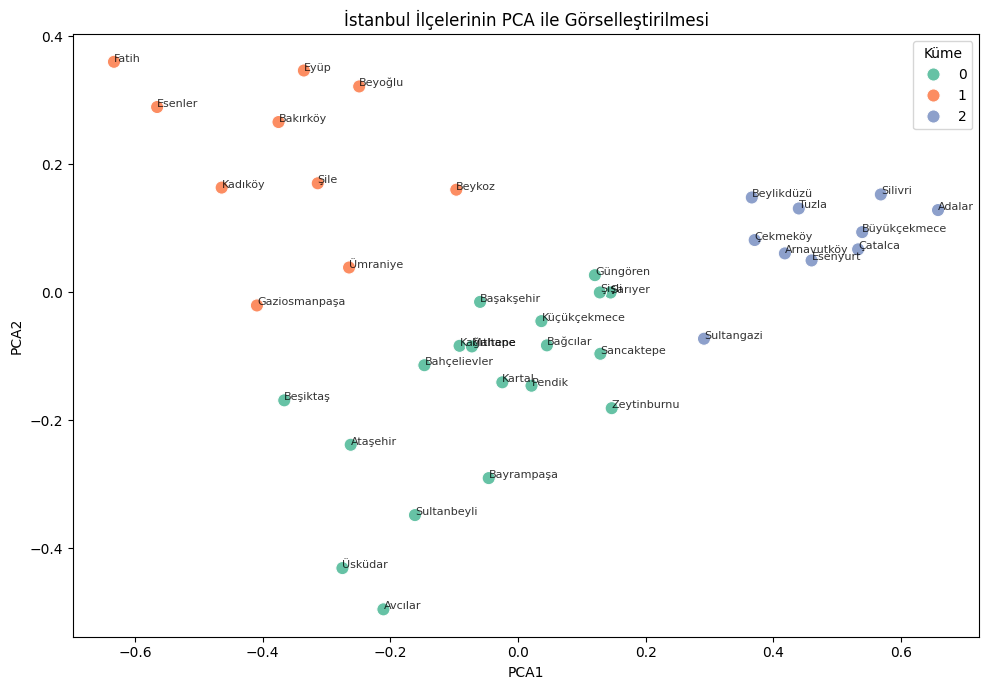

In [ ]:
from sklearn.decomposition import PCA

if iskur is not None and "Küme" in model_verisi.columns and X.shape[1] >= 2:
    pca = PCA(n_components=2)
    pca_sonuclari = pca.fit_transform(X)
    pca_df = pd.DataFrame(pca_sonuclari, columns=["PCA1", "PCA2"], index=X.index)
    pca_df["Küme"] = model_verisi["Küme"]
    pca_df["Toplam Açık İş"] = model_verisi["Toplam Açık İş"]

    print("Açıklanan varyans oranları:", pca.explained_variance_ratio_)
    print("İlk iki bileşenin toplam açıklanan varyansı:", round(pca.explained_variance_ratio_.sum(), 4))
    display(pca_df.head())

    plt.figure(figsize=(10, 7))
    sns.scatterplot(data=pca_df, x="PCA1", y="PCA2", hue="Küme", palette="Set2", s=90)
    for ilce, satir in pca_df.iterrows():
        plt.text(satir["PCA1"], satir["PCA2"], str(ilce), fontsize=8, alpha=.8)
    plt.title("İstanbul İlçelerinin PCA ile Görselleştirilmesi")
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / "pca_ilce_kumeleri.png", dpi=200)
    plt.show()

    pca_df.reset_index(names="İlçe").to_csv(TABLE_DIR / "istanbul_pca_sonuclari.csv", index=False, encoding="utf-8-sig")

### 15.1. PCA Açıklanan Varyans Analizi

Temel Bileşen Analizi (PCA) ile yüksek boyutlu veri iki boyuta indirgenmiştir. Bu bölümde her temel bileşenin ve ilk iki bileşenin toplam açıklanan varyans oranı hesaplanarak iki boyutlu görselleştirmenin veri yapısını ne ölçüde temsil ettiği değerlendirilmiştir. Ayrıca kümülatif açıklanan varyans grafiği oluşturulmuştur.

,Temel Bileşen,Açıklanan Varyans (%),Kümülatif Varyans (%)
0,PC1,17.42,17.42
1,PC2,12.18,29.60
2,PC3,11.89,41.49
3,PC4,11.06,52.55
4,PC5,10.97,63.52
5,PC6,9.80,73.32
6,PC7,9.57,82.89
7,PC8,9.42,92.31
8,PC9,7.69,100.00
9,PC10,0.00,100.00


İlk iki temel bileşenin açıkladığı toplam varyans: %29.60


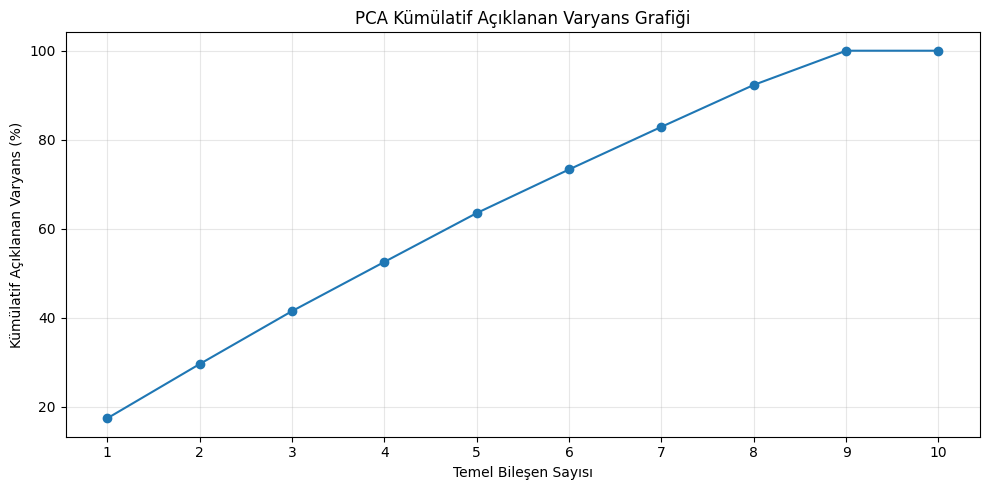

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np

pca_tum = PCA()
pca_tum.fit(X_olcekli)

bilesen_sayilari = np.arange(1, len(pca_tum.explained_variance_ratio_) + 1)

varyans_tablosu = pd.DataFrame({
    "Temel Bileşen": [
        f"PC{i}" for i in bilesen_sayilari
    ],
    "Açıklanan Varyans (%)": (
        pca_tum.explained_variance_ratio_ * 100
    ),
    "Kümülatif Varyans (%)": (
        np.cumsum(pca_tum.explained_variance_ratio_) * 100
    )
})

display(varyans_tablosu.round(2))

ilk_iki_varyans = (
    pca_tum.explained_variance_ratio_[:2].sum() * 100
)

print(
    f"İlk iki temel bileşenin açıkladığı toplam varyans: "
    f"%{ilk_iki_varyans:.2f}"
)

plt.figure(figsize=(10, 5))
plt.plot(
    bilesen_sayilari,
    np.cumsum(pca_tum.explained_variance_ratio_) * 100,
    marker="o"
)

plt.xlabel("Temel Bileşen Sayısı")
plt.ylabel("Kümülatif Açıklanan Varyans (%)")
plt.title("PCA Kümülatif Açıklanan Varyans Grafiği")
plt.xticks(bilesen_sayilari)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "pca_kumulatif_aciklanan_varyans.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

varyans_tablosu.to_csv(
    TABLE_DIR / "pca_aciklanan_varyans.csv",
    index=False,
    encoding="utf-8-sig"
)

## 16. Yeni mezun istihdam tablolarının incelenmesi
Üniversite mezunlarının istihdam durumunu daha kapsamlı incelemek amacıyla yükseköğretim istihdam oranları, ilk iş bulma süresi, bölümlere göre istihdam, eğitim alanı uyumu ve eğitim durumuna göre işgücü verileri belirlenmiştir. Bulunan veri setlerinin sütunları, boyutları ve ilk kayıtları incelenerek sonraki analizlere hazırlanmıştır.

In [ ]:
ek_istihdam_anahtarlar = [
    "yuksekogretim_istihdam_oranlari",
    "yuksekogretim_ilk_is_suresi",
    "yuksekogretim_bolum_istihdam",
    "yuksekogretim_alan_uyum_orani",
    "egitim_durumuna_gore_isgucu"
]

ek_istihdam_tablolari = {}
for anahtar in ek_istihdam_anahtarlar:
    eslesen = [(ad, df) for ad, df in temiz_veri_setleri.items() if metin_norm(anahtar) in metin_norm(ad)]
    if eslesen:
        ad, df = eslesen[0]
        ek_istihdam_tablolari[anahtar] = df
        print("\n" + "=" * 90)
        print("EK TABLO:", ad, "BOYUT:", df.shape)
        print("SÜTUNLAR:", list(df.columns))
        display(df.head(8))
    else:
        print("Ek dosya bulunamadı:", anahtar)


EK TABLO: yuksekogretim_istihdam_oranlari.xlsx (1)__t2 BOYUT: (236, 5)
SÜTUNLAR: ['Lisans mezunlarının bölümlere göre kayıtlı istihdam oranı, 2022-2025', 'Unnamed: 1', 'Unnamed: 3', 'Unnamed: 5', 'Unnamed: 7']


,"Lisans mezunlarının bölümlere göre kayıtlı istihdam oranı, 2022-2025",Unnamed: 1,Unnamed: 3,Unnamed: 5,Unnamed: 7
0,Registered employment rate of bachelor's degre...,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,(%)
2,Bölüm\nProgramme,2022,2023,2024,2025
3,Toplam\nTotal,75.149441,75.634041,75.030257,73.926505
4,Tıp\r\nMedicine,95.100663,95.257388,96.414088,95.478731
5,Özel eğitim öğretmenliği\r\nSpecial education ...,96.069203,96.175682,95.063619,90.83526
6,Havacılık elektrik ve elektroniği\r\nAvionics,84.797048,90.108488,90.084986,89.922481
7,Matematik mühendisliği\r\nMathematical enginee...,90.065147,90.791599,88.974463,89.795098



EK TABLO: yuksekogretim_ilk_is_suresi.xlsx (1)__t5 BOYUT: (16, 13)
SÜTUNLAR: ['Lisans mezunlarının eğitim ve öğretim alanlarına göre ilk iş bulma süresi, 2022-2025', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 13', 'Unnamed: 14', 'Unnamed: 15']


,"Lisans mezunlarının eğitim ve öğretim alanlarına göre ilk iş bulma süresi, 2022-2025",Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 13,Unnamed: 14,Unnamed: 15
0,Duration for finding the first job of bachelor...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,(Ay-Month)
2,NaN,2022,NaN,NaN,2023,NaN,NaN,2024,NaN,NaN,2025,NaN,NaN
3,Eğitim ve öğretim alanları\nFields of educatio...,Toplam\nTotal,Erkek\nMale,Kadın\nFemale,Toplam\nTotal,Erkek\nMale,Kadın\nFemale,Toplam\nTotal,Erkek\nMale,Kadın\nFemale,Toplam\nTotal,Erkek\nMale,Kadın\nFemale
4,Eğitim\nEducation,12.199157,12.228676,12.183916,12.076333,12.138676,12.045411,12.613651,12.703628,12.567472,12.917756,12.900982,12.92609
5,Sanat ve beşeri bilimler\nArts and humanities,16.339354,15.834666,16.613417,15.688743,15.135161,15.989537,16.10043,15.35922,16.49817,15.951799,15.153246,16.371281
6,"Sosyal bilimler, gazetecilik ve enformasyon\nS...",19.372084,18.761062,19.776818,18.288658,17.807424,18.608111,18.134635,17.596566,18.487536,17.714818,17.14844,18.079673
7,"İş, yönetim ve hukuk\nBusiness, administration...",20.101203,19.351359,20.748418,19.018676,18.484343,19.482276,18.699951,18.253691,19.082535,18.318766,17.950555,18.629228



EK TABLO: yuksekogretim_bolum_istihdam.xlsx (1)__t1 BOYUT: (16, 13)
SÜTUNLAR: ['Lisans mezunlarının eğitim ve öğretim alanlarına göre kayıtlı istihdam oranı, 2022-2025', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 13', 'Unnamed: 14', 'Unnamed: 15']


,"Lisans mezunlarının eğitim ve öğretim alanlarına göre kayıtlı istihdam oranı, 2022-2025",Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 13,Unnamed: 14,Unnamed: 15
0,Registered employment rate of bachelor's degre...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,(%)
2,NaN,2022,NaN,NaN,2023,NaN,NaN,2024,NaN,NaN,2025,NaN,NaN
3,Eğitim ve öğretim alanları\nFields of educatio...,Toplam\nTotal,Erkek\nMale,Kadın\nFemale,Toplam\nTotal,Erkek\nMale,Kadın\nFemale,Toplam\nTotal,Erkek\nMale,Kadın\nFemale,Toplam\nTotal,Erkek\nMale,Kadın\nFemale
4,Eğitim\nEducation,79.386038,85.099604,76.300995,79.758698,85.260016,76.914453,77.634086,83.313106,74.542435,75.355217,81.419432,72.134071
5,Sanat ve beşeri bilimler\nArts and humanities,62.742965,75.18111,55.6348,62.247051,74.949476,55.034426,61.6847,76.30631,53.418588,60.862784,75.737619,52.605796
6,"Sosyal bilimler, gazetecilik ve enformasyon\nS...",69.149966,78.98876,62.093388,69.854688,79.774916,62.736359,69.62641,80.622979,61.790961,68.702652,80.461565,60.454104
7,"İş, yönetim ve hukuk\nBusiness, administration...",74.578948,82.261245,66.594336,74.847854,82.191604,67.242807,74.54918,82.338242,66.611057,74.08348,82.01527,66.153806



EK TABLO: yuksekogretim_alan_uyum_orani.xlsx (1)__t11 BOYUT: (18, 13)
SÜTUNLAR: ['Lisans mezunlarının eğitim ve öğretim alanları ile uyumlu bir meslek grubunda çalışma oranı, 2022-2025', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 13', 'Unnamed: 14', 'Unnamed: 15']


,"Lisans mezunlarının eğitim ve öğretim alanları ile uyumlu bir meslek grubunda çalışma oranı, 2022-2025",Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 13,Unnamed: 14,Unnamed: 15
0,Rate of bachelor's degree graduates employed i...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,(%)
2,NaN,2022,NaN,NaN,2023,NaN,NaN,2024,NaN,NaN,2025,NaN,NaN
3,Eğitim ve öğretim alanları\nFields of educatio...,Toplam\nTotal,Erkek\nMale,Kadın\nFemale,Toplam\nTotal,Erkek\nMale,Kadın\nFemale,Toplam\nTotal,Erkek\nMale,Kadın\nFemale,Toplam\nTotal,Erkek\nMale,Kadın\nFemale
4,Eğitim\nEducation,67.263023,51.518173,76.785097,62.66264,46.131165,72.677377,63.808443,47.741599,73.044033,64.81258,48.588202,73.724527
5,Sanat ve beşeri bilimler\nArts and humanities,51.432851,41.80897,57.714102,47.703446,35.644646,55.315808,47.319173,35.635546,54.849437,47.062634,34.995552,54.677993
6,"Sosyal bilimler, gazetecilik ve enformasyon\nS...",19.89836,15.805634,22.86452,19.877404,15.315516,23.19599,20.133896,15.395735,23.670307,20.577101,16.001028,24.009649
7,"İş, yönetim ve hukuk\nBusiness, administration...",78.573903,72.123115,85.221905,79.270822,72.963734,85.756829,79.417375,73.025535,85.997937,79.589871,73.144706,86.137871



EK TABLO: egitim_durumuna_gore_isgucu.csv (1) BOYUT: (1980, 5)
SÜTUNLAR: ['period', 'value', 'geography', 'dimension', 'dimension_label']


,period,value,geography,dimension,dimension_label
0,2021-Q1,235.0,TR,Y_GE15.PN.2.11.1,15+ · Pure number · Labour Force (Thousand Per...
1,2021-Q1,470.0,TR,Y_GE15.PN.2.11.2,15+ · Pure number · Labour Force (Thousand Per...
2,2021-Q1,705.0,TR,Y_GE15.PN.2.11._T,15+ · Pure number · Labour Force (Thousand Per...
3,2021-Q1,2788.0,TR,Y_GE15.PN.2.42.1,15+ · Pure number · Labour Force (Thousand Per...
4,2021-Q1,803.0,TR,Y_GE15.PN.2.42.2,15+ · Pure number · Labour Force (Thousand Per...
5,2021-Q1,3591.0,TR,Y_GE15.PN.2.42._T,15+ · Pure number · Labour Force (Thousand Per...
6,2021-Q1,10918.0,TR,Y_GE15.PN.2.48.1,15+ · Pure number · Labour Force (Thousand Per...
7,2021-Q1,3959.0,TR,Y_GE15.PN.2.48.2,15+ · Pure number · Labour Force (Thousand Per...


## 16.1 Ek istihdam tabloları için temizleme kontrolü
Ek istihdam veri setlerindeki sütun adları düzenlenmiş, metinsel değerler temizlenmiş ve uygun sütunlar sayısal veri tipine dönüştürülmüştür. Tamamen boş satır ve sütunlar ile tekrarlanan kayıtlar kaldırılmıştır. Temizlenen veri setleri sonraki analizlerde kullanılmak üzere ayrı bir sözlükte saklanmıştır.

In [ ]:
ek_istihdam_temiz = {}

for ad, df in ek_istihdam_tablolari.items():
    yeni = df.copy()
    yeni.columns = [str(c).strip() for c in yeni.columns]
    for c in yeni.columns:
        if yeni[c].dtype == "object":
            metin = yeni[c].astype(str).str.strip()
            sayisal = pd.to_numeric(
                metin.str.replace(".", "", regex=False).str.replace(",", ".", regex=False),
                errors="coerce"
            )
            # Hücrelerin en az %80'i sayısala dönüşüyorsa sütunu sayısal kabul et.
            if sayisal.notna().mean() >= 0.80:
                yeni[c] = sayisal
            else:
                yeni[c] = yeni[c].replace({"nan": np.nan, "": np.nan})
    yeni = yeni.dropna(axis=0, how="all").dropna(axis=1, how="all").drop_duplicates()
    ek_istihdam_temiz[ad] = yeni
    print("\n", ad, yeni.shape)
    display(yeni.head(10))


 yuksekogretim_istihdam_oranlari (235, 5)


,"Lisans mezunlarının bölümlere göre kayıtlı istihdam oranı, 2022-2025",Unnamed: 1,Unnamed: 3,Unnamed: 5,Unnamed: 7
0,Registered employment rate of bachelor's degre...,NaN,NaN,NaN,NaN
2,Bölüm\nProgramme,2.022000e+03,2.023000e+03,2.024000e+03,2.025000e+03
3,Toplam\nTotal,7.514944e+14,7.563404e+14,7.503026e+14,7.392650e+14
4,Tıp\r\nMedicine,9.510066e+14,9.525739e+14,9.641409e+14,9.547873e+14
5,Özel eğitim öğretmenliği\r\nSpecial education ...,9.606920e+14,9.617568e+14,9.506362e+14,9.083526e+14
6,Havacılık elektrik ve elektroniği\r\nAvionics,8.479705e+14,9.010849e+14,9.008499e+13,8.992248e+13
7,Matematik mühendisliği\r\nMathematical enginee...,9.006515e+14,9.079160e+14,8.897446e+14,8.979510e+14
8,Hemşirelik\r\nNursing,8.936862e+14,9.087734e+13,9.126632e+14,8.975929e+14
9,Dil ve konuşma terapisi\r\nSpeech and language...,9.537815e+14,9.385838e+14,9.193626e+14,8.926591e+14
10,Uçak bakım ve onarım\r\nAircraft maintenance a...,8.350225e+14,8.855072e+14,8.978341e+14,8.909414e+14



 yuksekogretim_ilk_is_suresi (16, 13)


,"Lisans mezunlarının eğitim ve öğretim alanlarına göre ilk iş bulma süresi, 2022-2025",Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 13,Unnamed: 14,Unnamed: 15
0,Duration for finding the first job of bachelor...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,(Ay-Month)
2,NaN,2022,NaN,NaN,2023,NaN,NaN,2024,NaN,NaN,2025,NaN,NaN
3,Eğitim ve öğretim alanları\nFields of educatio...,Toplam\nTotal,Erkek\nMale,Kadın\nFemale,Toplam\nTotal,Erkek\nMale,Kadın\nFemale,Toplam\nTotal,Erkek\nMale,Kadın\nFemale,Toplam\nTotal,Erkek\nMale,Kadın\nFemale
4,Eğitim\nEducation,12.199157,12.228676,12.183916,12.076333,12.138676,12.045411,12.613651,12.703628,12.567472,12.917756,12.900982,12.92609
5,Sanat ve beşeri bilimler\nArts and humanities,16.339354,15.834666,16.613417,15.688743,15.135161,15.989537,16.10043,15.35922,16.49817,15.951799,15.153246,16.371281
6,"Sosyal bilimler, gazetecilik ve enformasyon\nS...",19.372084,18.761062,19.776818,18.288658,17.807424,18.608111,18.134635,17.596566,18.487536,17.714818,17.14844,18.079673
7,"İş, yönetim ve hukuk\nBusiness, administration...",20.101203,19.351359,20.748418,19.018676,18.484343,19.482276,18.699951,18.253691,19.082535,18.318766,17.950555,18.629228
8,"Doğa bilimleri, matematik ve istatistik\nNatur...",15.252584,14.312076,15.828858,14.572173,13.828961,15.017093,14.398804,13.699966,14.808877,13.86135,13.287701,14.190184
9,Bilişim ve iletişim teknolojileri\nInformation...,12.753984,12.504397,13.159832,11.926574,11.625678,12.430065,11.780449,11.542414,12.189954,11.366875,11.163484,11.724566



 yuksekogretim_bolum_istihdam (16, 13)


,"Lisans mezunlarının eğitim ve öğretim alanlarına göre kayıtlı istihdam oranı, 2022-2025",Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 13,Unnamed: 14,Unnamed: 15
0,Registered employment rate of bachelor's degre...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,(%)
2,NaN,2022,NaN,NaN,2023,NaN,NaN,2024,NaN,NaN,2025,NaN,NaN
3,Eğitim ve öğretim alanları\nFields of educatio...,Toplam\nTotal,Erkek\nMale,Kadın\nFemale,Toplam\nTotal,Erkek\nMale,Kadın\nFemale,Toplam\nTotal,Erkek\nMale,Kadın\nFemale,Toplam\nTotal,Erkek\nMale,Kadın\nFemale
4,Eğitim\nEducation,79.386038,85.099604,76.300995,79.758698,85.260016,76.914453,77.634086,83.313106,74.542435,75.355217,81.419432,72.134071
5,Sanat ve beşeri bilimler\nArts and humanities,62.742965,75.18111,55.6348,62.247051,74.949476,55.034426,61.6847,76.30631,53.418588,60.862784,75.737619,52.605796
6,"Sosyal bilimler, gazetecilik ve enformasyon\nS...",69.149966,78.98876,62.093388,69.854688,79.774916,62.736359,69.62641,80.622979,61.790961,68.702652,80.461565,60.454104
7,"İş, yönetim ve hukuk\nBusiness, administration...",74.578948,82.261245,66.594336,74.847854,82.191604,67.242807,74.54918,82.338242,66.611057,74.08348,82.01527,66.153806
8,"Doğa bilimleri, matematik ve istatistik\nNatur...",73.945925,83.718275,67.497124,73.529902,83.919864,66.849739,72.412444,83.169241,65.604888,71.335995,81.912577,64.793784
9,Bilişim ve iletişim teknolojileri\nInformation...,79.318546,82.23748,74.127281,79.57616,82.5109,74.056235,78.744843,82.106272,72.155021,76.65787,80.005147,69.986665



 yuksekogretim_alan_uyum_orani (18, 13)


,"Lisans mezunlarının eğitim ve öğretim alanları ile uyumlu bir meslek grubunda çalışma oranı, 2022-2025",Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 13,Unnamed: 14,Unnamed: 15
0,Rate of bachelor's degree graduates employed i...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,(%)
2,NaN,2022,NaN,NaN,2023,NaN,NaN,2024,NaN,NaN,2025,NaN,NaN
3,Eğitim ve öğretim alanları\nFields of educatio...,Toplam\nTotal,Erkek\nMale,Kadın\nFemale,Toplam\nTotal,Erkek\nMale,Kadın\nFemale,Toplam\nTotal,Erkek\nMale,Kadın\nFemale,Toplam\nTotal,Erkek\nMale,Kadın\nFemale
4,Eğitim\nEducation,67.263023,51.518173,76.785097,62.66264,46.131165,72.677377,63.808443,47.741599,73.044033,64.81258,48.588202,73.724527
5,Sanat ve beşeri bilimler\nArts and humanities,51.432851,41.80897,57.714102,47.703446,35.644646,55.315808,47.319173,35.635546,54.849437,47.062634,34.995552,54.677993
6,"Sosyal bilimler, gazetecilik ve enformasyon\nS...",19.89836,15.805634,22.86452,19.877404,15.315516,23.19599,20.133896,15.395735,23.670307,20.577101,16.001028,24.009649
7,"İş, yönetim ve hukuk\nBusiness, administration...",78.573903,72.123115,85.221905,79.270822,72.963734,85.756829,79.417375,73.025535,85.997937,79.589871,73.144706,86.137871
8,"Doğa bilimleri, matematik ve istatistik\nNatur...",43.732369,38.597281,47.592297,42.118406,37.032262,45.848216,41.230354,36.556254,44.595762,39.954578,35.486545,43.071251
9,Bilişim ve iletişim teknolojileri\nInformation...,58.661512,63.831879,48.831776,59.361302,63.787203,50.338266,56.781609,60.812415,48.305991,56.130581,60.048008,47.765497



 egitim_durumuna_gore_isgucu (1980, 5)


,period,value,geography,dimension,dimension_label
0,2021-Q1,235.0,TR,Y_GE15.PN.2.11.1,15+ · Pure number · Labour Force (Thousand Per...
1,2021-Q1,470.0,TR,Y_GE15.PN.2.11.2,15+ · Pure number · Labour Force (Thousand Per...
2,2021-Q1,705.0,TR,Y_GE15.PN.2.11._T,15+ · Pure number · Labour Force (Thousand Per...
3,2021-Q1,2788.0,TR,Y_GE15.PN.2.42.1,15+ · Pure number · Labour Force (Thousand Per...
4,2021-Q1,803.0,TR,Y_GE15.PN.2.42.2,15+ · Pure number · Labour Force (Thousand Per...
5,2021-Q1,3591.0,TR,Y_GE15.PN.2.42._T,15+ · Pure number · Labour Force (Thousand Per...
6,2021-Q1,10918.0,TR,Y_GE15.PN.2.48.1,15+ · Pure number · Labour Force (Thousand Per...
7,2021-Q1,3959.0,TR,Y_GE15.PN.2.48.2,15+ · Pure number · Labour Force (Thousand Per...
8,2021-Q1,14877.0,TR,Y_GE15.PN.2.48._T,15+ · Pure number · Labour Force (Thousand Per...
9,2021-Q1,2545.0,TR,Y_GE15.PN.2.49.1,15+ · Pure number · Labour Force (Thousand Per...


## 16.2 Ek İstihdam Veri Setlerinin Ayrıntılı İncelenmesi

Bu bölümde yükseköğretim mezunlarının istihdam oranları, ilk iş bulma süreleri, eğitim alanlarına göre istihdam durumları ve eğitim düzeyi ile iş gücüne katılım arasındaki ilişkileri incelemek amacıyla kullanılan ek veri setlerinin sütunları, veri tipleri ve örnek kayıtları incelenmiştir. Analizlerin doğru değişkenler üzerinden gerçekleştirilmesi için her veri setinin yapısı ayrı ayrı değerlendirilmiştir.

In [ ]:
for ad, df in ek_istihdam_temiz.items():
    print("\n" + "=" * 90)
    print("VERİ SETİ:", ad)
    print("=" * 90)

    print("\nBoyut:", df.shape)

    print("\nSütunlar:")
    print(df.columns.tolist())

    print("\nVeri tipleri:")
    display(df.dtypes.to_frame("Veri Tipi"))

    print("\nEksik değer sayıları:")
    display(df.isna().sum().to_frame("Eksik Değer"))

    print("\nİlk 5 kayıt:")
    display(df.head())

    print("\nÖrnek kategorik değerler:")
    for sutun in df.select_dtypes(include=["object", "category"]).columns:
        print(f"\n{sutun}:")
        print(df[sutun].dropna().astype(str).unique()[:15])


VERİ SETİ: yuksekogretim_istihdam_oranlari

Boyut: (235, 5)

Sütunlar:
['Lisans mezunlarının bölümlere göre kayıtlı istihdam oranı, 2022-2025', 'Unnamed: 1', 'Unnamed: 3', 'Unnamed: 5', 'Unnamed: 7']

Veri tipleri:


,Veri Tipi
"Lisans mezunlarının bölümlere göre kayıtlı istihdam oranı, 2022-2025",object
Unnamed: 1,float64
Unnamed: 3,float64
Unnamed: 5,float64
Unnamed: 7,float64



Eksik değer sayıları:


,Eksik Değer
"Lisans mezunlarının bölümlere göre kayıtlı istihdam oranı, 2022-2025",0
Unnamed: 1,22
Unnamed: 3,18
Unnamed: 5,17
Unnamed: 7,17



İlk 5 kayıt:


,"Lisans mezunlarının bölümlere göre kayıtlı istihdam oranı, 2022-2025",Unnamed: 1,Unnamed: 3,Unnamed: 5,Unnamed: 7
0,Registered employment rate of bachelor's degre...,NaN,NaN,NaN,NaN
2,Bölüm\nProgramme,2.022000e+03,2.023000e+03,2.024000e+03,2.025000e+03
3,Toplam\nTotal,7.514944e+14,7.563404e+14,7.503026e+14,7.392650e+14
4,Tıp\r\nMedicine,9.510066e+14,9.525739e+14,9.641409e+14,9.547873e+14
5,Özel eğitim öğretmenliği\r\nSpecial education ...,9.606920e+14,9.617568e+14,9.506362e+14,9.083526e+14


... (21 outputs left out)

,Eksik Değer
period,0
value,0
geography,0
dimension,0
dimension_label,0



İlk 5 kayıt:


,period,value,geography,dimension,dimension_label
0,2021-Q1,235.0,TR,Y_GE15.PN.2.11.1,15+ · Pure number · Labour Force (Thousand Per...
1,2021-Q1,470.0,TR,Y_GE15.PN.2.11.2,15+ · Pure number · Labour Force (Thousand Per...
2,2021-Q1,705.0,TR,Y_GE15.PN.2.11._T,15+ · Pure number · Labour Force (Thousand Per...
3,2021-Q1,2788.0,TR,Y_GE15.PN.2.42.1,15+ · Pure number · Labour Force (Thousand Per...
4,2021-Q1,803.0,TR,Y_GE15.PN.2.42.2,15+ · Pure number · Labour Force (Thousand Per...



Örnek kategorik değerler:

period:
['2021-Q1' '2021-Q2' '2021-Q3' '2021-Q4' '2022-Q1' '2022-Q2' '2022-Q3'
 '2022-Q4' '2023-Q1' '2023-Q2' '2023-Q3' '2023-Q4' '2024-Q1' '2024-Q2'
 '2024-Q3']

geography:
['TR']

dimension:
['Y_GE15.PN.2.11.1' 'Y_GE15.PN.2.11.2' 'Y_GE15.PN.2.11._T'
 'Y_GE15.PN.2.42.1' 'Y_GE15.PN.2.42.2' 'Y_GE15.PN.2.42._T'
 'Y_GE15.PN.2.48.1' 'Y_GE15.PN.2.48.2' 'Y_GE15.PN.2.48._T'
 'Y_GE15.PN.2.49.1' 'Y_GE15.PN.2.49.2' 'Y_GE15.PN.2.49._T'
 'Y_GE15.PN.2.5.1' 'Y_GE15.PN.2.5.2' 'Y_GE15.PN.2.5._T']

dimension_label:
['15+ · Pure number · Labour Force (Thousand Person) · Illiterate · Erkek'
 '15+ · Pure number · Labour Force (Thousand Person) · Illiterate · Kadın'
 '15+ · Pure number · Labour Force (Thousand Person) · Illiterate · Toplam'
 '15+ · Pure number · Labour Force (Thousand Person) · Vocational or technical high school · Erkek'
 '15+ · Pure number · Labour Force (Thousand Person) · Vocational or technical high school · Kadın'
 '15+ · Pure number · Labour Force (Thousa

## 16.3. Eğitim Alanlarına ve Cinsiyete Göre İlk İş Bulma Süresi

Bu bölümde lisans mezunlarının eğitim ve öğretim alanlarına göre ilk iş bulma süreleri 2022–2025 dönemi için incelenmiştir. Kadın ve erkek mezunların ilk iş bulma süreleri karşılaştırılarak eğitim alanları arasındaki farklılıklar değerlendirilmiştir. Böylece mezunların iş gücü piyasasına geçiş sürecinin yıllara ve cinsiyete göre değişimi analiz edilmiştir.

In [ ]:
ilk_is_df = ek_istihdam_temiz["yuksekogretim_ilk_is_suresi"].copy()

print("Veri seti boyutu:", ilk_is_df.shape)
display(ilk_is_df.head(16))

# İlk sütun eğitim alanlarını, sonraki 12 sütun yıllık sonuçları içerir
ilk_is_alan = ilk_is_df.iloc[4:, 0].copy()

ilk_is_sonuclar = []

for satir_indeksi in range(4, len(ilk_is_df)):
    alan = ilk_is_df.iloc[satir_indeksi, 0]

    if pd.isna(alan) or str(alan).strip() == "":
        continue

    alan = str(alan).split("\n")[0].split("\r")[0].strip()

    for yil_indeksi, yil in enumerate([2022, 2023, 2024, 2025]):
        for cinsiyet_indeksi, cinsiyet in enumerate(
            ["Toplam", "Erkek", "Kadın"]
        ):
            sutun_indeksi = 1 + yil_indeksi * 3 + cinsiyet_indeksi

            if sutun_indeksi >= ilk_is_df.shape[1]:
                continue

            deger = ilk_is_df.iloc[satir_indeksi, sutun_indeksi]

            if pd.notna(deger):
                deger = str(deger).replace(",", ".")
                deger = pd.to_numeric(deger, errors="coerce")

                if pd.notna(deger):
                    ilk_is_sonuclar.append({
                        "Eğitim Alanı": alan,
                        "Yıl": yil,
                        "Cinsiyet": cinsiyet,
                        "İlk İş Bulma Süresi (Ay)": deger
                    })

ilk_is_analiz = pd.DataFrame(ilk_is_sonuclar)

display(ilk_is_analiz.head(15))

print("Analiz edilen kayıt sayısı:", len(ilk_is_analiz))

ilk_is_analiz.to_csv(
    TABLE_DIR / "egitim_alani_ilk_is_bulma_suresi.csv",
    index=False,
    encoding="utf-8-sig"
)

Veri seti boyutu: (16, 13)


,"Lisans mezunlarının eğitim ve öğretim alanlarına göre ilk iş bulma süresi, 2022-2025",Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 13,Unnamed: 14,Unnamed: 15
0,Duration for finding the first job of bachelor...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,(Ay-Month)
2,NaN,2022,NaN,NaN,2023,NaN,NaN,2024,NaN,NaN,2025,NaN,NaN
3,Eğitim ve öğretim alanları\nFields of educatio...,Toplam\nTotal,Erkek\nMale,Kadın\nFemale,Toplam\nTotal,Erkek\nMale,Kadın\nFemale,Toplam\nTotal,Erkek\nMale,Kadın\nFemale,Toplam\nTotal,Erkek\nMale,Kadın\nFemale
4,Eğitim\nEducation,12.199157,12.228676,12.183916,12.076333,12.138676,12.045411,12.613651,12.703628,12.567472,12.917756,12.900982,12.92609
5,Sanat ve beşeri bilimler\nArts and humanities,16.339354,15.834666,16.613417,15.688743,15.135161,15.989537,16.10043,15.35922,16.49817,15.951799,15.153246,16.371281
6,"Sosyal bilimler, gazetecilik ve enformasyon\nS...",19.372084,18.761062,19.776818,18.288658,17.807424,18.608111,18.134635,17.596566,18.487536,17.714818,17.14844,18.079673
7,"İş, yönetim ve hukuk\nBusiness, administration...",20.101203,19.351359,20.748418,19.018676,18.484343,19.482276,18.699951,18.253691,19.082535,18.318766,17.950555,18.629228
8,"Doğa bilimleri, matematik ve istatistik\nNatur...",15.252584,14.312076,15.828858,14.572173,13.828961,15.017093,14.398804,13.699966,14.808877,13.86135,13.287701,14.190184
9,Bilişim ve iletişim teknolojileri\nInformation...,12.753984,12.504397,13.159832,11.926574,11.625678,12.430065,11.780449,11.542414,12.189954,11.366875,11.163484,11.724566


,Eğitim Alanı,Yıl,Cinsiyet,İlk İş Bulma Süresi (Ay)
0,Eğitim,2022,Toplam,12.199157
1,Eğitim,2022,Erkek,12.228676
2,Eğitim,2022,Kadın,12.183916
3,Eğitim,2023,Toplam,12.076333
4,Eğitim,2023,Erkek,12.138676
5,Eğitim,2023,Kadın,12.045411
6,Eğitim,2024,Toplam,12.613651
7,Eğitim,2024,Erkek,12.703628
8,Eğitim,2024,Kadın,12.567472
9,Eğitim,2025,Toplam,12.917756


Analiz edilen kayıt sayısı: 120


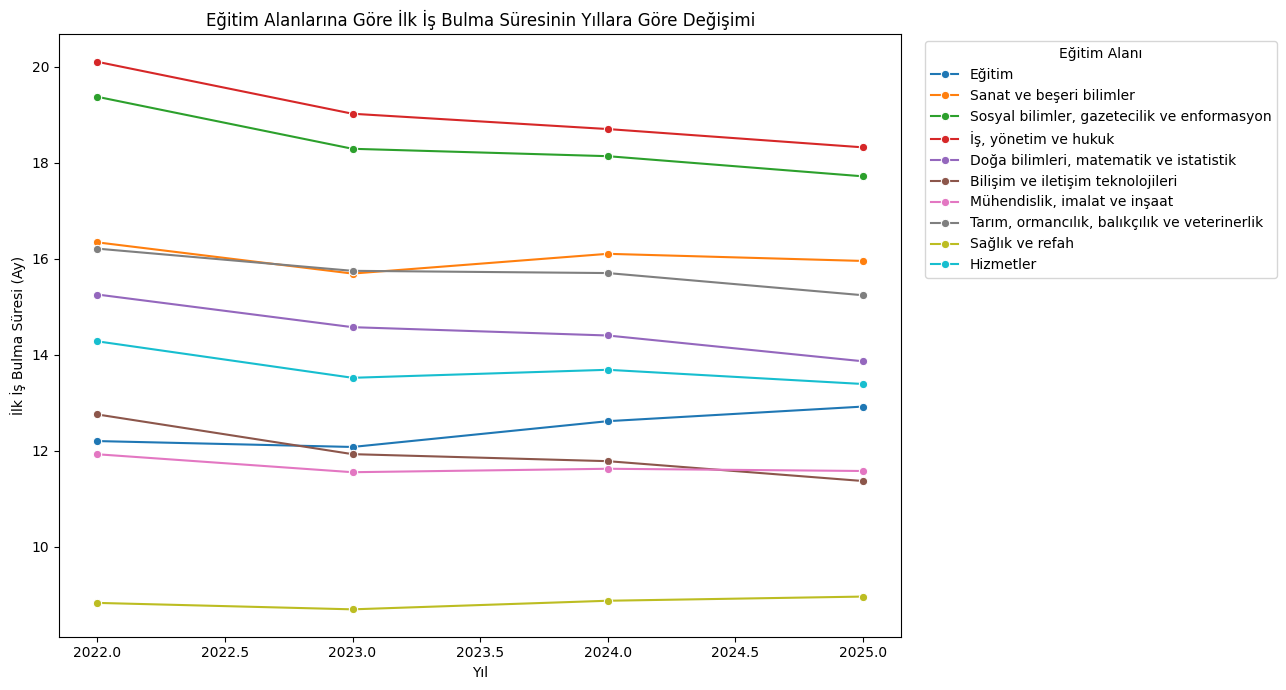

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

toplam_ilk_is = ilk_is_analiz[
    ilk_is_analiz["Cinsiyet"] == "Toplam"
]

plt.figure(figsize=(13, 7))

sns.lineplot(
    data=toplam_ilk_is,
    x="Yıl",
    y="İlk İş Bulma Süresi (Ay)",
    hue="Eğitim Alanı",
    marker="o"
)

plt.title("Eğitim Alanlarına Göre İlk İş Bulma Süresinin Yıllara Göre Değişimi")
plt.xlabel("Yıl")
plt.ylabel("İlk İş Bulma Süresi (Ay)")
plt.legend(title="Eğitim Alanı", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "egitim_alani_ilk_is_bulma_trendi.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 16.4. İlk İş Bulma Süresi En Kısa ve En Uzun Olan Eğitim Alanları

Eğitim alanlarının iş gücü piyasasına geçiş süreleri karşılaştırılarak ilk işini bulma süresi en kısa ve en uzun olan alanlar belirlenmiştir. Bu analizde 2025 yılı toplam mezun verileri esas alınmıştır.

In [ ]:
ilk_is_2025 = ilk_is_analiz[
    (ilk_is_analiz["Yıl"] == 2025) &
    (ilk_is_analiz["Cinsiyet"] == "Toplam")
].copy()

ilk_is_siralama = ilk_is_2025.sort_values(
    "İlk İş Bulma Süresi (Ay)",
    ascending=True
)

print("İlk iş bulma süresi en kısa olan 5 eğitim alanı:")
display(ilk_is_siralama.head(5))

print("İlk iş bulma süresi en uzun olan 5 eğitim alanı:")
display(ilk_is_siralama.tail(5).sort_values(
    "İlk İş Bulma Süresi (Ay)",
    ascending=False
))

ilk_is_siralama.to_csv(
    TABLE_DIR / "2025_ilk_is_bulma_suresi_siralama.csv",
    index=False,
    encoding="utf-8-sig"
)

İlk iş bulma süresi en kısa olan 5 eğitim alanı:


,Eğitim Alanı,Yıl,Cinsiyet,İlk İş Bulma Süresi (Ay)
105,Sağlık ve refah,2025,Toplam,8.959275
69,Bilişim ve iletişim teknolojileri,2025,Toplam,11.366875
81,"Mühendislik, imalat ve inşaat",2025,Toplam,11.575634
9,Eğitim,2025,Toplam,12.917756
117,Hizmetler,2025,Toplam,13.388172


İlk iş bulma süresi en uzun olan 5 eğitim alanı:


,Eğitim Alanı,Yıl,Cinsiyet,İlk İş Bulma Süresi (Ay)
45,"İş, yönetim ve hukuk",2025,Toplam,18.318766
33,"Sosyal bilimler, gazetecilik ve enformasyon",2025,Toplam,17.714818
21,Sanat ve beşeri bilimler,2025,Toplam,15.951799
93,"Tarım, ormancılık, balıkçılık ve veterinerlik",2025,Toplam,15.237539
57,"Doğa bilimleri, matematik ve istatistik",2025,Toplam,13.861350


## 16.5. Yıllara Göre İlk İş Bulma Süresi İstatistikleri

Bu analizde, 2022-2025 yılları arasında yükseköğretim mezunlarının ilk işlerini bulma süreleri yıllara göre değerlendirilmiştir. Ortalama ve medyan değerler kullanılarak genel eğilim incelenmiş; minimum ve maksimum değerler aracılığıyla eğitim alanları arasındaki süre farklılıkları ortaya konulmuştur.

In [ ]:

ilk_is_df = ek_istihdam_temiz[
    "yuksekogretim_ilk_is_suresi"
].copy()

ilk_is_yillari = [2022, 2023, 2024, 2025]
cinsiyetler = ["Toplam", "Erkek", "Kadın"]

ilk_is_sonuclar = []

for satir_indeksi in range(4, len(ilk_is_df)):
    alan = ilk_is_df.iloc[satir_indeksi, 0]

    if pd.isna(alan):
        continue

    alan = str(alan).replace("\r", "\n").split("\n")[0].strip()

    if alan in ["", "."]:
        continue

    for yil_indeksi, yil in enumerate(ilk_is_yillari):
        for cinsiyet_indeksi, cinsiyet in enumerate(cinsiyetler):
            sutun_indeksi = 1 + yil_indeksi * 3 + cinsiyet_indeksi

            if sutun_indeksi >= ilk_is_df.shape[1]:
                continue

            deger = ilk_is_df.iloc[satir_indeksi, sutun_indeksi]

            if pd.isna(deger):
                continue

            try:
                sayi = float(str(deger).strip().replace(",", "."))
            except (ValueError, TypeError):
                continue

            if 0 <= sayi <= 120:
                ilk_is_sonuclar.append({
                    "Eğitim Alanı": alan,
                    "Yıl": yil,
                    "Cinsiyet": cinsiyet,
                    "İlk İş Bulma Süresi (Ay)": sayi
                })

ilk_is_analiz = pd.DataFrame(ilk_is_sonuclar)

ilk_is_toplam = ilk_is_analiz[
    ilk_is_analiz["Cinsiyet"] == "Toplam"
].copy()

ilk_is_yillik_ozet = (
    ilk_is_toplam.groupby("Yıl")["İlk İş Bulma Süresi (Ay)"]
    .agg(["mean", "median", "min", "max"])
    .reset_index()
    .round(2)
)

ilk_is_yillik_ozet.columns = [
    "Yıl",
    "Ortalama Süre (Ay)",
    "Medyan Süre (Ay)",
    "En Kısa Süre (Ay)",
    "En Uzun Süre (Ay)"
]

print("Yıllara Göre İlk İş Bulma Süresi İstatistikleri:")
display(ilk_is_yillik_ozet)

ilk_is_yillik_ozet.to_csv(
    TABLE_DIR / "yillara_gore_ilk_is_bulma_suresi_ozeti.csv",
    index=False,
    encoding="utf-8-sig"
)


Yıllara Göre İlk İş Bulma Süresi İstatistikleri:


,Yıl,Ortalama Süre (Ay),Medyan Süre (Ay),En Kısa Süre (Ay),En Uzun Süre (Ay)
0,2022,14.73,14.77,8.83,20.10
1,2023,14.11,14.04,8.69,19.02
2,2024,14.16,14.04,8.87,18.70
3,2025,13.93,13.62,8.96,18.32


## 16.6. Lisans Mezunlarının Bölümlere Göre Kayıtlı İstihdam Oranlarının Analizi

Bu bölümde, 2022-2025 yılları arasında lisans programlarından mezun olan bireylerin bölümlere göre kayıtlı istihdam oranları incelenmiştir. Veriler düzenlenerek yıllara ve eğitim programlarına göre analiz edilmiş, bölümler arasındaki istihdam farklılıkları görselleştirilmiştir.

In [ ]:
istihdam_oran_df = ek_istihdam_tablolari[
    "yuksekogretim_istihdam_oranlari"
].copy()

istihdam_yillari = [2022, 2023, 2024, 2025]

istihdam_sonuclari = []

for satir_indeksi in range(3, len(istihdam_oran_df)):

    bolum = istihdam_oran_df.iloc[satir_indeksi, 0]

    if pd.isna(bolum):
        continue

    bolum = str(bolum).replace("\r", "\n").split("\n")[0].strip()

    if not bolum or bolum == ".":
        continue

    for sutun_indeksi, yil in enumerate(istihdam_yillari, start=1):

        deger = istihdam_oran_df.iloc[satir_indeksi, sutun_indeksi]

        if pd.isna(deger):
            continue

        deger_metni = str(deger).strip()

        if deger_metni in ["", ".", "-", "nan", "None"]:
            continue

        try:
            sayi = float(deger_metni)
        except (ValueError, TypeError):
            continue

        if abs(sayi) >= 1e10:
            basamak_sayisi = len(str(int(abs(sayi))))
            sayi = sayi / (10 ** (basamak_sayisi - 2))

        istihdam_sonuclari.append({
            "Bölüm": bolum,
            "Yıl": yil,
            "Kayıtlı İstihdam Oranı": sayi
        })

istihdam_oran_analiz = pd.DataFrame(istihdam_sonuclari)

print("Düzenlenmiş veri boyutu:", istihdam_oran_analiz.shape)

print("\nİlk 10 kayıt:")
display(istihdam_oran_analiz.head(10))

print("\nİstatistiksel özet:")
display(
    istihdam_oran_analiz["Kayıtlı İstihdam Oranı"].describe().round(2)
)

print("\n100'den büyük veya 0'dan küçük değerler:")
display(
    istihdam_oran_analiz[
        (istihdam_oran_analiz["Kayıtlı İstihdam Oranı"] > 100) |
        (istihdam_oran_analiz["Kayıtlı İstihdam Oranı"] < 0)
    ]
)

print("\nYıllara göre toplam istihdam oranı:")
toplam_istihdam = istihdam_oran_analiz[
    istihdam_oran_analiz["Bölüm"].str.lower() == "toplam"
].copy()

display(toplam_istihdam)

Düzenlenmiş veri boyutu: (862, 3)

İlk 10 kayıt:


,Bölüm,Yıl,Kayıtlı İstihdam Oranı
0,Toplam,2022,75.149441
1,Toplam,2023,75.634041
2,Toplam,2024,75.030257
3,Toplam,2025,73.926505
4,Tıp,2022,95.100663
5,Tıp,2023,95.257388
6,Tıp,2024,96.414088
7,Tıp,2025,95.478731
8,Özel eğitim öğretmenliği,2022,96.069203
9,Özel eğitim öğretmenliği,2023,96.175682



İstatistiksel özet:


,Kayıtlı İstihdam Oranı
count,862.00
mean,73.87
std,9.83
min,36.59
25%,68.02
50%,73.65
75%,80.70
max,96.41



100'den büyük veya 0'dan küçük değerler:


,Bölüm,Yıl,Kayıtlı İstihdam Oranı



Yıllara göre toplam istihdam oranı:


,Bölüm,Yıl,Kayıtlı İstihdam Oranı
0,Toplam,2022,75.149441
1,Toplam,2023,75.634041
2,Toplam,2024,75.030257
3,Toplam,2025,73.926505


## 16.7. Toplam kayıtlı istihdam oranının yıllara göre değişimi

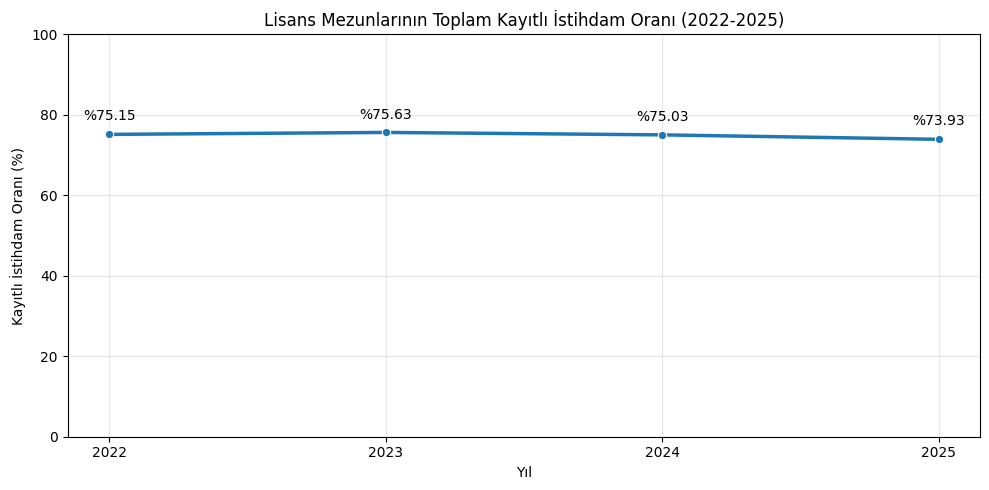

In [ ]:
toplam_istihdam = istihdam_oran_analiz[
    istihdam_oran_analiz["Bölüm"].str.lower() == "toplam"
].copy()

plt.figure(figsize=(10, 5))

ax = sns.lineplot(
    data=toplam_istihdam,
    x="Yıl",
    y="Kayıtlı İstihdam Oranı",
    marker="o",
    linewidth=2.5
)

for _, satir in toplam_istihdam.iterrows():
    plt.annotate(
        f"%{satir['Kayıtlı İstihdam Oranı']:.2f}",
        (satir["Yıl"], satir["Kayıtlı İstihdam Oranı"]),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center"
    )

plt.title("Lisans Mezunlarının Toplam Kayıtlı İstihdam Oranı (2022-2025)")
plt.xlabel("Yıl")
plt.ylabel("Kayıtlı İstihdam Oranı (%)")
plt.xticks([2022, 2023, 2024, 2025])
plt.ylim(0, 100)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "toplam_lisans_istihdam_orani.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 16.8. 2025 yılında istihdam oranı en yüksek 15 bölüm

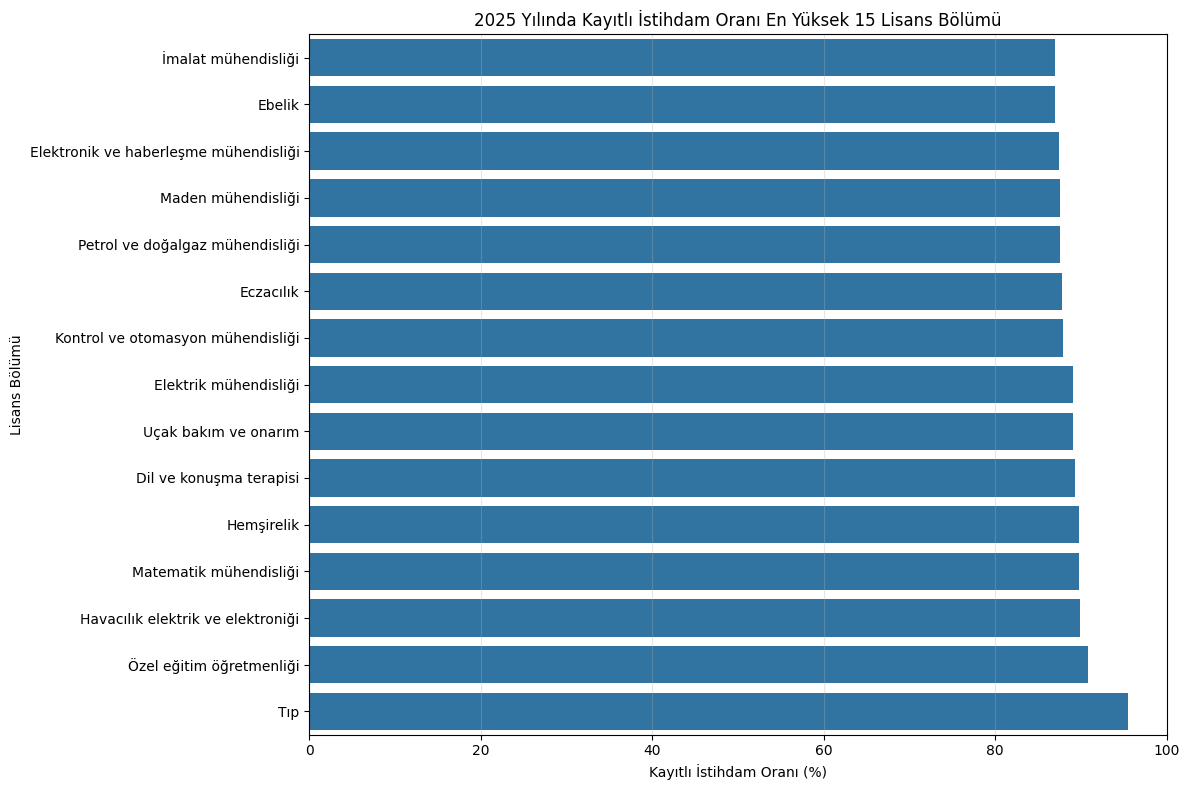

,Bölüm,Yıl,Kayıtlı İstihdam Oranı
0,Tıp,2025,95.48
1,Özel eğitim öğretmenliği,2025,90.84
2,Havacılık elektrik ve elektroniği,2025,89.92
3,Matematik mühendisliği,2025,89.80
4,Hemşirelik,2025,89.76
5,Dil ve konuşma terapisi,2025,89.27
6,Uçak bakım ve onarım,2025,89.09
7,Elektrik mühendisliği,2025,89.08
8,Kontrol ve otomasyon mühendisliği,2025,87.95
9,Eczacılık,2025,87.74


In [ ]:
bolum_2025 = istihdam_oran_analiz[
    (istihdam_oran_analiz["Yıl"] == 2025) &
    (istihdam_oran_analiz["Bölüm"].str.lower() != "toplam")
].copy()

bolum_2025 = bolum_2025.sort_values(
    "Kayıtlı İstihdam Oranı",
    ascending=False
)

en_yuksek_15 = bolum_2025.head(15).sort_values(
    "Kayıtlı İstihdam Oranı",
    ascending=True
)

plt.figure(figsize=(12, 8))

sns.barplot(
    data=en_yuksek_15,
    x="Kayıtlı İstihdam Oranı",
    y="Bölüm",
    errorbar=None
)

plt.title("2025 Yılında Kayıtlı İstihdam Oranı En Yüksek 15 Lisans Bölümü")
plt.xlabel("Kayıtlı İstihdam Oranı (%)")
plt.ylabel("Lisans Bölümü")
plt.xlim(0, 100)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "istihdam_orani_en_yuksek_15_bolum.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

display(
    bolum_2025.head(15).reset_index(drop=True).round(2)
)

## 16.9. 2025 yılında istihdam oranı en düşük 15 bölüm

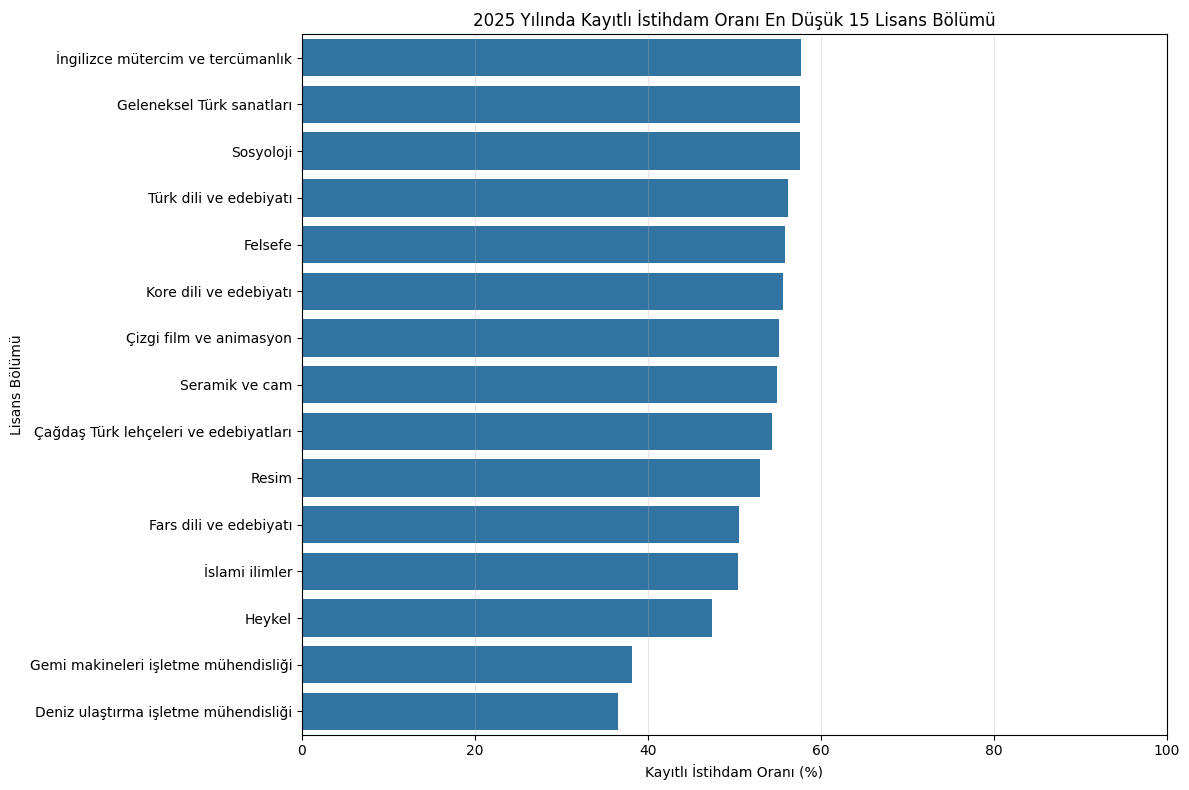

,Bölüm,Yıl,Kayıtlı İstihdam Oranı
0,İngilizce mütercim ve tercümanlık,2025,57.72
1,Geleneksel Türk sanatları,2025,57.65
2,Sosyoloji,2025,57.62
3,Türk dili ve edebiyatı,2025,56.25
4,Felsefe,2025,55.90
5,Kore dili ve edebiyatı,2025,55.59
6,Çizgi film ve animasyon,2025,55.14
7,Seramik ve cam,2025,54.95
8,Çağdaş Türk lehçeleri ve edebiyatları,2025,54.35
9,Resim,2025,52.96


In [ ]:
en_dusuk_15 = bolum_2025.tail(15).sort_values(
    "Kayıtlı İstihdam Oranı",
    ascending=False
)

plt.figure(figsize=(12, 8))

sns.barplot(
    data=en_dusuk_15,
    x="Kayıtlı İstihdam Oranı",
    y="Bölüm",
    errorbar=None
)

plt.title("2025 Yılında Kayıtlı İstihdam Oranı En Düşük 15 Lisans Bölümü")
plt.xlabel("Kayıtlı İstihdam Oranı (%)")
plt.ylabel("Lisans Bölümü")
plt.xlim(0, 100)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "istihdam_orani_en_dusuk_15_bolum.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

display(
    en_dusuk_15.reset_index(drop=True).round(2)
)

## 16.10. En yüksek istihdam oranına sahip 10 bölümün yıllara göre değişimi

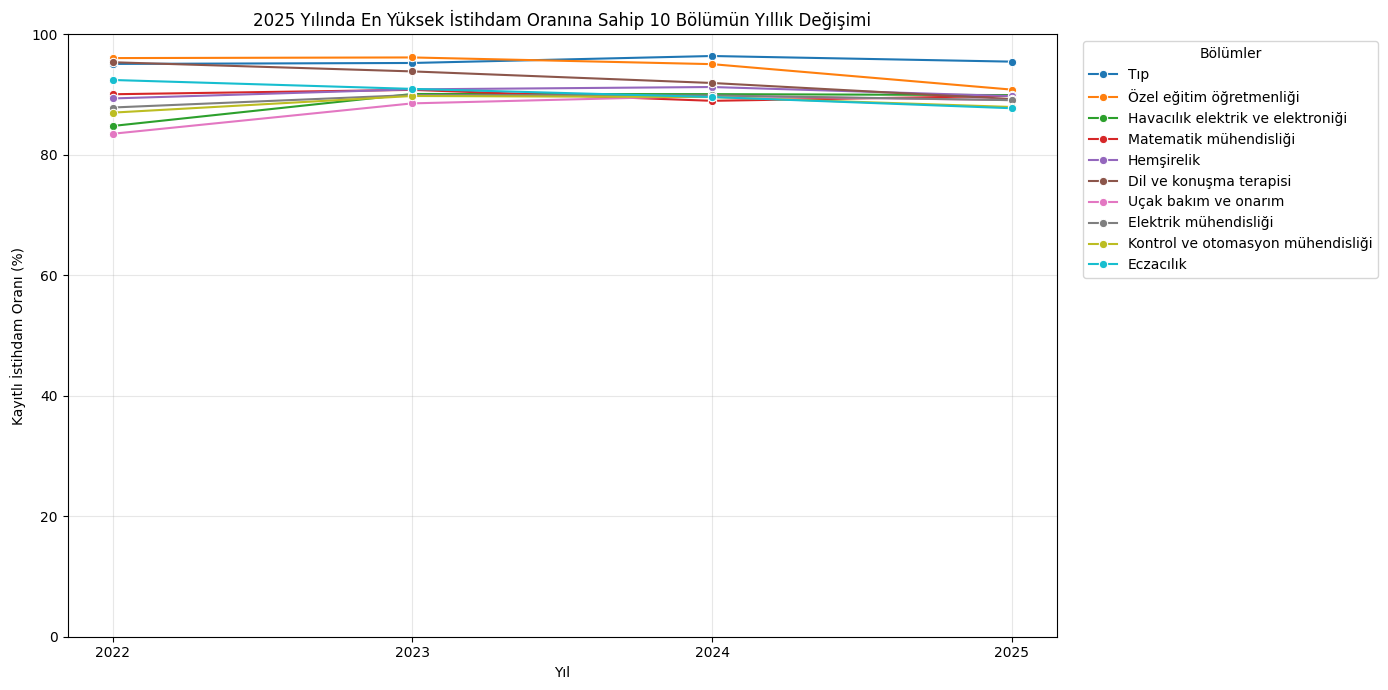

In [ ]:
ilk_10_bolum = bolum_2025.head(10)["Bölüm"].tolist()

ilk_10_yillik = istihdam_oran_analiz[
    istihdam_oran_analiz["Bölüm"].isin(ilk_10_bolum)
].copy()

plt.figure(figsize=(14, 7))

sns.lineplot(
    data=ilk_10_yillik,
    x="Yıl",
    y="Kayıtlı İstihdam Oranı",
    hue="Bölüm",
    marker="o"
)

plt.title("2025 Yılında En Yüksek İstihdam Oranına Sahip 10 Bölümün Yıllık Değişimi")
plt.xlabel("Yıl")
plt.ylabel("Kayıtlı İstihdam Oranı (%)")
plt.xticks([2022, 2023, 2024, 2025])
plt.ylim(0, 100)
plt.grid(alpha=0.3)
plt.legend(
    title="Bölümler",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "ilk_10_bolum_istihdam_trendi.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
istihdam_oran_analiz.to_csv(
    TABLE_DIR / "bolumlere_gore_kayitli_istihdam_oranlari.csv",
    index=False,
    encoding="utf-8-sig"
)

bolum_2025.to_csv(
    TABLE_DIR / "2025_bolum_istihdam_siralamasi.csv",
    index=False,
    encoding="utf-8-sig"
)

toplam_istihdam.to_csv(
    TABLE_DIR / "yillara_gore_toplam_istihdam_orani.csv",
    index=False,
    encoding="utf-8-sig"
)

print("5.1 istihdam oranı analizleri ve tabloları kaydedildi.")

5.1 istihdam oranı analizleri ve tabloları kaydedildi.


## 17. İstanbul mezun nüfusu ve genel işgücü göstergelerinin birlikte incelenmesi
İstanbul'daki yükseköğretim mezunu nüfusu ile istihdam ve işsizlik oranları yıllara göre birleştirilerek karşılaştırılmıştır. Farklı ölçü birimlerine sahip göstergeler çift eksenli grafik üzerinde görselleştirilmiştir. Böylece mezun nüfusu ile genel işgücü göstergelerinin yıllar içerisindeki değişimleri birlikte incelenmiştir.

In [ ]:
if "istanbul_yuksekogretim_yillik" in globals() and istanbul_isgucu is not None:
    mezun_serisi = istanbul_yuksekogretim_yillik[["Yıl", "Toplam Yükseköğretim Mezunu"]].copy()
    mezun_isgucu = mezun_serisi.merge(istanbul_isgucu, on="Yıl", how="inner")
    display(mezun_isgucu)
    mezun_isgucu.to_csv(TABLE_DIR / "istanbul_mezun_isgucu_karsilastirmasi.csv", index=False, encoding="utf-8-sig")

    fig, ax1 = plt.subplots(figsize=(11, 6))
    ax1.plot(mezun_isgucu["Yıl"], mezun_isgucu["Toplam Yükseköğretim Mezunu"], marker="o")
    ax1.set_xlabel("Yıl")
    ax1.set_ylabel("Yükseköğretim mezunu nüfus (kişi)")
    ax1.set_title("İstanbul'da Yükseköğretim Mezunu Nüfusu ve İşgücü Göstergeleri")
    ax2 = ax1.twinx()
    ax2.plot(mezun_isgucu["Yıl"], mezun_isgucu["İstihdam Oranı (%)"], marker="s")
    ax2.plot(mezun_isgucu["Yıl"], mezun_isgucu["İşsizlik Oranı (%)"], marker="^")
    ax2.set_ylabel("Oran (%)")
    fig.tight_layout()
    plt.savefig(FIGURE_DIR / "mezun_nufusu_isgucu_karsilastirma.png", dpi=200)
    plt.show()

## 18. Ek tanımlayıcı analizler: Yükseköğretim Mezunlarının Yaş ve Cinsiyete Göre İncelenmesi

Yükseköğretim mezunlarına ilişkin yaş ve cinsiyet verileri incelenmiş, veri setinin sütunları, ilk kayıtları ve boyutu kontrol edilmiştir. Bu inceleme, mezun nüfusunun demografik dağılımını değerlendirmek amacıyla yapılmıştır.

In [ ]:

if yuksekogretim_yas is not None:
    print("Veri setinin boyutu:", yuksekogretim_yas.shape)
    print("\nSütunlar:")
    print(yuksekogretim_yas.columns.tolist())

    print("\nİlk 10 kayıt:")
    display(yuksekogretim_yas.head(10))

    print("\nEksik değer sayıları:")
    display(yuksekogretim_yas.isna().sum().to_frame("Eksik Sayı"))

    print("\nCinsiyet dağılımı:")
    if "Cinsiyet" in yuksekogretim_yas.columns:
        display(yuksekogretim_yas["Cinsiyet"].value_counts(dropna=False))

    print("\nYaş grubu dağılımı:")
    if "Yaş Grubu" in yuksekogretim_yas.columns:
        display(yuksekogretim_yas["Yaş Grubu"].value_counts(dropna=False))


Veri setinin boyutu: (24, 16)

Sütunlar:
['REF_AREA', 'Coğrafi Kapsam', 'FREQ', 'Gözlem Sıklığı', 'EGITIM_SEVIYESI', 'Eğitim Seviyesi', 'CINSIYET', 'Cinsiyet (DESC)', 'INDICATOR', 'İstatistiksel Gösterge', 'DUZEY_SEVIYE', 'Düzey Seviye', 'YAS_GRUP', 'Yaş Grubu', 'Zaman (TIME_PERIOD)', 'Gözlem Değeri']

İlk 10 kayıt:


,REF_AREA,Coğrafi Kapsam,FREQ,Gözlem Sıklığı,EGITIM_SEVIYESI,Eğitim Seviyesi,CINSIYET,Cinsiyet (DESC),INDICATOR,İstatistiksel Gösterge,DUZEY_SEVIYE,Düzey Seviye,YAS_GRUP,Yaş Grubu,Zaman (TIME_PERIOD),Gözlem Değeri
0,TR,Türkiye,A,Yıllık,5,Yükseköğretim,1,Erkek,E_YOYAS,Cinsiyet ve yaş grubuna göre yükseköğretim mez...,0,TR,Y25T29,25-29,2025,"9,18514817001647"
1,TR,Türkiye,A,Yıllık,5,Yükseköğretim,1,Erkek,E_YOYAS,Cinsiyet ve yaş grubuna göre yükseköğretim mez...,0,TR,Y30T34,30-34,2025,"9,24817221793846"
2,TR,Türkiye,A,Yıllık,5,Yükseköğretim,1,Erkek,E_YOYAS,Cinsiyet ve yaş grubuna göre yükseköğretim mez...,0,TR,Y35T39,35-39,2025,"8,1695380757824"
3,TR,Türkiye,A,Yıllık,5,Yükseköğretim,1,Erkek,E_YOYAS,Cinsiyet ve yaş grubuna göre yükseköğretim mez...,0,TR,Y40T44,40-44,2025,"6,66772130105569"
4,TR,Türkiye,A,Yıllık,5,Yükseköğretim,1,Erkek,E_YOYAS,Cinsiyet ve yaş grubuna göre yükseköğretim mez...,0,TR,Y45T49,45-49,2025,"5,35765794396533"
5,TR,Türkiye,A,Yıllık,5,Yükseköğretim,1,Erkek,E_YOYAS,Cinsiyet ve yaş grubuna göre yükseköğretim mez...,0,TR,Y50T54,50-54,2025,"4,1333389028566"
6,TR,Türkiye,A,Yıllık,5,Yükseköğretim,1,Erkek,E_YOYAS,Cinsiyet ve yaş grubuna göre yükseköğretim mez...,0,TR,Y55T59,55-59,2025,"2,93476009090365"
7,TR,Türkiye,A,Yıllık,5,Yükseköğretim,1,Erkek,E_YOYAS,Cinsiyet ve yaş grubuna göre yükseköğretim mez...,0,TR,Y60T64,60-64,2025,"2,24727441455091"
8,TR,Türkiye,A,Yıllık,5,Yükseköğretim,1,Erkek,E_YOYAS,Cinsiyet ve yaş grubuna göre yükseköğretim mez...,0,TR,Y65T69,65-69,2025,"1,6590240953382"
9,TR,Türkiye,A,Yıllık,5,Yükseköğretim,1,Erkek,E_YOYAS,Cinsiyet ve yaş grubuna göre yükseköğretim mez...,0,TR,Y70T74,70-74,2025,"1,24510596958815"



Eksik değer sayıları:


,Eksik Sayı
REF_AREA,0
Coğrafi Kapsam,0
FREQ,0
Gözlem Sıklığı,0
EGITIM_SEVIYESI,0
Eğitim Seviyesi,0
CINSIYET,0
Cinsiyet (DESC),0
INDICATOR,0
İstatistiksel Gösterge,0



Cinsiyet dağılımı:

Yaş grubu dağılımı:


,count
Yaş Grubu,
25-29,2
30-34,2
35-39,2
40-44,2
45-49,2
50-54,2
55-59,2
60-64,2
65-69,2


## 18.2. Yaş Gruplarına ve Cinsiyete Göre Yükseköğretim Mezunlarının Dağılımı

Bu bölümde 2025 yılı Türkiye yükseköğretim mezunu nüfusunun yaş gruplarına ve cinsiyetlerine göre dağılımı incelenmiştir. Kadın ve erkek mezunların yaş gruplarındaki payları karşılaştırılarak demografik dağılım değerlendirilmiştir. Veri setinin Türkiye geneline ait olduğu dikkate alınarak sonuçlar İstanbul'a özelmiş gibi yorumlanmamıştır.

In [ ]:
yas_analiz = yuksekogretim_yas.copy()

yas_analiz["Gözlem Değeri"] = pd.to_numeric(
    yas_analiz["Gözlem Değeri"]
    .astype(str)
    .str.replace(",", ".", regex=False),
    errors="coerce"
)

yas_analiz["Zaman (TIME_PERIOD)"] = pd.to_numeric(
    yas_analiz["Zaman (TIME_PERIOD)"],
    errors="coerce"
)

yas_analiz = yas_analiz[
    yas_analiz["Zaman (TIME_PERIOD)"] == 2025
].copy()

yas_sirasi = [
    "25-29", "30-34", "35-39",
    "40-44", "45-49", "50-54",
    "55-59", "60-64", "65-69",
    "70-74", "75-79", "80+"
]

yas_analiz["Yaş Grubu"] = yas_analiz["Yaş Grubu"].astype(str).str.strip()

yas_analiz = yas_analiz.dropna(
    subset=["Gözlem Değeri", "Yaş Grubu", "Cinsiyet (DESC)"]
)

yas_pivot = yas_analiz.pivot_table(
    index="Yaş Grubu",
    columns="Cinsiyet (DESC)",
    values="Gözlem Değeri",
    aggfunc="sum"
).reindex(yas_sirasi)

print("Analiz edilen kayıt sayısı:", len(yas_analiz))
print("Sayısal dönüşüm sonrası eksik değer:", yas_analiz["Gözlem Değeri"].isna().sum())

display(yas_pivot.round(2))

Analiz edilen kayıt sayısı: 24
Sayısal dönüşüm sonrası eksik değer: 0


Cinsiyet (DESC),Erkek,Kadın
Yaş Grubu,,
25-29,9.19,11.77
30-34,9.25,10.11
35-39,8.17,7.83
40-44,6.67,5.95
45-49,5.36,4.45
50-54,4.13,2.82
55-59,2.93,1.82
60-64,2.25,1.19
65-69,1.66,0.89


## 18.3. Grafik 1 – Yaş gruplarına göre cinsiyet karşılaştırması

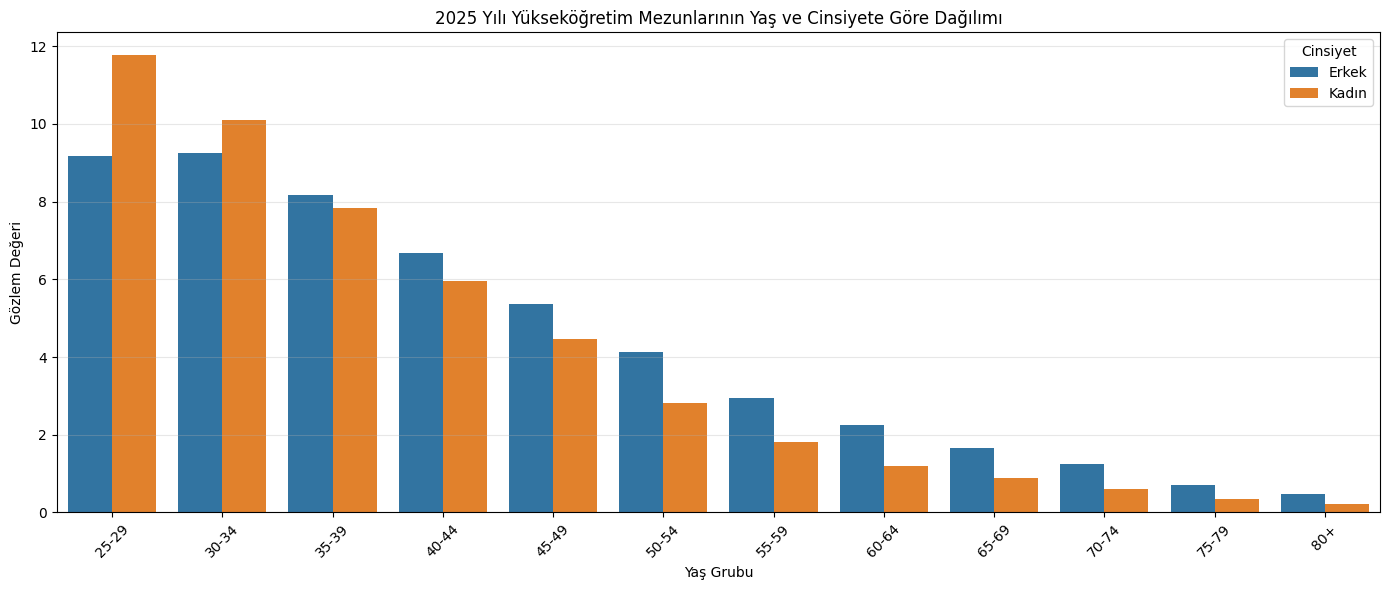

In [ ]:
plt.figure(figsize=(14, 6))

sns.barplot(
    data=yas_analiz,
    x="Yaş Grubu",
    y="Gözlem Değeri",
    hue="Cinsiyet (DESC)",
    order=yas_sirasi,
    errorbar=None
)

plt.title("2025 Yılı Yükseköğretim Mezunlarının Yaş ve Cinsiyete Göre Dağılımı")
plt.xlabel("Yaş Grubu")
plt.ylabel("Gözlem Değeri")
plt.xticks(rotation=45)
plt.legend(title="Cinsiyet")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "yuksekogretim_yas_cinsiyet_dagilimi.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 18.4. Grafik 2 – Yaş gruplarına göre toplam dağılım

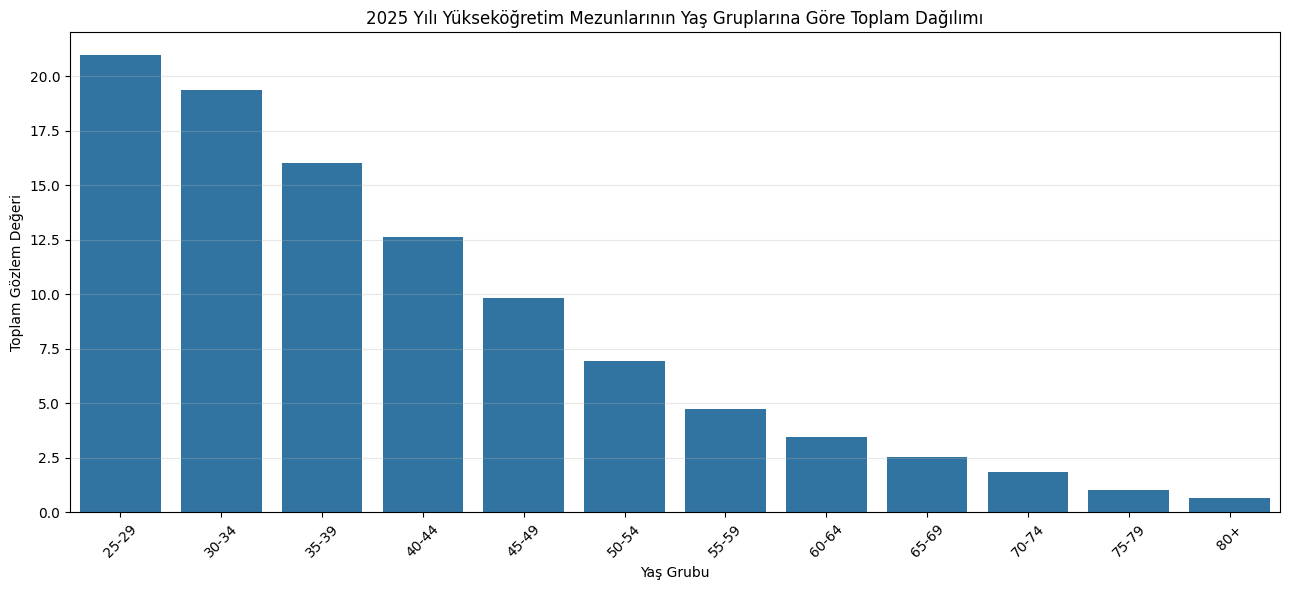

In [ ]:
yas_toplam = (
    yas_analiz.groupby("Yaş Grubu", as_index=False)["Gözlem Değeri"]
    .sum()
)

yas_toplam["Yaş Grubu"] = pd.Categorical(
    yas_toplam["Yaş Grubu"],
    categories=yas_sirasi,
    ordered=True
)

yas_toplam = yas_toplam.sort_values("Yaş Grubu")

plt.figure(figsize=(13, 6))

sns.barplot(
    data=yas_toplam,
    x="Yaş Grubu",
    y="Gözlem Değeri",
    errorbar=None
)

plt.title("2025 Yılı Yükseköğretim Mezunlarının Yaş Gruplarına Göre Toplam Dağılımı")
plt.xlabel("Yaş Grubu")
plt.ylabel("Toplam Gözlem Değeri")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "yuksekogretim_yas_toplam_dagilimi.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 18.5. Yaş Grupları ve Cinsiyete Göre İstatistiksel Değerlendirme

Bu bölümde, yükseköğretim mezunlarının yaş gruplarına ve cinsiyete göre dağılımları istatistiksel ölçütler kullanılarak değerlendirilmiştir. Ortalama, medyan, minimum ve maksimum değerler aracılığıyla cinsiyet grupları arasındaki farklılıklar incelenmiştir.

In [ ]:

yas_cinsiyet_ozet = (
    yas_analiz.groupby("Cinsiyet (DESC)")["Gözlem Değeri"]
    .agg(["mean", "median", "min", "max", "sum"])
    .round(3)
)

yas_cinsiyet_ozet.columns = [
    "Ortalama",
    "Medyan",
    "Minimum",
    "Maksimum",
    "Toplam"
]

print("Cinsiyete Göre İstatistiksel Özet:")
display(yas_cinsiyet_ozet)


Cinsiyete Göre İstatistiksel Özet:


,Ortalama,Medyan,Minimum,Maksimum,Toplam
Cinsiyet (DESC),,,,,
Erkek,4.335,3.534,0.470,9.248,52.026
Kadın,3.998,2.320,0.204,11.771,47.974


## 18.6. Yaş Gruplarına Göre Cinsiyet Farklarının İncelenmesi

Bu analizde, her yaş grubundaki kadın ve erkek yükseköğretim mezunlarına ait gözlem değerleri karşılaştırılmıştır. İki cinsiyet arasındaki mutlak fark hesaplanarak yaş grupları bazında farklılaşmanın düzeyi incelenmiştir.

In [ ]:

yas_cinsiyet_fark = yas_pivot.copy()

yas_cinsiyet_fark["Mutlak Fark"] = (
    yas_cinsiyet_fark["Erkek"] - yas_cinsiyet_fark["Kadın"]
).abs()

yas_cinsiyet_fark["Fark Yönü"] = np.where(
    yas_cinsiyet_fark["Erkek"] > yas_cinsiyet_fark["Kadın"],
    "Erkek daha yüksek",
    np.where(
        yas_cinsiyet_fark["Kadın"] > yas_cinsiyet_fark["Erkek"],
        "Kadın daha yüksek",
        "Eşit"
    )
)

print("Yaş Gruplarına Göre Cinsiyet Farkları:")
display(yas_cinsiyet_fark.round(3))

print("\nEn yüksek cinsiyet farkının görüldüğü yaş grubu:")
display(
    yas_cinsiyet_fark.sort_values(
        "Mutlak Fark",
        ascending=False
    ).head(5).round(3)
)

yas_cinsiyet_fark.to_csv(
    TABLE_DIR / "yas_gruplarina_gore_cinsiyet_farklari.csv",
    encoding="utf-8-sig"
)


Yaş Gruplarına Göre Cinsiyet Farkları:


Cinsiyet (DESC),Erkek,Kadın,Mutlak Fark,Fark Yönü
Yaş Grubu,,,,
25-29,9.185,11.771,2.586,Kadın daha yüksek
30-34,9.248,10.107,0.859,Kadın daha yüksek
35-39,8.170,7.827,0.343,Erkek daha yüksek
40-44,6.668,5.952,0.715,Erkek daha yüksek
45-49,5.358,4.452,0.905,Erkek daha yüksek
50-54,4.133,2.824,1.310,Erkek daha yüksek
55-59,2.935,1.816,1.118,Erkek daha yüksek
60-64,2.247,1.190,1.058,Erkek daha yüksek
65-69,1.659,0.890,0.769,Erkek daha yüksek



En yüksek cinsiyet farkının görüldüğü yaş grubu:


Cinsiyet (DESC),Erkek,Kadın,Mutlak Fark,Fark Yönü
Yaş Grubu,,,,
25-29,9.185,11.771,2.586,Kadın daha yüksek
50-54,4.133,2.824,1.310,Erkek daha yüksek
55-59,2.935,1.816,1.118,Erkek daha yüksek
60-64,2.247,1.190,1.058,Erkek daha yüksek
45-49,5.358,4.452,0.905,Erkek daha yüksek


## 19. Sonuçların dışa aktarılması

In [ ]:
for ad, df in temiz_veri_setleri.items():
    guvenli_ad = re.sub(r"[^A-Za-z0-9_-]+", "_", ad)
    df.to_csv(CLEAN_DIR / f"{guvenli_ad}.csv", index=False, encoding="utf-8-sig")

excel_yolu = OUTPUT_DIR / "analiz_tablolari.xlsx"
with pd.ExcelWriter(excel_yolu, engine="openpyxl") as writer:
    kalite_raporu.to_excel(writer, sheet_name="Veri Kalitesi", index=False)
    sutun_sozlugu.to_excel(writer, sheet_name="Veri Sozlugu", index=False)
    if "istanbul_yuksekogretim_yillik" in globals():
        istanbul_yuksekogretim_yillik.to_excel(writer, sheet_name="Istanbul Mezun", index=False)
    if istanbul_isgucu is not None:
        istanbul_isgucu.to_excel(writer, sheet_name="Istanbul Isgucu", index=False)
    if iskur is not None:
        ilce_acik_is.to_excel(writer, sheet_name="Ilce Acik Is", index=False)
        meslek_acik_is.to_excel(writer, sheet_name="Meslek Acik Is", index=False)
        if "kume_profilleri" in globals():
            kume_profilleri.to_excel(writer, sheet_name="Kume Profilleri")

print("Excel raporu oluşturuldu:", excel_yolu)

Excel raporu oluşturuldu: /content/istanbul_universite_istihdam/output/analiz_tablolari.xlsx


In [ ]:
from google.colab import files

for klasor in [FIGURE_DIR, TABLE_DIR, CLEAN_DIR]:
    if klasor.exists():
        print(f"\n{klasor.name} klasöründeki dosyalar:")
        for dosya in sorted(klasor.iterdir()):
            if dosya.is_file():
                print(dosya.name)


grafikler klasöründeki dosyalar:
ilce_meslek_isiharitasi.png
ilcelere_gore_acik_is.png
istanbul_yuksekogretim_trendi.png
kume_profilleri.png
mesleklere_gore_acik_is.png
pca_ilce_kumeleri.png
silhouette_karsilastirma.png

tablolar klasöründeki dosyalar:
istanbul_ilce_kumeleri.csv
istanbul_ilce_meslek_matrisi.csv
istanbul_ilcelere_gore_acik_is.csv
istanbul_kume_profilleri.csv
istanbul_mesleklere_gore_acik_is.csv
istanbul_pca_sonuclari.csv
istanbul_yuksekogretim_yillik.csv
kume_sayisi_degerlendirme.csv
sutun_veri_sozlugu.xlsx
veri_kalite_raporu.xlsx

temiz_veriler klasöründeki dosyalar:
Bitirilen_e_itim_d_zeyine_g_re_n_fusun_da_l_m_TR_DF_BED_NUFUS_DAGILIM_1_0_1_.csv
Bitirilen_e_itim_durumuna_ve_cinsiyete_g_re_n_fus_TR_DF_ULUSAL_EGITIM_ISTATISTIK_BED_NUFUS_1_0_1_.csv
Cinsiyet_ve_ya_grubuna_g_re_y_ksek_retim_mezun_da_l_m_25_ya_TR_DF_E_YOYAS_1_0_1_.csv
_l_d_zeyinde_i_g_c_ne_kat_lma_oran_1___Tablo.csv
_l_d_zeyinde_i_sizlik_oran_1___Tablo.csv
_l_d_zeyinde_istihdam_oran_1___Tablo.csv
egitim_du